# 15 · scikit-learn — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookIA/blob/main/chapitres/ch15_sklearn/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wb.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | 15.Q1 à 15.Q12, 15.R1 à 15.R3, 15.1 à 15.5 | vérifier tes réponses courtes | 🧠 🔁 ✏️ 🧮 | ★ à ★★ | |
| A | 15.9 | Anatomie d'un estimateur : Ridge sur un sinus bruité | 📦 | ★ | 15 |
|  | 15.10 | predict_proba : prédire ce que valent les probabilités de trois classifieurs | 🔮 | ★ | 10 |
|  | 15.11 | Datasets synthétiques, fetch_* et train_test_split stratifié | 📦 | ★ | 15 |
|  | 15.12 | Faire tourner le code de 2018 avec scikit-learn 1.6 | 🐛 | ★★ | 25 |
| B | 15.13 | Clustering avec scikit-learn : KMeans (le coude du livre), DBSCAN et clustering hiérarchique sur deux lunes et sept nuages gaussiens | 📦 | ★★ | 25 |
|  | 15.14 | Transformateurs : test hors de [0, 1] et inverse_transform | 📦 | ★★ | 20 |
|  | 15.15 | PCA de 3D vers 2D et blanchiment | 📦 | ★★ | 20 |
|  | 15.16 | Cinq spirales : quel ensemble les démêle ? | 🔬 | ★★ | 30 |
| C | 15.17 | cross_validate, KFold, StratifiedKFold et RidgeClassifierCV | 📦 | ★★ | 25 |
|  | 15.18 | GridSearchCV : best_params_, cv_results_ et score d'entraînement | 📦 | ★★ | 25 |
|  | 15.19 | RandomizedSearchCV avec des distributions | 📦 | ★★ | 25 |
|  | 15.20 | Grille ou hasard : qui gagne avec 16 essais ? | 🔮 | ★★ | 20 |
|  | 15.21 | Frontières de décision : DecisionBoundaryDisplay et surfaces 3D | 📦 | ★★ | 20 |
|  | 15.22 | Pipeline polynomial + ridge : degré et alpha ensemble | 📦 | ★★★ | 35 |
|  | 15.23 | Lire cv_results_ : carte de chaleur et écarts-types | 📈 | ★★ | 20 |
|  | 15.24 | Refaire l'expérience de fuite du ch. 8 (sélection de features sur du bruit) avec un Pipeline | 🔬 | ★★ | 25 |
| D | 15.25 | Régler le seuil de décision d'un classifieur | 🔬 | ★★★ | 35 |
|  | 15.26 | Classes déséquilibrées : class_weight, rééchantillonnage et la bonne métrique (recall, PR-AUC) | 📦 | ★★★ | 35 |
|  | 15.27 | La même validation croisée pour six familles de modèles scikit-learn : score moyen, écart-type et temps | 📦 | ★★★ | 40 |
|  | 15.28 | ColumnTransformer sur Penguins brut | 📦 | ★★★ | 45 |
|  | 15.29 | Quand scikit-learn refuse un estimateur mylearn | 🐛 | ★★★ | 35 |
|  | 15.30 | Sauvegarder, recharger et versionner un pipeline | 🛠️ | ★★ | 20 |
|  | 15.31 | Défi : prédire le sexe des manchots depuis le fichier brut | 🏆 | ★★★★ | 100 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (CPU, a few minutes); False = full version
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookIA.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookIA")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WB_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wb").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wb").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier du workbook.")

os.environ["WB_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wb  # noqa: E402

cfg = wb.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mylearn = wb.load_mylearn("ref")  # reference implementation

🧪 Deep Learning Workbook : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.13 | numpy 2.1.3 | pandas 2.2.3 | matplotlib 3.10.0 | scikit-learn 1.6.1 | scipy 1.16.3 | torch 2.11.0+cpu | torchvision 0.26.0+cpu
   Device : cpu | Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Utiliser l'interface commune de scikit-learn : hyperparamètres au constructeur, `fit` qui renvoie l'objet, attributs appris suffixés par `_`, `predict`, `decision_function`, `predict_proba`, `transform` et `inverse_transform`.
- Évaluer et régler un modèle : `cross_val_score`, `cross_validate`, `KFold`, `StratifiedKFold`, `GridSearchCV`, `RandomizedSearchCV`, et lire `cv_results_`.
- Enchaîner sans fuite : `Pipeline`, `make_pipeline`, `ColumnTransformer`, noms `étape__paramètre`.
- Moderniser du code ancien, choisir un seuil de décision, traiter des classes déséquilibrées, sauvegarder un pipeline avec ses versions.

**Rappel express.** $\hat p = \sigma(s) = 1/(1 + e^{-s})$ à deux classes, le softmax à $K$ classes ; nombre d'entraînements d'une grille : $\big(\prod_h n_h\big) \times k + 1$ ; probabilité qu'au moins un de $n_{\text{iter}}$ essais au hasard tombe dans le meilleur $q$ : $1 - (1 - q)^{n_{\text{iter}}}$ ; nombre de features polynomiales : $\binom{p + d}{d}$ ; min-max : $x' = (x - m)/(M - m)$. En scikit-learn : `sklearn.model_selection` (validation croisée, recherches, découpage), `sklearn.pipeline`, `sklearn.compose`, `sklearn.preprocessing`, `sklearn.inspection`, `sklearn.calibration` ; `joblib` pour la sauvegarde.

## Partie 0 · Vérifier tes réponses courtes (quiz, rappels, ✏️ 15.1 à 15.4 et 🧮 15.5)

Fais d'abord les quiz, les rappels et les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse courte ici : **la valeur** que tu as trouvée, pas l'expression Python, sinon tu ne vérifies rien. Un nombre : `42` ou `0.3` (en Python, le séparateur décimal est un **point** ; `0,3` sans guillemets serait un couple de deux nombres) ; un vrai ou faux : `True` ou `False` ; un choix : la lettre seule, entre guillemets (`"E"`) ; un nom : une chaîne (`"standardscaler"`) ; plusieurs nombres : une liste (`[4, 7]`). Arrondis comme l'énoncé le demande, et seulement à la fin du calcul. Les réponses pas encore remplies affichent ⏳. Les questions « dans ta copie », la réflexion (🗣️ 15.6, ⚖️ 15.7, 📄 15.8) et l'entretien se corrigent avec `05_solutions.md`.

In [2]:
# The short answers only use the numbers of their statements (02_exercices.md),
# and the defaults of the installed scikit-learn 1.6 where a question asks for one
import inspect
import math
from math import comb

import numpy as np
from scipy.special import expit, softmax
from sklearn.cluster import KMeans
from sklearn.model_selection import KFold, RandomizedSearchCV, train_test_split

# Q6, Q10, Q12, R3: defaults and sizes, read from scikit-learn itself
KMEANS_DEFAULT_K = inspect.signature(KMeans).parameters["n_clusters"].default
RANDOM_DEFAULT_ITER = inspect.signature(RandomizedSearchCV).parameters["n_iter"].default
_, TEST_Q12 = train_test_split(np.arange(125), test_size=0.3, random_state=0)
_, TEST_DEFAULT = train_test_split(np.arange(1000), random_state=0)
LARGEST_FOLD_R3 = max(len(val) for _, val in KFold(5).split(np.arange(1003)))


def fits(n_candidates, k, refit=True):
    """Trainings of a search: each candidate is cross-validated on k folds, plus the final refit."""
    return n_candidates * k + (1 if refit else 0)


# 15.1: the grids of the statement
GRID_151 = {"alpha": [0.01, 0.1, 1, 10], "solver": ["svd", "cholesky", "lsqr"]}
N_CAND_151 = math.prod(len(v) for v in GRID_151.values())
POLY_151 = 5 * 2 * 3                          # degree x interaction_only x alpha
LIST_151 = 3 * 1 + 3 * 2 * 1                  # two dictionaries, each with one kernel

# 15.2: scores of a binary logistic regression, then of a 3-class multinomial one
S_152 = np.array([2.0, -1.0, 0.0, 0.5, -3.2])
P_152 = expit(S_152)


def logit(p):
    return math.log(p / (1 - p))


PRED_152 = [int(s > 0) for s in S_152]        # scikit-learn: class 1 when the score is strictly positive
SOFT_152 = softmax(np.array([2.0, 1.0, -1.0]))

# 15.3: a MinMaxScaler learned on x in [-3, 5] and y in [10, 30], then the line y' = 0.6 x' + 0.25
X_MIN, X_MAX, Y_MIN, Y_MAX = -3.0, 5.0, 10.0, 30.0
A_153, B_153 = 0.6, 0.25


def x_scaled(x):
    return (x - X_MIN) / (X_MAX - X_MIN)


def y_back(y_scaled):
    return Y_MIN + (Y_MAX - Y_MIN) * y_scaled


def line_153(x):
    """The fitted line, in the original units."""
    return y_back(A_153 * x_scaled(x) + B_153)


SLOPE_153 = (line_153(X_MAX) - line_153(X_MIN)) / (X_MAX - X_MIN)

# 15.4: monomials of degree at most d in p variables


def n_poly(p, d, bias=True):
    return comb(p + d, d) - (0 if bias else 1)


SMALLEST_D_154 = next(d for d in range(1, 20) if n_poly(10, d) > 1000)

# 15.5: a 4-minute training, 5 hyperparameters, 5 folds
FITS_155 = 5 ** 5 * 5
DAYS_155 = FITS_155 * 4 / 60 / 24
HALVING_155 = sum(n * r for n, r in zip((81, 27, 9, 3, 1), (1 / 81, 3 / 81, 9 / 81, 27 / 81, 1)))
N_99_155 = math.ceil(math.log(0.01) / math.log(0.95))

**15.Q1 — Coder soi-même ou utiliser une bibliothèque ?**

In [3]:
wb.record("15.Q1a", False, mistakes={"relis le §15.1 : quel chemin le livre choisit-il pour ce chapitre ?": True})
wb.record("15.Q1b", "A", mistakes={"une bibliothèque sait-elle quelles données tu vas lui donner ?": "B",
          "peut-on choisir et régler un modèle sans savoir ce qu'il fait ?": "C",
          "les modèles de scikit-learn ont-ils des arguments à régler ? Relis le §15.4.1": "D"})
wb.record("15.Q1c", True, mistakes={"relis le §15.2 : sur quelles bibliothèques s'appuie scikit-learn ?": False})
wb.record("15.Q1d", "B", mistakes={"relis le §15.2 : à quoi scikit-learn n'est-il pas destiné ?": "A",
          "SciPy fournit-il des réseaux de neurones et le calcul sur GPU ?": "C",
          "seaborn sert-il à entraîner des modèles ?": "D"})

WB_ANSWER {"hash": "864089caf60c119af78b35f86901cae462e28c2083b05956da11600f803f36dc", "id": "15.Q1a", "kind": "bool", "mistakes": {"684826c91301e3ea10b72b0f9d59652d62e66be2f9e896950371febb60fc60b2": "relis le §15.1 : quel chemin le livre choisit-il pour ce chapitre ?"}}
📝 Ex 15.Q1a : réponse enregistrée (bool).
WB_ANSWER {"hash": "22d5e7b90c19c3345c757e06d91fe7bc61917dc72f4c02dac93187fbb0c69f6a", "id": "15.Q1b", "kind": "str", "mistakes": {"7ab9d4a24b3bd3730cbbdc0d2289d7d52e6da17c1e930c4ef3a4a12c639c19a9": "les modèles de scikit-learn ont-ils des arguments à régler ? Relis le §15.4.1", "b975c7515ce69ae5c66bcd651c1fc5ad80e29ee8b25e18f48bd0480b3bcca088": "une bibliothèque sait-elle quelles données tu vas lui donner ?", "ba702d2a3518d6a998ffec5f3d21734f8f404f91e2fb379e23d5cc37f24e36e1": "peut-on choisir et régler un modèle sans savoir ce qu'il fait ?"}}
📝 Ex 15.Q1b : réponse enregistrée (str).
WB_ANSWER {"hash": "7682ce6afe066fe59ceffd5767f4ef8fd58d578bd09a1e660077b50129e0206d", "id": "1

**15.Q2 — Importer proprement et lire une dépréciation**

In [4]:
wb.record("15.Q2a", "B", mistakes={"on a importé le module, pas la classe : quel préfixe faut-il écrire ?": "A",
          "le nom sklearn a-t-il été importé, et Ridge est-il rangé directement sous sklearn ?": "C",
          "linear_model est un module : peut-on l'appeler comme une fonction ?": "D"})
wb.record("15.Q2b", "B", mistakes={"un avertissement arrête-t-il le programme ?": "A",
          "pourrait-on déprécier un argument qui n'a jamais existé ?": "C",
          "relis le §15.3 : que t'annonce un avertissement de dépréciation ?": "D"})
wb.record("15.Q2c", False, mistakes={"relis le paragraphe « Suivre les dépréciations » du §15.3 : que devient un argument déprécié deux versions plus tard ?": True})
wb.record("15.Q2d", "B", mistakes={"masquer l'avertissement empêchera-t-il le code de casser à la version suivante ?": "A",
          "rester sur une vieille version, est-ce une solution durable ?": "C",
          "que se passera-t-il le jour où l'argument sera retiré ?": "D"})
wb.record("15.Q2e", False, mistakes={"relis le §15.3 : quelle version décrit l'adresse « stable » ?": True})

WB_ANSWER {"hash": "e427665d99dcdfad4cd156dee3b45517f141007f14bae07e1a8a5e547c211f35", "id": "15.Q2a", "kind": "str", "mistakes": {"45094da5e763a34261ea1195d9b60b09fdebdacccd8c9b9461435f0954513ad1": "linear_model est un module : peut-on l'appeler comme une fonction ?", "985ec0d8edbf344890fc5347648da38a2d24add2eb970f7a83eaf5bf24a5714a": "le nom sklearn a-t-il été importé, et Ridge est-il rangé directement sous sklearn ?", "a241f1c231ef30635bee1fbe6633a0ba7531d5b060e73b974398711ecd9a12e6": "on a importé le module, pas la classe : quel préfixe faut-il écrire ?"}}
📝 Ex 15.Q2a : réponse enregistrée (str).
WB_ANSWER {"hash": "95a88fcda2c5281cca97460dba0123b37b121c3b62990c0eeca93c2ca5155d3f", "id": "15.Q2b", "kind": "str", "mistakes": {"0fe4baf05ae876e521d28f7025444ae01a0a397719f3d47c1dbc0c21d46affdb": "pourrait-on déprécier un argument qui n'a jamais existé ?", "a11ca33d65973e75b8ce0666e48d7b5296b892538fa722477c3beb15d4e114d4": "relis le §15.3 : que t'annonce un avertissement de dépréciation

**15.Q3 — Hyperparamètres au constructeur, attributs appris avec « _ »**

In [5]:
wb.record("15.Q3a", "B", mistakes={"qui fixe la valeur de alpha : toi, ou l'apprentissage ?": "A",
          "une feature est une colonne des données : alpha en est-il une ?": "C",
          "un label est la réponse attendue d'un exemple : alpha en est-il un ?": "D"})
wb.record("15.Q3b", False, mistakes={"relis le §15.4.2 : que signale le tiret bas à la fin d'un nom d'attribut ?": True})
wb.record("15.Q3c", True, mistakes={"relis le §15.4.1 : que renvoie get_params ?": False})
wb.record("15.Q3d", "B", mistakes={"relis l'encadré sur clone (§15.9.3) : la copie garde-t-elle ce que l'objet a appris ?": "A",
          "clone reçoit-il des données ?": "C",
          "quel objet renvoie clone, et quelle méthode renvoie un dictionnaire ?": "D"})
wb.record("15.Q3e", False, mistakes={"relis le §15.4.1 : le constructeur reçoit-il des données ?": True})

WB_ANSWER {"hash": "08f0c6442dde3827e1526a42e9bcd98948795d2e34ff1626b8f80a949dd7f987", "id": "15.Q3a", "kind": "str", "mistakes": {"18685172a18cc2b78d00fc252dc3bfd69f3c51c46475282b6782b59e10fb7049": "qui fixe la valeur de alpha : toi, ou l'apprentissage ?", "b51eb27f96fe489668fd55f0ba84509d460b54120a96b947b44976e2e227cd24": "un label est la réponse attendue d'un exemple : alpha en est-il un ?", "ee25db3e6fe8737a1eef558d2d3108483d8dbfb3f6625e4f08b247073cbbaf54": "une feature est une colonne des données : alpha en est-il une ?"}}
📝 Ex 15.Q3a : réponse enregistrée (str).
WB_ANSWER {"hash": "e80f2d8af664bee31cfe555b512790fda30a0f2ff2dd94f14713bfa53f508bfc", "id": "15.Q3b", "kind": "bool", "mistakes": {"fe5e567130d050e34fa1d2e3662d62947ffbe8c5e9f297245e484e77efa569c3": "relis le §15.4.2 : que signale le tiret bas à la fin d'un nom d'attribut ?"}}
📝 Ex 15.Q3b : réponse enregistrée (bool).
WB_ANSWER {"hash": "d2c66d8f9b074fe2818bb3816bd55b3591a2d4b6580692c5545f0ea10a1943c0", "id": "15.Q3c", "

**15.Q4 — Ce que renvoient fit et predict**

In [6]:
wb.record("15.Q4a", "C", mistakes={"relis le §15.4.2 : comment peut-on enchaîner Ridge().fit(X, y).predict(X_new) ?": "A",
          "fit reçoit-il de nouvelles données à prédire ?": "B",
          "quelle méthode calcule le score ?": "D"})
wb.record("15.Q4b", "B", mistakes={"relis le §15.4.2 : combien de dimensions doit avoir X, même avec une seule feature ?": "A",
          "une ligne par exemple ou une ligne par feature ?": "C"})
wb.record("15.Q4c", "A", mistakes={"predict renvoie-t-il un tableau en colonnes, ou une valeur par exemple ?": "B",
          "combien d'exemples X_new contient-il, et combien de valeurs predict en renvoie-t-il ?": "C",
          "X_new contient combien d'exemples ?": "D"})
wb.record("15.Q4d", False, mistakes={"relis l'encadré « des données toujours en deux dimensions » (§15.4.3)": True})
wb.record("15.Q4e", False, mistakes={"relis le §15.4.2 : que fait un second appel à fit ?": True})

WB_ANSWER {"hash": "d0baaff77558e371bc0ca94d8b604877cb0b60f09b73dde7815d2b5eae21bf69", "id": "15.Q4a", "kind": "str", "mistakes": {"13048e3868d77c0c6183c1dda35e5a9352f48c28097ebfc33926d9a87972b39b": "relis le §15.4.2 : comment peut-on enchaîner Ridge().fit(X, y).predict(X_new) ?", "4d9107ac6634a8e36fa3d52fa7f84d32176186c3edb3bea107216a8f93286323": "fit reçoit-il de nouvelles données à prédire ?", "520f855d5918b2b94a51433c3d913758e3ef3a3a985cb0562ae007cc3ddbc832": "quelle méthode calcule le score ?"}}
📝 Ex 15.Q4a : réponse enregistrée (str).
WB_ANSWER {"hash": "db47e67a92743fd0a1ccf35affced9248a3c4dd9b5db722986bc6cb9b99aaa04", "id": "15.Q4b", "kind": "str", "mistakes": {"3843ced817e2104e644526e6c1249e8e36b40f8430fea7bec315f8f4e3f693f1": "relis le §15.4.2 : combien de dimensions doit avoir X, même avec une seule feature ?", "39830948a92b848c7e10b1b98262026414892844c4f8ea32e012783f40702603": "une ligne par exemple ou une ligne par feature ?"}}
📝 Ex 15.Q4b : réponse enregistrée (str).
WB_A

**15.Q5 — decision_function ou predict_proba ?**

In [7]:
wb.record("15.Q5a", "A", mistakes={"combien de scores un classifieur binaire renvoie-t-il par exemple ? Relis le tableau du §15.4.4": "B",
          "à deux classes, decision_function renvoie-t-il un score par classe ? Relis l'encadré ⚠️ du §15.4.4": "C",
          "une ligne par exemple, ou une ligne par classe ?": "D"})
wb.record("15.Q5b", "C", mistakes={"predict_proba donne-t-il une seule probabilité par exemple, même à deux classes ?": "A",
          "combien de colonnes faut-il pour que chaque ligne somme à 1 sur toutes les classes ?": "B",
          "une ligne par exemple, ou une ligne par classe ?": "D"})
wb.record("15.Q5c", "C", mistakes={"au-delà de deux classes, combien de scores par exemple ?": "A",
          "combien de classes a ce problème ?": "B",
          "une ligne par exemple, ou une ligne par classe ?": "D"})
wb.record("15.Q5d", float(expit(0.0)), decimals=2, mistakes={"un score nul est-il en faveur d'une classe ou à égalité ? Relis l'encadré sur la sigmoïde": 0.0,
          "que vaut e⁰ ?": 1.0})
wb.record("15.Q5e", False, mistakes={"relis le §15.4.4 : quels classifieurs n'ont pas de predict_proba ?": True})
wb.record("15.Q5f", True, mistakes={"relis le §15.4.4 : comment SVC obtient-il ses probabilités, et que dit la documentation de leur accord avec predict ?": False})

WB_ANSWER {"hash": "a32b8eef24430545306ab571a18387c738599f36ea95a693395195d468ec45ff", "id": "15.Q5a", "kind": "str", "mistakes": {"82624803b06b9d4f15014ba9d17b8c56fea62be358604aaee8b9c5074bf1112a": "une ligne par exemple, ou une ligne par classe ?", "c262c02ed8e0bbda2ba465835a5126933e08f39547ce102d83e186745862f52d": "à deux classes, decision_function renvoie-t-il un score par classe ? Relis l'encadré ⚠️ du §15.4.4", "ff0b6b77562c75d3393ddb4d7becbd7926a267d29b0daac12a2345b1df34386e": "combien de scores un classifieur binaire renvoie-t-il par exemple ? Relis le tableau du §15.4.4"}}
📝 Ex 15.Q5a : réponse enregistrée (str).
WB_ANSWER {"hash": "a69935734a6b27be609c1c2d32b8d520bdf5e527a6fa8b2d9258edb5b23d89f1", "id": "15.Q5b", "kind": "str", "mistakes": {"986b29e85efca9fe5f371d9fbceb5dee4df52a97d78ba3909e6a507f0aea0858": "predict_proba donne-t-il une seule probabilité par exemple, même à deux classes ?", "dcff40c58f12d664f96aba7e173e4f222da9064fb4e0f975b3474cb8f7f3e7a4": "une ligne par exe

**15.Q6 — KMeans : n_clusters, labels_ et choix de k**

In [8]:
wb.record("15.Q6a", KMEANS_DEFAULT_K, mistakes={"relis le §15.5 : quel est le défaut de n_clusters ?": 2,
          "relis le §15.5 : on demande le défaut de n_clusters de KMeans": 10})
wb.record("15.Q6b", False, mistakes={"relis le §15.5 : où KMeans lit-il le nombre de features ?": True})
wb.record("15.Q6c", "B", mistakes={"un clustering voit-il les vraies classes ?": "A",
          "quel attribut donne les centres ?": "C",
          "quel attribut donne l'inertie ?": "D"})
wb.record("15.Q6d", False, mistakes={"relis l'encadré sur l'inertie et la silhouette : quelle valeur de k donne la plus petite inertie possible ?": True})
wb.record("15.Q6e", "B", mistakes={"KMeans affecte-t-il chaque point à un centre, sans exception ?": "A",
          "à qui donne-t-on le nombre de groupes, dans AgglomerativeClustering(n_clusters=3) ?": "C"})

WB_ANSWER {"hash": "cc6356777e734d76639206a5c63d2403f14a5b542ac17d7621c79007403e738d", "id": "15.Q6a", "kind": "int", "magnitude": 0, "mistakes": {"00b8f64fb2225cc8d066b56c9eb34da5894939cd5f52f98dd66af12cf607204f": "relis le §15.5 : quel est le défaut de n_clusters ?", "f1128b1d6fcb56fbfcf3e1951850bef573be35cf4b1daa5fc795eb8064dbc2de": "relis le §15.5 : on demande le défaut de n_clusters de KMeans"}, "sign": 1}
📝 Ex 15.Q6a : réponse enregistrée (int).
WB_ANSWER {"hash": "f39c4fa3257e3965407b67dd62bf166af52d8396b5455eb1a4655757cd7e27a6", "id": "15.Q6b", "kind": "bool", "mistakes": {"a1e806acd0c2bfcc32efc039c356f44c777056c42af6e86dbc4021092632f77a": "relis le §15.5 : où KMeans lit-il le nombre de features ?"}}
📝 Ex 15.Q6b : réponse enregistrée (bool).
WB_ANSWER {"hash": "df333d820f750e09a3420b34f096b6cacbfd3ad9f1481206918e26145b6f5b4b", "id": "15.Q6c", "kind": "str", "mistakes": {"6ac11eab78bfd5dc7bc0dd5a36b66e366b7467b6cf7368117e7d0de4ddf34b63": "quel attribut donne l'inertie ?", "72cc3

**15.Q7 — fit, transform, fit_transform, inverse_transform**

In [9]:
wb.record("15.Q7a", "B", mistakes={"fit sur le test : quelle transformation apprendrait-on ? Relis la règle d'or du §15.6": "A",
          "fit_transform sur le test réapprend-il la transformation ? Relis le §15.6": "C",
          "inverse_transform transforme-t-il, ou revient-il en arrière ?": "D"})
wb.record("15.Q7b", (70 - 20) / (60 - 20), decimals=2, mistakes={"un scaler appris sur l'entraînement ramène-t-il toujours le test dans [0, 1] ?": 1.0,
          "x' = (x − min) / (max − min) : as-tu divisé par l'étendue ?": 50.0,
          "divise par l'étendue max − min, pas par le maximum": 0.83,
          "as-tu retiré le minimum de l'entraînement avant de diviser ?": 1.75,
          "retire le minimum, puis divise par l'étendue max − min": 1.17})
wb.record("15.Q7c", (10 - 20) / (60 - 20), decimals=2, mistakes={"un scaler appris sur l'entraînement ramène-t-il toujours le test dans [0, 1] ?": 0.0,
          "attention au signe : la valeur est sous le minimum de l'entraînement": 0.25,
          "x' = (x − min) / (max − min) : as-tu divisé par l'étendue ?": -10.0,
          "divise par l'étendue max − min, pas par le maximum": -0.17})
wb.record("15.Q7d", 20 + (60 - 20) * 0.75, decimals=1, mistakes={"x = min + (max − min) × x' : as-tu ajouté le minimum ?": 30.0,
          "multiplie par l'étendue, pas par le maximum": 65.0})
wb.record("15.Q7e", False, mistakes={"relis l'encadré ⚠️ du §15.6.1 : quels transformateurs n'ont pas d'inverse ?": True})

WB_ANSWER {"hash": "5fbbe0345e95b692c53a3ffe2514ce7ee389e0c9b06146f7a239437192c319f0", "id": "15.Q7a", "kind": "str", "mistakes": {"5ca79defbbcd687aa861ba66b677994f05ea889c90b1028d67afea025080bd53": "fit sur le test : quelle transformation apprendrait-on ? Relis la règle d'or du §15.6", "bbc5a04604eb2f837a7155ab0d978007dad9c61b46733e5c18d02825b5976574": "inverse_transform transforme-t-il, ou revient-il en arrière ?", "f5ca2fc151fae748e12c3183234048c54c108e8da034d8603e83c610108be206": "fit_transform sur le test réapprend-il la transformation ? Relis le §15.6"}}
📝 Ex 15.Q7a : réponse enregistrée (str).
WB_ANSWER {"alt_coarse": ["60093c5e81d91f4ab214dab01d2fb8bad7b511bc722f2b89f89730f37e07a0ba"], "decimals": 2, "hash": "f9f90d5d45b4c116b53d42ecaf5fe0e92c7c21b58180448e78d2611636b3ed8d", "hash_coarse": "89e3125e29c838aa850003ba927ba4d12e30f143b10cefdd090e273cd481dea7", "id": "15.Q7b", "kind": "float", "magnitude": 0, "mistakes": {"06f1796f5243370ea5a13026086ae8a3cdadaae6b8fb635dcf4aa4fba792

**15.Q8 — Ce que la PCA fait vraiment aux features**

In [10]:
wb.record("15.Q8a", "B", mistakes={"la PCA garde-t-elle des features d'origine ? Relis l'encadré ⚠️ du §15.7": "A",
          "la PCA est-elle linéaire ?": "C",
          "diviser une feature par son écart-type, est-ce une PCA ou une standardisation ?": "D"})
wb.record("15.Q8b", False, mistakes={"relis l'encadré ⚠️ du §15.7 : la PCA supprime-t-elle des features d'origine ?": True})
wb.record("15.Q8c", True, mistakes={"relis ce que fait whiten=True dans l'encadré ⚠️ du §15.7": False})
wb.record("15.Q8d", False, mistakes={"le blanchiment divise chaque composante par un nombre : change-t-il sa direction ?": True})
wb.record("15.Q8e", False, mistakes={"fit d'une PCA se sert-il de y ? Relis la PCA au ch. 12": True})

WB_ANSWER {"hash": "04752da5a1867a14f57aa38c1d89b77752960d0dc3f291b648c71be64f30ced5", "id": "15.Q8a", "kind": "str", "mistakes": {"a595ec772b40236b3c5a946c1089f26dd958eeb6256d82cbc41f58b18bd2222e": "la PCA est-elle linéaire ?", "f5f93e80c4acf8078b0c1d05c0c08ccdb51592164ef6986a7f48206f230620e1": "diviser une feature par son écart-type, est-ce une PCA ou une standardisation ?", "f84d4d9a4c97e04728b52844087239bf72d04b41b9771676cc9e735a3ac2c5b0": "la PCA garde-t-elle des features d'origine ? Relis l'encadré ⚠️ du §15.7"}}
📝 Ex 15.Q8a : réponse enregistrée (str).
WB_ANSWER {"hash": "b5fc30cb7af18bc8b845e0808c3843bc67b3d802697aedb3564328d9c83855ef", "id": "15.Q8b", "kind": "bool", "mistakes": {"d6e664b24ac02fab3f00316f7e586efe20ed55e585120b852664f5c9afd994ac": "relis l'encadré ⚠️ du §15.7 : la PCA supprime-t-elle des features d'origine ?"}}
📝 Ex 15.Q8b : réponse enregistrée (bool).
WB_ANSWER {"hash": "5cdaddf8cd6f08dcfe7db729bd9cd46dcab75567c855aa15234ed03fcba33a62", "id": "15.Q8c", "kind":

**15.Q9 — Un ensemble est un estimateur comme les autres**

In [11]:
wb.record("15.Q9a", True, mistakes={"relis le §15.8 : comment s'utilise un ensemble dans scikit-learn ?": False})
wb.record("15.Q9b", "B", mistakes={"relis l'encadré 🕰️ du §15.8 : que devient base_estimator en 1.6 ?": "A",
          "relis l'encadré 🕰️ du §15.8 : le nom de l'argument du modèle de base": "C",
          "algorithm choisissait la variante de boosting : relis l'encadré 🕰️ du §15.8": "D"})
wb.record("15.Q9c", "B", mistakes={"relis le code du §15.8 : quel est le modèle par défaut ?": "A",
          "AdaBoost de scikit-learn part-il d'un modèle linéaire par défaut ?": "C",
          "le livre passe un RidgeClassifier, mais quel est le défaut ?": "D"})
wb.record("15.Q9d", False, mistakes={"relis l'encadré ⚠️ du §15.8 : n_estimators est-il un nombre exact ?": True})
wb.record("15.Q9e", "B", mistakes={"relis l'encadré ⚠️ du §15.8 : AdaBoost donne-t-il le même poids à tous ses membres ?": "A",
          "moyenner des probabilités à poids égaux, est-ce le vote d'AdaBoost ? Relis le ch. 14": "C"})

WB_ANSWER {"hash": "2e7a17e41a876ef07e1d6ad5fe3985c1976ed48db32b28551c80d2c5163ff328", "id": "15.Q9a", "kind": "bool", "mistakes": {"84cab6730dfe86ab797df0c3e3eb37f54dbd4877308af01ec02921f67850c08f": "relis le §15.8 : comment s'utilise un ensemble dans scikit-learn ?"}}
📝 Ex 15.Q9a : réponse enregistrée (bool).
WB_ANSWER {"hash": "e6cde4bd876a9a3a5cc76699e912c3216b460f8a0d7e04cc4d10bf5bf28d7913", "id": "15.Q9b", "kind": "str", "mistakes": {"0f2410b08c9d9134134f05aaa818f1afdb0c661e91866bab69ebc1626b08d475": "relis l'encadré 🕰️ du §15.8 : le nom de l'argument du modèle de base", "8fb1e2c604487df43a56410ceb0dba7e72fea47b8329cbc48de55505109958f0": "algorithm choisissait la variante de boosting : relis l'encadré 🕰️ du §15.8", "fe6e8c3a87326350fb10431ee8c1710a2d26034d46808e3b9270a4c1d5daad95": "relis l'encadré 🕰️ du §15.8 : que devient base_estimator en 1.6 ?"}}
📝 Ex 15.Q9b : réponse enregistrée (str).
WB_ANSWER {"hash": "6fae17dc68c9a7fd7288703e29527cb547efedc400c2399a56f29c80e413997d", "id

**15.Q10 — Grille ou recherche aléatoire ?**

In [12]:
wb.record("15.Q10a", "B", mistakes={"qui choisit le nombre de clusters : toi ou l'algorithme ? Relis le §15.9": "A"})
wb.record("15.Q10b", False, mistakes={"relis le §15.9.2 : la recherche accélère-t-elle chaque entraînement ?": True})
wb.record("15.Q10c", 3 * 4 * 2, mistakes={"une grille essaie toutes les combinaisons : multiplie les nombres de valeurs, ne les additionne pas": 9})
wb.record("15.Q10d", RANDOM_DEFAULT_ITER, mistakes={"relis le §15.9.4 : la valeur par défaut de n_iter": 8,
          "relis le §15.9.4 : le défaut porte sur les combinaisons, pas sur les folds": 5})
wb.record("15.Q10e", True, mistakes={"relis l'argument de Bergstra et Bengio (§15.9.2) et la figure : combien de valeurs de h₁ essaie chaque méthode ?": False})
wb.record("15.Q10f", True, mistakes={"relis l'encadré sur les distributions (§15.9.4) : où tombent presque tous les tirages d'une uniforme entre 0,001 et 1 000 ?": False})

WB_ANSWER {"hash": "e9c6fa0d4d9cc2889b37a420f36c4186dbe83fced6ff4fd74c466e6982eab852", "id": "15.Q10a", "kind": "str", "mistakes": {"c303e36c91c141403353440b5c44c5b1a1b43ba2e7f5532eefd188c4c6ae1a91": "qui choisit le nombre de clusters : toi ou l'algorithme ? Relis le §15.9"}}
📝 Ex 15.Q10a : réponse enregistrée (str).
WB_ANSWER {"hash": "ddd39136c3224e0f4e73f161c7cadbe68069c539c34e7e38160c6dd4c5f2be22", "id": "15.Q10b", "kind": "bool", "mistakes": {"2829ff160cf4feb113eea3677b5ea421c5e1d08cc149be0d7162d4cc330dbd05": "relis le §15.9.2 : la recherche accélère-t-elle chaque entraînement ?"}}
📝 Ex 15.Q10b : réponse enregistrée (bool).
WB_ANSWER {"hash": "470b58b0f0e5256f3ce9fa76501bff88ec4c39e9c66e097a291843ee408d00a5", "id": "15.Q10c", "kind": "int", "magnitude": 1, "mistakes": {"cdec95f6a651258b3caa7e9c4b0c9d94efe1b03e2370240552ec3b5c7271f317": "une grille essaie toutes les combinaisons : multiplie les nombres de valeurs, ne les additionne pas"}, "sign": 1}
📝 Ex 15.Q10c : réponse enregistr

**15.Q11 — Pipeline : step__param et absence de fuite**

In [13]:
wb.record("15.Q11a", "D", mistakes={"le pipeline a deux étapes : comment la grille saurait-elle de quelle étape tu parles ?": "A",
          "compte les tirets bas entre le nom de l'étape et l'hyperparamètre": "B",
          "le nom de l'étape est celui que tu lui as donné dans le pipeline : relis-le": "C"})
wb.record("15.Q11b", True, mistakes={"relis le §15.9.7 : que fait cross_val_score du pipeline à chaque tour ?": False})
wb.record("15.Q11c", "B", mistakes={"un fit_transform sur le fold de validation : sur quelles données le scaler apprendrait-il ?": "A",
          "le modèle a appris sur des données standardisées : peut-il prédire sur des données brutes ?": "C",
          "un scaler appris sur toutes les lignes, c'est la situation (a) de la figure du §15.9.7": "D"})
wb.record("15.Q11d", "B", mistakes={"make_pipeline garde-t-il les majuscules du nom de la classe ? Relis le §15.9.5": "A",
          "clf est un nom choisi à la main : quel nom make_pipeline choisit-il seul ?": "C",
          "relis le §15.9.5 : d'après quoi make_pipeline nomme-t-il ses étapes ?": "D"})
wb.record("15.Q11e", False, mistakes={"relis le §15.9.5 : quel objet termine le pipeline du livre ?": True})

WB_ANSWER {"hash": "8a79e0c5b476070d4ad905d4ff31a6b552de80820dfa06898cfe43a83b756bdd", "id": "15.Q11a", "kind": "str", "mistakes": {"0bef622c6cb408c5930ba464d32d85b1d137b82cb77778b42f6cf99dd23fd2aa": "le pipeline a deux étapes : comment la grille saurait-elle de quelle étape tu parles ?", "b680a679cb001539ad951f75c0989cda5a328ff1372d7cc863c61e589ea001c9": "le nom de l'étape est celui que tu lui as donné dans le pipeline : relis-le", "e502915c88ff07210bfe9e541ce513d5bd4448afb8894535a5bb5188de885088": "compte les tirets bas entre le nom de l'étape et l'hyperparamètre"}}
📝 Ex 15.Q11a : réponse enregistrée (str).
WB_ANSWER {"hash": "48ee6940e18b8afd41ead7f84e5e08cae76ffa33202a87c9c31ea719c3af420f", "id": "15.Q11b", "kind": "bool", "mistakes": {"db18bad85cd5dd3ac99158036ee1f1eba015cd3758fcfb917db03be674ab68f8": "relis le §15.9.7 : que fait cross_val_score du pipeline à chaque tour ?"}}
📝 Ex 15.Q11b : réponse enregistrée (bool).
WB_ANSWER {"hash": "48c92c6bce7235fa7c95d2e59547f8f33dfca659271

**15.Q12 — Datasets, train_test_split et documentation**

In [14]:
wb.record("15.Q12a", len(TEST_DEFAULT) / 1000, decimals=2, mistakes={"relis le §15.11 : la part par défaut du test": 0.2,
          "c'est la part de l'entraînement : on demande celle du test": 0.75,
          "une proportion entre 0 et 1, pas un pourcentage": 25.0,
          "relis la question : on demande la valeur par défaut, quand on ne donne pas test_size": 0.3})
wb.record("15.Q12b", True, mistakes={"relis le §15.11 : que montre l'exemple des cercles générés dans l'ordre ?": False})
wb.record("15.Q12c", "B", mistakes={"ne pas mélanger garde-t-il les proportions des classes ?": "A",
          "random_state rend le découpage reproductible : garde-t-il les proportions ?": "C",
          "changer la taille du test garde-t-il les proportions ?": "D"})
wb.record("15.Q12d", False, mistakes={"relis l'encadré 🕰️ du §15.10 : que devient load_boston en 1.2 ?": True})
wb.record("15.Q12e", len(TEST_Q12), mistakes={"arrondis la taille du test au-dessus, comme scikit-learn": 37,
          "relis la question : quelle partie du découpage compte-t-on ?": 87},
          fractional="0,3 × 125 n'est pas un entier : relis la règle d'arrondi de l'énoncé")
wb.record("15.Q12f", "B", mistakes={"make_moons fait deux demi-lunes": "A", "make_blobs fait des nuages gaussiens": "C",
          "make_classification fait des problèmes réglables, pas des cercles": "D"})

WB_ANSWER {"alt_coarse": ["55990bd747ec28451c59f516777a09d46f455a452d626326288022ed67081c49"], "decimals": 2, "hash": "3ce79ac113c8647663dfca26c1eeb165ef58727e174d58f3f35f19314c16f268", "hash_coarse": "adff95fea3d40adbe67c43b47bfb4f4a2a3f7ca3cc7deb458214787b08ddf525", "id": "15.Q12a", "kind": "float", "magnitude": -1, "mistakes": {"21c515081f33c4aaaad5943964b1be4d6d20dfcaf780e5262fb98bfb981d7d10": "c'est la part de l'entraînement : on demande celle du test", "91e0bd26e0fac105fd6457a58024ff9708efad25247c4e7e0cc53de66c3c0b4b": "une proportion entre 0 et 1, pas un pourcentage", "e5385bdfe8c5963b6d1f3b7411821b784e359545d8ccb5da4eb566453edc9dec": "relis le §15.11 : la part par défaut du test", "f0486fd8129e8c29e5281fc4199a705e2c815e76c760b22e343d328d3564cde4": "relis la question : on demande la valeur par défaut, quand on ne donne pas test_size"}, "sign": 1}
📝 Ex 15.Q12a : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"hash": "85619bcf586c88be7c9eb9b37438404dcfde3e4a961ae3501dab9f4

**15.R1 — Forêt aléatoire ou gradient boosting ?**

In [15]:
wb.record("15.R1a", "A", mistakes={"chaque arbre d'un gradient boosting corrige-t-il les erreurs des précédents ?": "B"})
wb.record("15.R1b", False, mistakes={"relis le bilan du ch. 14 : que fait une forêt quand on lui ajoute des arbres ?": True})
wb.record("15.R1c", "A", mistakes={"le boosting combine des apprenants faibles : que leur manque-t-il, biais ou variance ?": "B"})
wb.record("15.R1d", "B", mistakes={"max_features règle le tirage des features des forêts": "A",
          "n_jobs règle le nombre de cœurs": "C", "bootstrap règle le tirage des exemples du bagging": "D"})
wb.record("15.R1e", False, mistakes={"relis le bilan du ch. 14 : quelle méthode donne un score out-of-bag ?": True})

WB_ANSWER {"hash": "8938c6fe5c67691a78f2ce81f7b0a687c2e542ad277b158c82a66f122b4cfe5b", "id": "15.R1a", "kind": "str", "mistakes": {"a4f278f6c8261d9b8685e22f2fd22f0c47b8bce50ceccacd47447cdfd902d602": "chaque arbre d'un gradient boosting corrige-t-il les erreurs des précédents ?"}}
📝 Ex 15.R1a : réponse enregistrée (str).
WB_ANSWER {"hash": "b244ef79a3e47b8aaf9e9e849097c1d0e414c41b0448685df389787d16319456", "id": "15.R1b", "kind": "bool", "mistakes": {"82f0bb4fd5ece965d5b1af58bfbf575039ac51f002fe78ba92ab2458e574eef8": "relis le bilan du ch. 14 : que fait une forêt quand on lui ajoute des arbres ?"}}
📝 Ex 15.R1b : réponse enregistrée (bool).
WB_ANSWER {"hash": "0f06de3cb42c6f401940887a7f1c27e5a2014824d8125aec683400f03d057ec2", "id": "15.R1c", "kind": "str", "mistakes": {"cdf18663add98a0dc6ba1074ed5633f8bd70f8cf855f8c7ea3fbc7b0d40ff5d6": "le boosting combine des apprenants faibles : que leur manque-t-il, biais ou variance ?"}}
📝 Ex 15.R1c : réponse enregistrée (str).
WB_ANSWER {"hash": "1b

**15.R2 — Où ajuster le scaler dans une validation croisée ?**

In [16]:
wb.record("15.R2a", True, mistakes={"relis le §12.10 : les folds de validation ont-ils servi au calcul de la moyenne et de l'écart-type ?": False})
wb.record("15.R2b", "B", mistakes={"tout le dataset contient le fold de validation : est-ce permis ?": "A",
          "apprendre le scaler sur le fold qu'on va noter, est-ce honnête ?": "C",
          "le test final sert-il pendant la validation croisée ?": "D"})
wb.record("15.R2c", (65 - 50) / 10, decimals=2, mistakes={"un z-score se calcule en retirant la moyenne : as-tu retiré 50 ?": 6.5,
          "retire la moyenne, puis divise par l'écart-type": 15.0,
          "divise par l'écart-type, pas par la variance": 0.15})
wb.record("15.R2d", True, mistakes={"relis la fin du §15.9.7 : qu'a montré l'expérience du ch. 8 sur du bruit pur ?": False})
wb.record("15.R2e", "A", mistakes={"le logarithme d'une valeur dépend-il des autres lignes ?": "B"})

WB_ANSWER {"hash": "863b05c0c95c30eb140cad0eadee7cff98367aa8bfffcae4c5ac26d9b4788892", "id": "15.R2a", "kind": "bool", "mistakes": {"2232cd57aea1842baa4374412884f91ff944fabe3c0531e4715bf88ecdf102fb": "relis le §12.10 : les folds de validation ont-ils servi au calcul de la moyenne et de l'écart-type ?"}}
📝 Ex 15.R2a : réponse enregistrée (bool).
WB_ANSWER {"hash": "e3361e6a6c2d4bb5a4d500d3289d9f7b394b5d8ac6ce3e3e66f1769ab0b62f3e", "id": "15.R2b", "kind": "str", "mistakes": {"19f37b54f60474da4f6a76b773bb5073c01df0e94e58a2f276450db163d0e16b": "tout le dataset contient le fold de validation : est-ce permis ?", "93d8297ddf974585bc1c3ae813b99774aafbdfbd5fad72c75f0366f28351b3d7": "apprendre le scaler sur le fold qu'on va noter, est-ce honnête ?", "f9e74ba431053ad557e07edbbc77f4639c4f934cd26637228d1b6b491a088b7d": "le test final sert-il pendant la validation croisée ?"}}
📝 Ex 15.R2b : réponse enregistrée (str).
WB_ANSWER {"decimals": 2, "hash": "9293a2cb53eceba7989ac21f24aae11fca0985237a04d6a6

**15.R3 — Combien de modèles pour une validation croisée à 5 folds ?**

In [17]:
wb.record("15.R3a", 5, mistakes={"relis la question : on ne compte pas de réentraînement final": 6,
          "combien de tours fait une validation croisée à 5 folds ?": 1})
wb.record("15.R3b", 1, mistakes={"chaque exemple appartient à un seul fold : combien de fois ce fold sert-il à la validation ?": 5,
          "un exemple sert à la validation dans les tours où son fold est mis de côté : combien en a-t-il ?": 4,
          "chaque exemple appartient-il à un fold ?": 0,
          "combien de fois son fold est-il mis de côté ?": 2})
wb.record("15.R3c", 4, mistakes={"un exemple ne sert pas à l'entraînement quand son fold est mis de côté": 5,
          "relis la question : on demande combien de fois il sert à l'entraînement": 1})
wb.record("15.R3d", LARGEST_FOLD_R3, mistakes={"1 003 n'est pas divisible par 5 : que fait KFold du reste ?": 200,
          "c'est la taille de l'entraînement d'un tour, pas d'un fold": 802,
          "KFold met-il tout le reste dans un seul fold ?": 203},
          fractional="un fold a un nombre entier d'exemples : relis comment KFold répartit le reste")
wb.record("15.R3e", 40, mistakes={"un leave-one-out met-il de côté chaque exemple, une fois ?": 39,
          "combien de tours fait un leave-one-out ?": 1})
wb.record("15.R3f", True, mistakes={"relis le §15.9.1 : à quoi sert la stratification ?": False})

WB_ANSWER {"hash": "30120a630dfd90c7090ab57e92d8c64284d8960c5084e720c60029f0aee91bde", "id": "15.R3a", "kind": "int", "magnitude": 0, "mistakes": {"055cdc96f6a0fb014c232959de64b6f6e1b6bc22fe2a69291c722fdb688e627d": "relis la question : on ne compte pas de réentraînement final", "72c5350f16e16fb8fe39e45d9c8fe9fb622deec689e2e4a9bcef8bcafed6b90a": "combien de tours fait une validation croisée à 5 folds ?"}, "sign": 1}
📝 Ex 15.R3a : réponse enregistrée (int).
WB_ANSWER {"hash": "f2cc984506af922e6da1292c919bfe756bdeebedb2acb2fea0e8e02616e13ba7", "id": "15.R3b", "kind": "int", "magnitude": 0, "mistakes": {"2b4eaee76b0ba0d1f695ea317745fa8eec589ae2f770989043c403e6746f57e3": "combien de fois son fold est-il mis de côté ?", "46776091c0ebc2ed94746859f9583362a611cd24d92f11a699e287b4ecfdd563": "un exemple sert à la validation dans les tours où son fold est mis de côté : combien en a-t-il ?", "d9c9b6b9d7707893d9a9d96cca482a80e40dc1427d613d6b5cfcf6ac6608ac76": "chaque exemple appartient-il à un fold 

**Ex 15.1 — Compter les modèles entraînés par une recherche en grille**

In [18]:
wb.record("15.1a", N_CAND_151, mistakes={"une grille essaie toutes les combinaisons : multiplie les nombres de valeurs, ne les additionne pas": 7})
wb.record("15.1b", fits(N_CAND_151, 5, refit=False), mistakes={"chaque candidat est noté par une validation croisée à 5 folds : combien d'entraînements par candidat ?": 12,
          "relis la question : on demande les entraînements des validations croisées, sans le réentraînement final": 61})
wb.record("15.1c", fits(N_CAND_151, 5), mistakes={"as-tu compté le réentraînement final du meilleur réglage (refit=True) ?": 60,
          "un seul réentraînement final, celui du meilleur candidat, pas un par candidat": 72,
          "chaque candidat est noté par une validation croisée à 5 folds": 13})
wb.record("15.1d", fits(N_CAND_151, 3), mistakes={"as-tu compté le réentraînement final ?": 36,
          "relis la question : avec combien de folds ?": 61})
wb.record("15.1e", fits(POLY_151, 4), mistakes={"as-tu compté le réentraînement final ?": 120,
          "interaction_only est aussi un hyperparamètre de la grille : combien de valeurs a-t-il ?": 61,
          "relis cv : combien de folds ?": 151,
          "on compte les entraînements du pipeline entier, pas de chacune de ses étapes": 242})
wb.record("15.1f", fits(LIST_151, 5, refit=False), mistakes={"refit=False : pas de réentraînement final": 46,
          "les combinaisons des deux dictionnaires s'additionnent, elles ne se multiplient pas": 90,
          "chaque dictionnaire est une grille à part : linear n'a pas de gamma": 60,
          "as-tu compté les deux valeurs de gamma dans la seconde grille ?": 30})
wb.record("15.1g", fits(20, 5), mistakes={"as-tu compté le réentraînement final ?": 100, "chaque combinaison est-elle notée une seule fois ?": 21})
wb.record("15.1h", 3 * fits(N_CAND_151, 5), mistakes={"chaque fold extérieur relance une recherche complète, réentraînement final compris": 180,
          "combien de recherches complètes la validation croisée extérieure lance-t-elle ?": 61,
          "cross_val_score n'ajoute pas de réentraînement final après ses 3 folds": 184})

WB_ANSWER {"hash": "510a8cf1d2938c232d79961186ebaaa92335669674733113c99fe8710725af53", "id": "15.1a", "kind": "int", "magnitude": 1, "mistakes": {"583722b249a1b51d635f4709669fa4bffcf60d0b73145195a018c35286297481": "une grille essaie toutes les combinaisons : multiplie les nombres de valeurs, ne les additionne pas"}, "sign": 1}
📝 Ex 15.1a : réponse enregistrée (int).
WB_ANSWER {"hash": "c3e2acd0489bb2164c7037a8a2c011128fd2ad1a0d0644488d9c8839c107cd86", "id": "15.1b", "kind": "int", "magnitude": 1, "mistakes": {"7d1194d9d5cb7c24de758decd097e8b6651eb0b2f6eee9325d5e5d2cd836b397": "relis la question : on demande les entraînements des validations croisées, sans le réentraînement final", "8d68bf7f23c430b34e7552f1c29bf5ef0ee9657f357c2db8a9115061e9680770": "chaque candidat est noté par une validation croisée à 5 folds : combien d'entraînements par candidat ?"}, "sign": 1}
📝 Ex 15.1b : réponse enregistrée (int).
WB_ANSWER {"hash": "64d2eae122d0283363d460914c71a92b9d9a63e0e2d32e8e273a727f74069279

**Ex 15.2 — De decision_function à predict_proba**

In [19]:
wb.record("15.2a", float(P_152[0]), decimals=4, mistakes={"σ(s) = 1 / (1 + e^(−s)) : attention au signe de l'exposant": 0.1192,
          "une probabilité peut-elle dépasser 1 ?": 7.3891})
wb.record("15.2b", float(P_152[1]), decimals=4, mistakes={"σ(s) = 1 / (1 + e^(−s)) : attention au signe de l'exposant": 0.7311,
          "e^s seul n'est pas la sigmoïde : relis sa formule": 0.3679})
wb.record("15.2c", float(P_152[2]), decimals=2, mistakes={"que vaut e⁰ ?": 1.0, "un score nul penche-t-il d'un côté ?": 0.0})
wb.record("15.2d", PRED_152, mistakes={"relis le §15.4.4 : la classe 1 exige-t-elle un score positif ou nul, ou strictement positif ?": [1, 0, 1, 1, 0],
          "le signe du score donne la classe : la classe 1 pour un score positif": [0, 1, 1, 0, 1],
          "le seuil de predict porte sur le score : quel score correspond à la probabilité 0,5 ?": [1, 0, 0, 0, 0]})
wb.record("15.2e", logit(0.9), decimals=4, mistakes={"le logit est ln(p / (1 − p)), pas ln(p)": -0.1054,
          "le logit utilise le logarithme népérien, pas log₁₀": 0.9542,
          "c'est ln(p / (1 − p)) : as-tu inversé la fraction ?": -2.1972})
wb.record("15.2f", logit(0.8), decimals=4, mistakes={"le logit est ln(p / (1 − p)), pas ln(p)": -0.2231,
          "le logit utilise le logarithme népérien, pas log₁₀": 0.6021,
          "c'est ln(p / (1 − p)) : as-tu inversé la fraction ?": -1.3863})
wb.record("15.2g", int(np.sum(S_152 >= logit(0.8))), mistakes={"compare chaque score au seuil de f), pas à 0": 2, "au moins un score dépasse le seuil de f) : lequel ?": 0})
wb.record("15.2h", float(SOFT_152[0]), decimals=4, mistakes={"le softmax divise e^(s₀) par la somme des e^(sⱼ) de TOUTES les classes": 0.7311,
          "le softmax travaille sur les exponentielles, pas sur les scores eux-mêmes": 1.0,
          "le softmax travaille sur les exponentielles de toutes les classes : as-tu divisé les scores bruts des deux premières ?": 0.6667,
          "as-tu gardé le signe du troisième score (−1) dans son exponentielle ?": 0.5761})
wb.record("15.2i", False, mistakes={"relis l'encadré sur le softmax : que devient e^(s+5) / Σ e^(sⱼ+5) ?": True})
wb.record("15.2j", False, mistakes={"relis le §15.4.4 : pourquoi RidgeClassifier n'a-t-il pas de predict_proba ?": True})

WB_ANSWER {"decimals": 4, "hash": "71f0181e6011ca60f4c8a0869f397b91654062284b5504ee5be8e052b22bdc58", "hash_coarse": "d937e11588d5352d54c89242ac9af8a508e76c23f168cf14d5a604ebb7182495", "id": "15.2a", "kind": "float", "magnitude": -1, "mistakes": {"97337258da57226284d380ddee674fbe474be5d54401f33868aa577235148a55": "une probabilité peut-elle dépasser 1 ?", "a27b16488cdc664bf4f40a919d956061fe5d700dfe54b8f077cfd126345788db": "σ(s) = 1 / (1 + e^(−s)) : attention au signe de l'exposant"}, "sign": 1}


📝 Ex 15.2a : réponse enregistrée (float, 4 décimale(s)).
WB_ANSWER {"decimals": 4, "hash": "628a86799fecb2758afa531b1d2e7ea31e622cb1204331a22a8f86caaeac954d", "hash_coarse": "6ddddaf0dc3b59642373d40d0d1cb562a58e3ca1cca6cda65fc6b79309e39258", "id": "15.2b", "kind": "float", "magnitude": -1, "mistakes": {"1de9e6cff6f5bb199d05b239618afb7c12fc74920d2fd93cd0fc3bf78bc1d363": "e^s seul n'est pas la sigmoïde : relis sa formule", "4477c5fcacf1cd514c0a9cca07330cf5bc2da05124f036c1fbed356391d635ac": "σ(s) = 1 / (1 + e^(−s)) : attention au signe de l'exposant"}, "sign": 1}
📝 Ex 15.2b : réponse enregistrée (float, 4 décimale(s)).
WB_ANSWER {"decimals": 2, "hash": "78654987ece4ccb97434669bd93a6a80de975cf99c991b21117d211256fa8d94", "hash_coarse": "54232286fb743c81c6c8b3382030360978096a3fa70c4ac7627076b31c9878da", "id": "15.2c", "kind": "float", "magnitude": -1, "mistakes": {"63d8119459dda08422b2ea74fa117660f175afb496177d0709e4fec47c124e1a": "que vaut e⁰ ?", "d634469a30f35742543dac43a9bd657a15e47965a9

**Ex 15.3 — Ramener une droite ajustée dans l'espace d'origine**

In [20]:
wb.record("15.3a", x_scaled(1.0), decimals=3, mistakes={"x' = (x − min) / (max − min) : as-tu retiré le minimum, −3 ?": 0.125,
          "divise par l'étendue max − min, pas par le maximum": 0.8,
          "retirer un minimum négatif, c'est ajouter : attention au signe de −3": -0.25})
wb.record("15.3b", A_153 * x_scaled(1.0) + B_153, decimals=3, mistakes={"la droite s'applique à x', pas à x : as-tu d'abord transformé x ?": 0.85,
          "as-tu ajouté l'ordonnée à l'origine 0,25 ?": 0.3})
wb.record("15.3c", line_153(1.0), decimals=2, mistakes={"y = min + (max − min) × y' : as-tu ajouté le minimum de y ?": 11.0,
          "ramène y' avec l'étendue de y, pas celle de x": 14.4,
          "la droite s'applique à x', pas à x : as-tu d'abord transformé x ?": 27.0,
          "relis la question : on demande la prédiction dans l'unité d'origine de y": 0.55})
wb.record("15.3d", line_153(X_MIN), decimals=2, mistakes={"y = min + (max − min) × y' : as-tu ajouté le minimum de y ?": 5.0,
          "en x' = 0, y' vaut l'ordonnée à l'origine de la droite transformée : as-tu pris 0 ?": 10.0,
          "c'est encore une valeur transformée : ramène-la dans l'unité de y": 0.25})
wb.record("15.3e", line_153(X_MAX), decimals=2, mistakes={"y = min + (max − min) × y' : as-tu ajouté le minimum de y ?": 17.0,
          "en x' = 1, y' = 0,6 + 0,25 : as-tu oublié l'ordonnée à l'origine ?": 22.0,
          "c'est encore une valeur transformée : ramène-la dans l'unité de y": 0.85})
wb.record("15.3f", SLOPE_153, decimals=3, mistakes={"la pente transformée est-elle dans les unités d'origine ?": 0.6,
          "une pente se mesure en unités de y par unité de x : as-tu inversé le rapport ?": 0.24,
          "as-tu divisé par l'étendue de x ?": 12.0,
          "as-tu oublié la pente 0,6 de la droite transformée ?": 2.5})
wb.record("15.3g", line_153(0.0), decimals=2, mistakes={"x = 0 n'est pas x' = 0 : transforme d'abord x = 0": 15.0,
          "ramène y' dans l'unité d'origine avec y = min + (max − min) × y'": 0.475,
          "c'est l'ordonnée à l'origine de la droite transformée : ramène-la dans l'espace d'origine, en x = 0": 0.25})
wb.record("15.3h", x_scaled(11.0), decimals=3, mistakes={"x' = (x − min) / (max − min) : as-tu retiré le minimum, −3 ?": 1.375,
          "un point hors de l'étendue de l'entraînement sort de [0, 1] : faut-il le ramener à 1 ?": 1.0})
wb.record("15.3i", line_153(11.0), decimals=2, mistakes={"un point hors de l'étendue sort de [0, 1] : faut-il le ramener à 1 avant la droite ?": 27.0,
          "y = min + (max − min) × y' : as-tu ajouté le minimum de y ?": 26.0})
wb.record("15.3j", False, mistakes={"fais-le : que donne inverse_transform sur le point (0,6 ; 0,25), et est-ce la pente trouvée en f) ?": True})

WB_ANSWER {"decimals": 3, "hash": "1c51bd233a6e3656233628fee3e1d887680baca7172cf26b8a194a701634d2dc", "hash_coarse": "bb1b5c6a33047726d3afb1be04b4a4c9ffdec9a9f275aac42da770c980aa039c", "id": "15.3a", "kind": "float", "magnitude": -1, "mistakes": {"162d65c4bca1b2a4a33f5270a0b2fbaad6e9f6b06cac1b5a96648a8a03d35f0c": "divise par l'étendue max − min, pas par le maximum", "7a6ed4695feb24861bd4cbe4844cb39830d956ac4f09c1d1468067130560ac38": "x' = (x − min) / (max − min) : as-tu retiré le minimum, −3 ?", "f26d964040553a62b82c04f1ca5314e04031776b8bab2b253fb9a5f5c1d57a6c": "retirer un minimum négatif, c'est ajouter : attention au signe de −3"}, "sign": 1}
📝 Ex 15.3a : réponse enregistrée (float, 3 décimale(s)).
WB_ANSWER {"decimals": 3, "hash": "612f86ac8037f70d7d92919635e60346c4c9dc72ea1f0551f7fd0b4de626bcbe", "hash_coarse": "89366f82994b30adc16d7d8e49495bbf508d954d5e0d80e74995cb6739a62567", "id": "15.3b", "kind": "float", "magnitude": -1, "mistakes": {"7d7cfb5d7e36123df6c72b8d61a0f936860bc6d4c7

**Ex 15.4 — Combien de features polynomiales ?**

In [21]:
wb.record("15.4a", n_poly(2, 2), mistakes={"as-tu compté la constante 1 (include_bias=True) ?": 5,
          "x·y et y·x sont le même monôme : l'ordre des facteurs ne compte pas": 7,
          "compte aussi les monômes de degré 0 et 1, pas seulement ceux de degré 2": 3})
wb.record("15.4b", n_poly(2, 5), mistakes={"as-tu compté la constante 1 ?": 20,
          "l'ordre des facteurs ne compte pas : ce n'est pas un nombre de suites": 63,
          "compte tous les degrés de 0 à 5, pas seulement le degré 5": 6})
wb.record("15.4c", comb(2 + 4 - 1, 4), mistakes={"on demande le degré EXACTEMENT 4 : retire les monômes de degré plus petit": 15,
          "énumère-les : x⁴, x³y, …": 4,
          "l'ordre des facteurs ne compte pas : x³y et yx³ sont le même monôme": 16})
wb.record("15.4d", n_poly(8, 2), mistakes={"as-tu compté la constante 1 ?": 44, "compte aussi les carrés x₁², …, x₈²": 37,
          "l'ordre des facteurs ne compte pas : x₁x₂ et x₂x₁ sont le même monôme": 73})
wb.record("15.4e", n_poly(8, 3), mistakes={"as-tu compté la constante 1 ?": 164,
          "dans C(p + d, d), le nombre du haut est p + d : relis l'encadré": 120})
wb.record("15.4f", n_poly(20, 3, bias=False), mistakes={"include_bias=False retire la constante": 1771,
          "dans C(p + d, d), le nombre du haut est p + d : relis l'encadré": 1539})
wb.record("15.4g", 1 + 5 + comb(5, 2), mistakes={"interaction_only=True retire les carrés comme x₁², mais garde la constante et les x_j": 21,
          "as-tu compté la constante 1 ?": 15, "as-tu gardé les cinq features de degré 1 ?": 11})
wb.record("15.4h", 100_000 * n_poly(20, 3) * 8 / 1e9, decimals=2, mistakes={"compte 8 octets par nombre": 0.18,
          "l'énoncé compte en Go de 10⁹ octets, pas de 2³⁰": 1.32,
          "un Go vaut 10⁹ octets : convertis les octets en Go": 1416800000.0})
wb.record("15.4i", SMALLEST_D_154, mistakes={"as-tu vérifié que C(10 + d, d) dépasse 1 000 pour ta valeur de d ?": 3,
          "teste les degrés un par un, en partant de 1": 5})

WB_ANSWER {"hash": "f4d80f531b012c2344dc5c5e5c93d008b16af23fd218209303d1dbcde8cf0414", "id": "15.4a", "kind": "int", "magnitude": 0, "mistakes": {"479fa5d9737e7081389b4ebd57bd073d95a6f7101323b2079bddd1842e394d5a": "as-tu compté la constante 1 (include_bias=True) ?", "722a49d28e99de82488ceaa375329abffe5b6ff6e1f3805d27e0425a29d58900": "compte aussi les monômes de degré 0 et 1, pas seulement ceux de degré 2", "f01e5fc940e6a7d1ffb56dbafc7d04b2d8e52cba388dcc5ec88b510b198925dc": "x·y et y·x sont le même monôme : l'ordre des facteurs ne compte pas"}, "sign": 1}


📝 Ex 15.4a : réponse enregistrée (int).
WB_ANSWER {"hash": "a0583731e9ceaa9fa931c6b1571445deb7103f2437be06b97345b16cd1d18e8d", "id": "15.4b", "kind": "int", "magnitude": 1, "mistakes": {"24873d0a02a1bff5e8ddc315ef4706da50bf920a850a3945e66f61ab22c14101": "as-tu compté la constante 1 ?", "2b6da770eba05294c84ce2e36464f0ed139516b6ae855adcb83e6265918ef2d4": "l'ordre des facteurs ne compte pas : ce n'est pas un nombre de suites", "4ffc073e62737fa74d50f373cef12274af25d8aea0782296d6b19004beb52662": "compte tous les degrés de 0 à 5, pas seulement le degré 5"}, "sign": 1}
📝 Ex 15.4b : réponse enregistrée (int).
WB_ANSWER {"hash": "ef917f43be877aab292e231ac24fb67acd636e9d9fac961d666671c0f322f507", "id": "15.4c", "kind": "int", "magnitude": 0, "mistakes": {"7e815b4ea1f6d3209ba32612450595fc3a1d937f7ecb0f24c7766a60e1da11c1": "on demande le degré EXACTEMENT 4 : retire les monômes de degré plus petit", "8b598aef2c77193a674e976a78e10cf8cadb4955da46c179584b9b96f98c0917": "l'ordre des facteurs ne compte

**Ex 15.5 — Budget d'une recherche d'hyperparamètres**

In [22]:
wb.record("15.5a", FITS_155, mistakes={"chaque combinaison est notée sur 5 folds": 3125,
          "les nombres de valeurs des 5 hyperparamètres se multiplient entre eux": 125})
wb.record("15.5b", DAYS_155, decimals=1, mistakes={"c'est une durée en minutes : convertis-la en jours": 62500.0,
          "c'est une durée en heures : convertis-la en jours": 1041.7,
          "as-tu compté les 5 folds ?": 8.7,
          "62 500 est en minutes : par quoi as-tu divisé pour obtenir des jours ?": 2604.2})
wb.record("15.5c", DAYS_155 / 8, decimals=1, mistakes={"le parallélisme divise la durée, il ne la multiplie pas": 347.2,
          "combien de cœurs travaillent en même temps ?": 21.7})
wb.record("15.5d", 60 * 5 * 4 / 8 / 60, decimals=1, mistakes={"as-tu divisé par les 8 cœurs ?": 20.0, "as-tu compté les 5 folds ?": 0.5,
          "convertis les minutes en heures": 150.0})
wb.record("15.5e", 1 - 0.95 ** 60, decimals=4, mistakes={"c'est la probabilité qu'AUCUN essai ne tombe dans les 5 % : on demande le complément": 0.0461,
          "les essais ne s'additionnent pas : 60 × 0,05 dépasse 1": 3.0,
          "quelle est la probabilité qu'un seul essai RATE la bonne zone ?": 1.0})
wb.record("15.5f", N_99_155, mistakes={"le nombre d'essais est un entier : arrondis au-dessus pour atteindre au moins 0,99": 89,
          "dans le dénominateur, quelle probabilité as-tu mise : celle de réussir ou celle de rater un essai ?": 2,
          "c'est le nombre pour 0,95, pas pour 0,99": 59},
          fractional="un nombre d'essais est entier : faut-il arrondir au plus proche, ou au-dessus pour atteindre 0,99 ?")
wb.record("15.5g", HALVING_155, decimals=1, mistakes={"as-tu compté tous les tours ?": 4.0,
          "additionne le coût de TOUS les tours, pas seulement le dernier": 1.0,
          "chaque candidat d'un tour ne reçoit qu'une part des données : en as-tu tenu compte ?": 121.0})
wb.record("15.5h", 81 / HALVING_155, decimals=1, mistakes={"on demande le coût de la grille divisé par celui du successive halving, pas l'inverse": 0.1,
          "relis g) : le successive halving coûte-t-il un seul entraînement ?": 81.0,
          "as-tu repris le coût de g) avec ses 5 tours ?": 20.3,
          "relis g) : combien de tours as-tu comptés ?": 20.2})

WB_ANSWER {"hash": "e91d67f4a5802196ff848d79956fc418f9eb17a11a8ffa37f611c2f06b190b3b", "id": "15.5a", "kind": "int", "magnitude": 4, "mistakes": {"5f25a1e5a71e9390df8004da810f59fe85beab7b3b534104a0d522428b646eef": "les nombres de valeurs des 5 hyperparamètres se multiplient entre eux", "a1b14137abbe579433625020d48e4be37c2c8722e792f4f7a7020b4630dbc93d": "chaque combinaison est notée sur 5 folds"}, "sign": 1}
📝 Ex 15.5a : réponse enregistrée (int).
WB_ANSWER {"decimals": 1, "hash": "46ac4ca0bee47d885b9ecefa25a75db7bc8bdab821d1945d0d143fe03ded1d62", "hash_coarse": "ecf3b19328319c4447aeb212393e2d56a776d635935111384b0b90089c8ec49e", "id": "15.5b", "kind": "float", "magnitude": 1, "mistakes": {"2b77767f8fbed91c6e57bd93b1b15e4d0378af4ae78cd91b39ce58a3a5c5d4ab": "as-tu compté les 5 folds ?", "703f63062ab5118fced92aa705148f042e3db5ccb68976e82c4559f03d2e8dcd": "c'est une durée en minutes : convertis-la en jours", "e9784738b188620f35926a00efe69fca044f30dc9527542e31b80fbe88414cad": "c'est une duré

## Partie A · Un estimateur et ses sorties

L'interface d'un estimateur sur l'exemple du livre (15.9), ses trois sorties à prédire (15.10), les datasets et le découpage (15.11), puis le code de 2018 à faire tourner avec la version 1.6 (15.12). La cellule suivante importe ce dont les parties A à D ont besoin, définit leurs outils et découpe les 333 manchots complets (233 pour l'entraînement, 100 pour le test), comme aux ch. 13 et 14. Ne recopie jamais un nombre à la main : chaque réponse est calculée par ton code, et pas arrondie.

In [23]:
# Tools for the notebook exercises (parts A to D), and the penguins
import contextlib
import json
import platform
import tempfile
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from scipy import stats
from sklearn.base import BaseEstimator, ClassifierMixin, TransformerMixin, clone, is_classifier
from sklearn.cluster import DBSCAN, AgglomerativeClustering, KMeans
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.datasets import load_wine, make_blobs, make_circles, make_classification, make_moons
from sklearn.decomposition import PCA
from sklearn.ensemble import AdaBoostClassifier, HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge, RidgeClassifier, RidgeClassifierCV
from sklearn.metrics import (accuracy_score, adjusted_rand_score, average_precision_score, balanced_accuracy_score,
                             confusion_matrix, mean_squared_error, precision_score, recall_score, root_mean_squared_error,
                             silhouette_score)
from sklearn.model_selection import (GridSearchCV, KFold, RandomizedSearchCV, StratifiedKFold, cross_val_score,
                                     cross_validate, train_test_split)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, PolynomialFeatures, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from wb.errors import MylearnMissingError


def verdict(ex_id, ok, success, failure):
    """Print ✅ with the success message, or ❌ with the failure message."""
    print(f"✅ Ex {ex_id} : {success}" if ok else f"❌ Ex {ex_id} : {failure}")


def filled(*values):
    """True when none of the values is still `...` (or None): the answer has been written."""
    return all(value is not ... and value is not None for value in values)


def fr(x, digits=3):
    """A number written the French way, with a decimal comma (for the messages in French)."""
    return f"{x:.{digits}f}".replace(".", ",")


def returned(ex_id, name, value):
    """False, with a ❌ message, when the function `name` returned None (a forgotten return); True otherwise."""
    if value is None:
        print(f"❌ Ex {ex_id} : {name} renvoie None : as-tu oublié le return ?")
        return False
    return True


def print_answer(ex_id, value, **_):
    """Solutions notebook: show the value that the exercise notebook checks with wb.check."""
    try:
        shown = (np.round(np.asarray(value, dtype=float), 4).tolist() if isinstance(value, (np.ndarray, list, tuple))
                 else value)
    except (TypeError, ValueError):     # a list of names
        shown = list(value)
    print(f"{ex_id}:", shown)


@contextlib.contextmanager
def checked(ex_id):
    """Like wb.attempt (⏳ while the code is not written yet), but any other error raised by YOUR code becomes one ❌
    line instead of stopping the cell."""
    with wb.attempt(ex_id):
        try:
            yield
        except (NotImplementedError, ImportError, MylearnMissingError):
            raise
        except Exception as exc:                              # a bug in the learner's code: report it, go on
            if isinstance(exc, TypeError) and "NoneType" in str(exc):
                raise                                         # wb.attempt explains the forgotten return
            hint = " ; une fonction ou une méthode oublie-t-elle son return ?" if "NoneType" in str(exc) else ""
            print(f"❌ Ex {ex_id} : ton code lève {type(exc).__name__} : {str(exc)[:300]}{hint}")


def as_float(value):
    """A number given as a float, an int, a NumPy scalar or a one-element array, as a Python float; None otherwise."""
    try:
        array = np.asarray(value, dtype=float)
    except (TypeError, ValueError):
        return None
    return float(array.reshape(-1)[0]) if array.size == 1 else None


PENGUINS = wb.datasets.load_penguins(dropna=True).reset_index(drop=True)   # the 333 complete penguins, sorted by species
MEASURES = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
P_TRAIN, P_TEST = train_test_split(PENGUINS, test_size=100, random_state=1314, stratify=PENGUINS["species"])
print(len(P_TRAIN), "training penguins,", len(P_TEST), "test penguins")

233 training penguins, 100 test penguins


### Ex 15.9 — Anatomie d'un estimateur : Ridge sur un sinus bruité 📦 ★ ⏱️ 15 min
**Objectif :** créer, entraîner et interroger un estimateur en respectant l'interface de scikit-learn.  
**Prérequis :** ch. 9 (Ridge) · 0A (tableaux NumPy, `reshape`) · fiche §15.4 · **Fil rouge :** synthétique · **Parcours :** R, M, C

L'exemple du livre (§15.4, figures 15.2 et 15.3) : cent points tirés autour d'une courbe sinus (`x_9`, `y_9`, abscisses dans le désordre), et une droite de `Ridge` ajustée dessus. **Contrat** (ce que vérifie la cellule) :
a) `X_9` : `x_9` sous forme de matrice `X`, de forme `(100, 1)` ;
`model_9` : un `Ridge(alpha=1.0)` entraîné sur `X_9` et `y_9` ;
b) `slope_9` et c) `intercept_9` : sa pente et son ordonnée à l'origine, deux nombres (`float`) lus dans ses attributs appris ;
d) `ends_9` : la liste des deux prédictions de `model_9` aux extrémités `x_9.min()` et `x_9.max()` (un seul appel à `predict`) ;
e) `r2_9` : le $R^2$ de `model_9` sur ses propres données d'entraînement (la méthode `score`) ;
f) `strong_slope_9` : la pente d'une **copie** de `model_9` (`sklearn.base.clone`) passée à `alpha=100.0` par `set_params`, puis entraînée sur les mêmes données (`model_9` ne doit pas changer) ;
g) `half_slope_9` : la pente d'un **nouveau** `Ridge(alpha=1.0)` entraîné seulement sur les points où `x_9 < 2.5`.

La vérification contrôle a) à g) et que `model_9` n'a pas changé, puis trace les points, la droite et celle de f) (passée par le point moyen, pour comparer les pentes).

Dans tes notes : pourquoi `predict` refuse-t-il `x_9.min()` seul ? Pourquoi la pente diminue-t-elle en valeur absolue avec `alpha=100.0` ? Que serait devenu `model_9` si tu avais appelé `set_params` sur lui plutôt que sur une copie ?

In [24]:
rng_9 = np.random.default_rng(1509)
x_9 = rng_9.uniform(0, 5, 100)                       # 100 abscissas, in no particular order
y_9 = np.sin(x_9) + rng_9.normal(0, 0.15, 100)       # noisy points around a sine

15.9a: [100.0, 1.0]
15.9b: -0.40858642221432734
15.9c: 1.156920108281575
15.9d: [1.1402, -0.885]
15.9e: 0.6855836343960946
15.9f: -0.27901395731065615
15.9g: 0.2105574212354541
✅ Ex 15.9 : model_9 garde alpha=1.0 et la pente slope_9


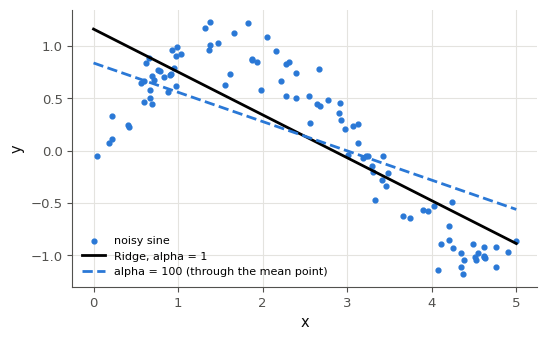

In [25]:
X_9 = x_9.reshape(-1, 1)
model_9 = Ridge(alpha=1.0).fit(X_9, y_9)            # fit returns the model itself
slope_9 = float(model_9.coef_[0])
intercept_9 = float(model_9.intercept_)
ends_9 = model_9.predict(np.array([[x_9.min()], [x_9.max()]])).tolist()   # two examples of one feature: (2, 1)
r2_9 = model_9.score(X_9, y_9)
strong_slope_9 = float(clone(model_9).set_params(alpha=100.0).fit(X_9, y_9).coef_[0])
left_9 = x_9 < 2.5
half_slope_9 = float(Ridge(alpha=1.0).fit(X_9[left_9], y_9[left_9]).coef_[0])
if filled(X_9) and np.ndim(X_9) != 2:
    print(f"❌ Ex 15.9a : X_9 doit être à deux dimensions, de forme (100, 1) (une ligne par exemple, une colonne par feature) ; reçu la forme {np.shape(X_9)}.")
else:
    print_answer("15.9a", list(np.shape(X_9)) if filled(X_9) else X_9)
print_answer("15.9b", slope_9)
print_answer("15.9c", intercept_9)
print_answer("15.9d", ends_9)
print_answer("15.9e", r2_9)
print_answer("15.9f", strong_slope_9)
print_answer("15.9g", half_slope_9)
if True:
    if filled(model_9) and hasattr(model_9, "coef_") and filled(slope_9) and as_float(slope_9) is not None:
        verdict("15.9", getattr(model_9, "alpha", None) == 1.0 and np.isclose(np.ravel(model_9.coef_)[0], as_float(slope_9)),
                "model_9 garde alpha=1.0 et la pente slope_9",
                "model_9 a changé (alpha ou pente) : f) se fait sur une copie, clone(model_9), pas sur model_9 lui-même")
    if not filled(slope_9, intercept_9):
        raise NotImplementedError("slope_9, intercept_9")
    if as_float(slope_9) is None or as_float(intercept_9) is None:
        print("❌ Ex 15.9 : slope_9 et intercept_9 doivent être des nombres (coef_ est un tableau : prends son élément).")
    else:
        line_x_9 = np.array([0.0, 5.0])
        fig, ax = plt.subplots(figsize=(6, 3.6))
        ax.scatter(x_9, y_9, s=12, label="noisy sine")
        ax.plot(line_x_9, as_float(slope_9) * line_x_9 + as_float(intercept_9), color="black", label="Ridge, alpha = 1")
        if filled(strong_slope_9) and as_float(strong_slope_9) is not None:
            ax.plot(line_x_9, as_float(strong_slope_9) * (line_x_9 - x_9.mean()) + y_9.mean(), ls="--",
                    label="alpha = 100 (through the mean point)")
        ax.set(xlabel="x", ylabel="y")
        ax.legend(fontsize=8)
        plt.show()

In [26]:
ols_9 = LinearRegression().fit(X_9, y_9)
first_last_9 = model_9.predict(np.array([[x_9[0]], [x_9[-1]]])).tolist()
wb.record("15.9a", list(X_9.shape), mistakes={"une seule ligne, avec 100 colonnes : c'est un seul exemple de 100 features ; on veut une ligne par exemple": [1, 100]})
wb.record("15.9b", slope_9, decimals=4, mistakes={"c'est la pente sans régularisation : model_9 est un Ridge avec alpha=1.0": float(ols_9.coef_[0]),
                                                 "relis la question : la pente de model_9, avec alpha=1.0": strong_slope_9})
wb.record("15.9c", intercept_9, decimals=4, mistakes={"c'est l'ordonnée à l'origine sans régularisation : model_9 est un Ridge avec alpha=1.0": float(ols_9.intercept_)})
wb.record("15.9d", ends_9, decimals=4, mistakes={"les abscisses ne sont pas triées : x_9[0] et x_9[-1] ne sont pas les extrémités": first_last_9,
                                                "les deux valeurs sont dans l'ordre inverse : d'abord la prédiction en x_9.min(), puis en x_9.max()": ends_9[::-1]})
wb.record("15.9e", r2_9, decimals=4, mistakes={"score d'un régresseur rend le R², pas une erreur : relis ce que renvoie score": mean_squared_error(y_9, model_9.predict(X_9))})
wb.record("15.9f", strong_slope_9, decimals=4, mistakes={"ta copie a encore la pente de model_9 : a-t-elle reçu alpha=100.0 avant d'être entraînée ?": slope_9})
wb.record("15.9g", half_slope_9, decimals=4, mistakes={"ton nouveau modèle a vu tous les points : il ne doit voir que les x < 2,5": slope_9,
                                                      "c'est la pente des points x ≥ 2,5 : relis le sens de l'inégalité": float(Ridge(alpha=1.0).fit(X_9[~left_9], y_9[~left_9]).coef_[0])})

WB_ANSWER {"decimals": 0, "element_hashes": ["f9f6940a0217c3065a23d3ab9d8a9b7794324daa69d27f1b2183154d74659f4a", "f1d530a9f7c7134f0c82a8fe4ef3836e5735b297d87662cf876e03090b91cdb1"], "hash": "ed18564f33b7a39e468b7cf2525bcababda87a98d509cec4ee988989f2cf87c1", "id": "15.9a", "integer": true, "kind": "array", "mistakes": {"a916e8422d2dfa64578b2507417a6389f5a44a81070c31d37de3a95024f60a3f": "une seule ligne, avec 100 colonnes : c'est un seul exemple de 100 features ; on veut une ligne par exemple"}, "shape": [2]}
📝 Ex 15.9a : réponse enregistrée (array, 0 décimale(s)).
WB_ANSWER {"decimals": 4, "hash": "cf52c3177560fc16c52eae540de8115bffa860e4e89668f4375c3bea41ac2da5", "hash_coarse": "4b1970406ccb8166fdafb8b0d1c62cce08581f86cd22ec462f7178703a476dee", "id": "15.9b", "kind": "float", "magnitude": -1, "mistakes": {"3cb0073d3a8323e961bde3503f9fb619afeafca1a29da99c4ddd137fdf9a76e9": "relis la question : la pente de model_9, avec alpha=1.0", "537e77f49dd03868d9e9af6a8e606971204a3da8282eb8614f2bf31

💡 La pente vaut −0,409 et l'ordonnée à l'origine 1,157 : une droite descend à travers une arche et un creux de sinus, et son $R^2$ de 0,686 dit qu'elle n'en explique qu'une partie. `predict` veut une matrice : `np.array([[x_9.min()], [x_9.max()]])`, deux exemples d'une feature, donne les deux extrémités en un appel (1,140 et −0,885). Avec `alpha=100.0`, la pénalité pèse plus lourd face aux cent erreurs : la pente se rapproche de 0 (−0,279 ; −0,072 avec `alpha=1000`). Sur la moitié gauche (une arche qui monte), un nouveau modèle trouve une pente **positive** (0,211) : `fit` repart de zéro avec les données qu'on lui donne. `set_params` sur `model_9` lui-même aurait changé son `alpha` sans le réentraîner, et ses attributs appris ne correspondraient plus à son réglage : d'où `clone`, une copie neuve aux mêmes hyperparamètres.

### Ex 15.10 — predict_proba : prédire ce que valent les probabilités de trois classifieurs 🔮 ★ ⏱️ 10 min
**Objectif :** prévoir ce que valent vraiment les probabilités de trois classifieurs, au-delà de leurs formes.  
**Prérequis :** ✏️ 15.2 · Ex 15.9 · ch. 3 (calibration) · ch. 13 (SVM, arbres, Naïve Bayes) · fiche §15.4.4 · **Fil rouge :** Penguins · **Parcours :** R, C

Les formes des sorties sont dans la fiche ; ce qui suit porte sur leurs **valeurs**. Trois modèles déjà entraînés sur les 233 manchots d'entraînement :
- `svc_10` : un `SVC(probability=True, random_state=0)` (après un `StandardScaler`) sur les deux mesures du bec ;
- `tree_10` : un `DecisionTreeClassifier(random_state=0)` **sans limite de profondeur**, sur les 4 mesures ;
- `nb_10` et `logistic_10` : un `GaussianNB()` et une régression logistique (après un `StandardScaler`), sur les 4 mesures.

Prédis, **avant** d'exécuter quoi que ce soit :
a) `disagree_10` : sur une grille de 40 000 points qui couvre les mesures du bec des manchots (`GRID_10`), la part des points où `svc_10.predict` ne donne **pas** la classe de plus grande probabilité de `svc_10.predict_proba` : `"A"` aucun ; `"B"` quelques-uns, moins de 5 % ; `"C"` de 5 à 20 % ; `"D"` plus de 20 % ;
b) `pure_10` : la part des 100 manchots de test dont la plus grande probabilité de `tree_10.predict_proba` vaut **exactement** 1 : `"A"` moins de la moitié ; `"B"` de la moitié à 90 % ; `"C"` plus de 90 %, mais pas tous ; `"D"` tous ;
c) `nb_bolder_10` : la moyenne, sur les manchots de test, de la plus grande probabilité donnée par Naïve Bayes est-elle **plus grande** que celle de la régression logistique ? `True` ou `False`.

Puis exécute l'expérience : elle mesure les trois quantités, affiche les accuracies et marque sur la carte des classes du SVC les points de désaccord.

In [27]:
BILL_10 = ["bill_length_mm", "bill_depth_mm"]
svc_10 = make_pipeline(StandardScaler(), SVC(probability=True, random_state=0)).fit(P_TRAIN[BILL_10], P_TRAIN["species"])
tree_10 = DecisionTreeClassifier(random_state=0).fit(P_TRAIN[MEASURES], P_TRAIN["species"])
nb_10 = GaussianNB().fit(P_TRAIN[MEASURES], P_TRAIN["species"])
logistic_10 = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(P_TRAIN[MEASURES], P_TRAIN["species"])
# a grid of 200 x 200 = 40,000 points that covers the bill measures of all the penguins (2 mm and 1 mm beyond)
g1_10 = np.linspace(PENGUINS[BILL_10[0]].min() - 2, PENGUINS[BILL_10[0]].max() + 2, 200)
g2_10 = np.linspace(PENGUINS[BILL_10[1]].min() - 1, PENGUINS[BILL_10[1]].max() + 1, 200)
GRID_10 = pd.DataFrame(np.array(np.meshgrid(g1_10, g2_10)).reshape(2, -1).T, columns=BILL_10)

In [28]:
disagree_10, pure_10, nb_bolder_10 = "B", "D", True   # the answers, for the record

In [29]:
wb.record("15.10a", "B", mistakes={"predict_proba d'un SVC ne vient pas du même calcul que predict : relis comment SVC obtient ses probabilités (fiche §15.4.4)": "A",
                                     "les deux sorties ne peuvent se contredire que là où deux classes sont presque à égalité : est-ce une grande partie de la carte ?": "C",
                                     "loin de toute frontière, les deux sorties choisissent-elles la même espèce ?": "D"})
wb.record("15.10b", "D", mistakes={"une feuille d'un arbre sans limite contient-elle encore plusieurs espèces ? Relis d'où viennent ses probabilités (fiche §15.4.4)": "A",
                                   "jusqu'où pousse un arbre sans limite de profondeur ? Et que vaut alors la proportion d'une espèce dans une feuille ?": "B",
                                   "un arbre sans limite garde-t-il une feuille impure, si aucun manchot d'entraînement n'a exactement les mêmes 4 mesures qu'un autre ?": "C"})
wb.record("15.10c", True, mistakes={"Naïve Bayes multiplie les vraisemblances de 4 mesures comme si elles étaient indépendantes : qu'arrive-t-il à des preuves qui se répètent ?": False})

WB_ANSWER {"hash": "45e89eb15c3b4b591e2c478f07e2576081feea853bda78dc5c7ccfc114a900c6", "id": "15.10a", "kind": "str", "mistakes": {"58625aa48e5ffd7041f66eed3a728f0af09794623db8d6535f93be528e8f9133": "predict_proba d'un SVC ne vient pas du même calcul que predict : relis comment SVC obtient ses probabilités (fiche §15.4.4)", "ca66c0eef257eb7cbcbc32f35c4923f8d12dda207b10bb59948660c03624e5eb": "loin de toute frontière, les deux sorties choisissent-elles la même espèce ?", "f05122d3211ca493fba17a90f8a7bda0ad8bdfd41d090c3288245dcf3fbae844": "les deux sorties ne peuvent se contredire que là où deux classes sont presque à égalité : est-ce une grande partie de la carte ?"}}
📝 Ex 15.10a : réponse enregistrée (str).
WB_ANSWER {"hash": "b203064bf52d5030fe347465a10f063082a2ae43b670eeb834490290dcc19f90", "id": "15.10b", "kind": "str", "mistakes": {"886a9386367aa80ed4293a907d6d4eaef1a36f5947287e7907319941e16aaf45": "un arbre sans limite garde-t-il une feuille impure, si aucun manchot d'entraînement 

a) SVC(probability=True): predict and the argmax of predict_proba disagree on 2.37% of the grid
b) unlimited tree: 100% of the test penguins get a largest probability of exactly 1 (accuracy 0.99)
c) mean largest probability: Naïve Bayes 0.976, logistic regression 0.950 · accuracies: 0.96 and 0.99


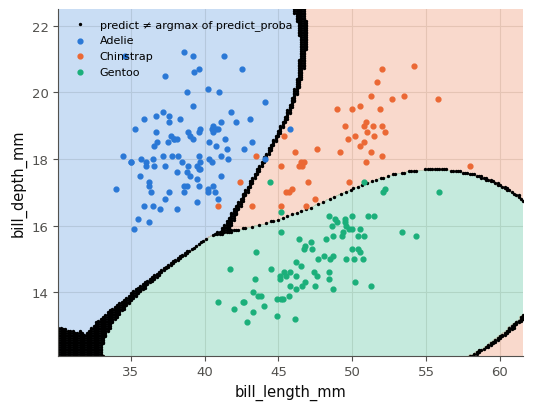

✅ Ex 15.10a : Bien joué !
✅ Ex 15.10b : C'est ça !
✅ Ex 15.10c : Parfait !


In [30]:
if any(answer is ... or answer is None for answer in [disagree_10, pure_10, nb_bolder_10]):
    print("⏳ Ex 15.10 : écris d'abord tes trois prédictions, puis relance cette cellule.")
else:
    labels_10 = svc_10.predict(GRID_10)
    argmax_10 = svc_10.classes_[svc_10.predict_proba(GRID_10).argmax(axis=1)]
    share_10 = float(np.mean(labels_10 != argmax_10))
    print(f"a) SVC(probability=True): predict and the argmax of predict_proba disagree on {share_10:.2%} of the grid")
    top_tree_10 = tree_10.predict_proba(P_TEST[MEASURES]).max(axis=1)
    print(f"b) unlimited tree: {np.mean(top_tree_10 == 1.0):.0%} of the test penguins get a largest probability of exactly 1 "
          f"(accuracy {tree_10.score(P_TEST[MEASURES], P_TEST['species']):.2f})")
    top_nb_10 = nb_10.predict_proba(P_TEST[MEASURES]).max(axis=1).mean()
    top_lr_10 = logistic_10.predict_proba(P_TEST[MEASURES]).max(axis=1).mean()
    print(f"c) mean largest probability: Naïve Bayes {top_nb_10:.3f}, logistic regression {top_lr_10:.3f} · accuracies: "
          f"{nb_10.score(P_TEST[MEASURES], P_TEST['species']):.2f} and {logistic_10.score(P_TEST[MEASURES], P_TEST['species']):.2f}")
    fig, ax = plt.subplots(figsize=(6, 4.5))
    codes_10 = pd.Categorical(labels_10, categories=svc_10.classes_).codes
    ax.contourf(g1_10, g2_10, codes_10.reshape(200, 200), levels=[-0.5, 0.5, 1.5, 2.5], alpha=0.25, colors=wb.plot.class_colors(3))
    ax.scatter(*GRID_10[labels_10 != argmax_10].to_numpy().T, s=2, color="black", label="predict ≠ argmax of predict_proba")
    for k, species in enumerate(svc_10.classes_):
        ax.scatter(*P_TRAIN[P_TRAIN["species"] == species][BILL_10].to_numpy().T, s=12, color=wb.plot.class_colors(3)[k], label=species)
    ax.set(xlabel=BILL_10[0], ylabel=BILL_10[1])
    ax.legend(fontsize=8)
    plt.show()
    wb.check("15.10a", disagree_10)
    wb.check("15.10b", pure_10)
    wb.check("15.10c", nb_bolder_10)

Dans tes notes : compare avec tes prédictions. D'où viennent les probabilités d'un `SVC`, d'un arbre, d'un Naïve Bayes ? Lesquelles prendrais-tu pour décider d'un seuil, et que faudrait-il vérifier avant (ch. 3) ?

💡 Le SVC et sa calibration interne se contredisent sur 2,4 % de la grille, uniquement près des frontières, là où deux espèces sont presque à égalité. L'arbre sans limite pousse jusqu'à des feuilles pures : les 100 manchots de test reçoivent une probabilité de 1 pour une espèce (pour une accuracy de 0,99), des « probabilités » qui ne disent rien de l'incertitude ; limité à la profondeur 3, il n'en donne plus 1 qu'à 51 %. Naïve Bayes est plus sûr de lui (0,976 en moyenne) que la régression logistique (0,950), et pourtant moins juste (0,96 contre 0,99) : il compte comme indépendantes des mesures corrélées (la masse et la nageoire), et ses probabilités sont poussées vers 0 et 1. Avec d'autres découpages des manchots (graines 1, 2 et 1510), les trois réponses restent les mêmes (désaccords de 1,5 à 1,7 %, feuilles toujours pures, Naïve Bayes toujours plus sûr).

### Ex 15.11 — Datasets synthétiques, fetch_* et train_test_split stratifié 📦 ★ ⏱️ 15 min
**Objectif :** charger les trois familles de datasets de scikit-learn, et voir ce que font le mélange et la stratification.  
**Prérequis :** Ex 15.9 · ch. 8 (découpage, stratification) · fiche §15.10 et §15.11 · **Fil rouge :** synthétique · **Parcours :** C

Trois familles de datasets : embarqués (`load_*`), téléchargés puis gardés en cache (`fetch_*`), générés (`make_*`). Le workbook charge California par `wb.datasets.load_california`, qui appelle `fetch_california_housing` et garde une copie de secours. **Contrat** :
a) `wine_11` : la liste `[nombre d'exemples, nombre de features, nombre de classes]` de `load_wine` ;
b) `first_feature_11` : le nom de sa première feature (une chaîne, dans le `Bunch`) ;
c) `california_11` : la liste `[nombre d'exemples, nombre de features]` de `X`, avec `X, y = wb.datasets.load_california(return_X_y=True)` ;
d) `no_shuffle_11` : `X_circ_11`, `y_circ_11` sont deux cercles générés **dans l'ordre** (`make_circles(..., shuffle=False)`, comme les points du livre au §15.11) ; la part de la classe 1 dans la partie **test** de `train_test_split(X_circ_11, y_circ_11, test_size=0.25, shuffle=False)` ;
e) `shuffled_11` : la même part, avec le mélange par défaut et `random_state=0` ;
f) `stratified_11` : la même part, avec `random_state=0` et `stratify=y_circ_11` ;
g) `rare_plain_11` : `X_rare_11`, `y_rare_11` comptent environ 10 % d'exemples de la classe 1 ; le **nombre** d'exemples de la classe 1 dans le test de `train_test_split(X_rare_11, y_rare_11, test_size=0.25, random_state=0)` ;
h) `rare_strat_11` : le même nombre avec `stratify=y_rare_11`.

La vérification contrôle a) à h), puis montre le test des cercles sans et avec mélange.

Dans tes notes : pourquoi le test de d) ne ressemble-t-il pas à l'entraînement ? Avec 20 exemples de la classe 1, combien en attendais-tu dans un quart des données ? Quand faut-il **ne pas** mélanger ?

In [31]:
X_circ_11, y_circ_11 = make_circles(n_samples=400, noise=0.05, factor=0.5, shuffle=False, random_state=0)
X_rare_11, y_rare_11 = make_classification(n_samples=200, weights=[0.9], random_state=1511)   # about 10 % of class 1
print("circles:", X_circ_11.shape, "· rare:", int(y_rare_11.sum()), "examples of class 1 out of", len(y_rare_11))

circles: (400, 2) · rare: 20 examples of class 1 out of 200


15.11a: [178.0, 13.0, 3.0]
15.11b: alcohol
15.11c: [20640.0, 8.0]
15.11d: 1.0
15.11e: 0.45
15.11f: 0.5
15.11g: 7
15.11h: 5


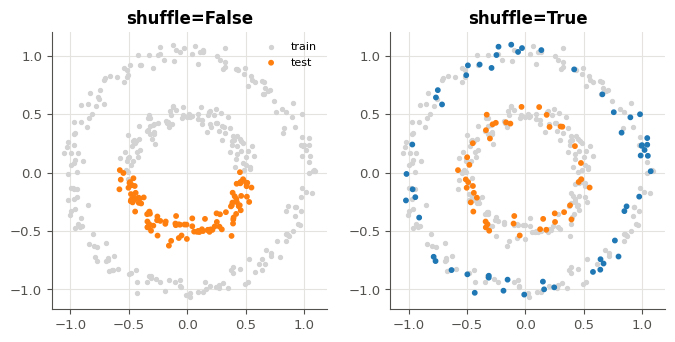

In [32]:
wine_11 = [*load_wine(return_X_y=True)[0].shape, len(np.unique(load_wine().target))]
first_feature_11 = load_wine().feature_names[0]
california_11 = list(wb.datasets.load_california(return_X_y=True)[0].shape)
y_test_11 = train_test_split(X_circ_11, y_circ_11, test_size=0.25, shuffle=False)[3]
no_shuffle_11 = float(y_test_11.mean())
shuffled_11 = float(train_test_split(X_circ_11, y_circ_11, test_size=0.25, random_state=0)[3].mean())
stratified_11 = float(train_test_split(X_circ_11, y_circ_11, test_size=0.25, random_state=0, stratify=y_circ_11)[3].mean())
rare_plain_11 = int(train_test_split(X_rare_11, y_rare_11, test_size=0.25, random_state=0)[3].sum())
rare_strat_11 = int(train_test_split(X_rare_11, y_rare_11, test_size=0.25, random_state=0, stratify=y_rare_11)[3].sum())
print_answer("15.11a", wine_11)
print_answer("15.11b", first_feature_11)
print_answer("15.11c", california_11)
print_answer("15.11d", no_shuffle_11)
print_answer("15.11e", shuffled_11)
print_answer("15.11f", stratified_11)
print_answer("15.11g", rare_plain_11)
print_answer("15.11h", rare_strat_11)
if filled(no_shuffle_11, shuffled_11):          # the picture, once d) and e) are answered
    fig, axes = plt.subplots(1, 2, figsize=(8, 3.6))
    for ax, shuffle in zip(axes, (False, True)):
        X_a, X_b, y_a, y_b = train_test_split(X_circ_11, y_circ_11, test_size=0.25, shuffle=shuffle,
                                              random_state=0 if shuffle else None)
        ax.scatter(*X_a.T, s=8, c="lightgray", label="train")
        ax.scatter(*X_b.T, s=10, c=np.where(y_b == 1, "tab:orange", "tab:blue"), label="test")
        ax.set(title=f"shuffle={shuffle}", aspect="equal")
    axes[0].legend(fontsize=8)
    plt.show()

In [33]:
wb.record("15.11a", wine_11, mistakes={"compte aussi les classes : la liste a trois nombres, [exemples, features, classes]": [178, 13]})
wb.record("15.11b", first_feature_11)
wb.record("15.11c", california_11, mistakes={"la cible n'est pas une feature : prends la forme de X, sans la colonne MedHouseVal": [20640, 9]})
train_part_11 = train_test_split(X_circ_11, y_circ_11, test_size=0.25, shuffle=False)[2]
wb.record("15.11d", no_shuffle_11, decimals=2, mistakes={"c'est la part dans l'entraînement : on demande la part de la classe 1 dans le test": float(train_part_11.mean()),
                                                         "c'est la part de la classe 0 : on demande celle de la classe 1": 1 - no_shuffle_11})
wb.record("15.11e", shuffled_11, decimals=2, mistakes={"c'est la part de la classe 0 : on demande celle de la classe 1": 1 - shuffled_11})
wb.record("15.11f", stratified_11, decimals=2)
wb.record("15.11g", rare_plain_11, choices=list(range(0, 51)),
          fractional="on demande un nombre d'exemples de la classe 1 dans le test, pas une proportion",
          mistakes={"c'est le nombre de la classe 1 dans l'entraînement : on demande celui du test": int(train_test_split(X_rare_11, y_rare_11, test_size=0.25, random_state=0)[2].sum()),
                    "relis la question : g) demande le découpage SANS stratify": rare_strat_11})
wb.record("15.11h", rare_strat_11, choices=list(range(0, 51)),
          fractional="on demande un nombre d'exemples de la classe 1 dans le test, pas une proportion",
          mistakes={"relis la question : h) demande le découpage avec stratify=y_rare_11": rare_plain_11})

WB_ANSWER {"decimals": 0, "element_hashes": ["6ed552cfdad52957a7163c19d91e8b255e5bc41db05c7b1f417933062f7c85cb", "578e9798d74a7a92bd61badd1809171da0f188ae950d672ce5d6421e8a0936fe", "03649a55fe15fdd53c535eece01e29567a3f2055d9571fec35b62ac99a355fe2"], "hash": "160b4d8decb08fb99bd3d0f34db4e67ff70b92f09e4b40389547c81f9fbc7af5", "id": "15.11a", "integer": true, "kind": "array", "mistakes": {"b29d81d2af2d78c8939e1a9e1c1931818c25990878282e43ccb37d079531d700": "compte aussi les classes : la liste a trois nombres, [exemples, features, classes]"}, "shape": [3]}
📝 Ex 15.11a : réponse enregistrée (array, 0 décimale(s)).
WB_ANSWER {"hash": "3cc1bbbd2040bb8eb6d56921a2ef89bad41a4c208457b26674e843d8ff7b1a5c", "id": "15.11b", "kind": "str"}
📝 Ex 15.11b : réponse enregistrée (str).
WB_ANSWER {"decimals": 0, "element_hashes": ["8343d960fda2b1671416df30eb59effc461d6ea403eba1fc398066745aa8ad82", "d194d51b899ab8a6173858d67994fc0da8ed57d94e52596c86f189b6273a6f86"], "hash": "2fe55331d5be844d4c4b166106e0937aa3

💡 `load_wine` : 178 vins, 13 features, 3 classes ; la première feature est `alcohol`. California : 20 640 districts et 8 features (la cible est à part). `make_circles(shuffle=False)` range d'abord le grand cercle (classe 0), puis le petit (classe 1) : sans mélange, le test (le dernier quart) ne contient que la classe 1 (part 1,00), sans aucun exemple de l'autre classe ; avec le mélange, 0,45 ; avec la stratification, exactement 0,50. Sur 20 exemples rares, un quart devrait en contenir 5 : sans stratification, le hasard en met 7 (de 3 à 7 selon `random_state`, de 0 à 5) ; avec, 5. On ne mélange pas des données ordonnées dans le temps (on apprend sur le passé et l'on teste sur l'avenir) ni des groupes (plusieurs mesures d'un même patient), qui se découpent par groupe.

### Ex 15.12 — Faire tourner le code de 2018 avec scikit-learn 1.6 🐛 ★★ ⏱️ 25 min
**Objectif :** moderniser un vieux programme en lisant ses messages d'erreur et la documentation de la version installée.  
**Prérequis :** Ex 15.9 · ch. 9 (RMSE) · ch. 12 (one-hot) · fiche §15.3, §15.4.3 et §15.9.3 · **Fil rouge :** synthétique · **Parcours :** R, C

La fonction `study_12` recopie un notebook écrit en 2018 pour scikit-learn 0.19 : une droite et sa valeur à gauche, un encodage one-hot de couleurs, une recherche en grille sur un `RidgeClassifier`, la RMSE de la droite. Avec la version 1.6, elle plante, et même une fois réparée, elle ne redonne pas tout à fait les résultats de 2018 (`REPORT_12`, ce que le notebook affichait à l'époque).

Répare-la **sans changer ce qu'elle calcule** : elle doit tourner sans erreur et rendre les mêmes résultats que `REPORT_12`. Méthode : exécute la cellule de vérification, lis le message de l'erreur (son type, sa dernière ligne), cherche le paramètre ou l'attribut dans la documentation de **ta** version (`scikit-learn.org/1.6/`), corrige, recommence. La vérification numérote six points, dans l'ordre du programme ; tant qu'une erreur arrête le programme, les points suivants attendent (⏳) ; quand il tourne, elle compare chaque résultat au rapport, dans l'ordre (un point ne se teste que si les précédents passent ; le point 6 porte sur la recherche : son meilleur score et ses scores d'entraînement). Quand les six points passent, elle relève a) le meilleur score de la recherche et b) la RMSE de la droite.

Dans tes notes : pour chaque point, le message reçu, la correction, et la version de scikit-learn qui a changé les choses (les notes de version le disent).

In [34]:
rng_12 = np.random.default_rng(1512)
x_12 = rng_12.uniform(-2, 4, 60)                                   # 60 points, in no particular order
y_12 = 0.8 * x_12 + 1 + rng_12.normal(0, 0.5, 60)
colors_12 = rng_12.choice(np.array(["red", "green", "blue", "white"]), 60)
features_12, labels_12 = wb.synth.make_moons(n=240, noise=0.3, seed=1512)
REPORT_12 = {"y_left": -0.6287, "onehot_columns": 4, "best_alpha": 0.01, "best_score": 0.8417,
             "train_scores": [0.8458, 0.8458, 0.8438, 0.8375, 0.8042, 0.775],
             "rmse": 0.4741}   # what the 2018 notebook printed (scikit-learn 0.19), rounded to 4 decimals

In [35]:
def study_12(x, y, colors, features, labels):
    """A notebook written in 2018 for scikit-learn 0.19, turned into a function. It must run with scikit-learn 1.6 and
    give the same results as in 2018 (REPORT_12)."""
    # 1. a line through the points, and its value at the left end
    line = Ridge(alpha=1.0).fit(x.reshape(-1, 1), y)
    y_left = line.predict(np.array([[x.min()]]))                       # fix 1: X in two dimensions, (1, 1)
    # 2. the colours in one-hot
    encoder = OneHotEncoder(sparse_output=False)                       # fix 2: renamed in 1.2, sparse removed in 1.4
    onehot = encoder.fit_transform(colors.reshape(-1, 1))
    # 3. a grid search on a RidgeClassifier
    search = GridSearchCV(RidgeClassifier(), {"alpha": [0.01, 0.1, 1, 10, 100, 1000]},
                          cv=3,                                        # fix 6: the 0.19 default (5 since 0.22)
                          return_train_score=True)                     # fix 4: train scores only on request (0.21)
    search.fit(features, labels)
    best = search.best_params_                                         # fix 3: the real name of the attribute
    train_scores = search.cv_results_["mean_train_score"]
    # 4. the root mean squared error of the line
    rmse = root_mean_squared_error(y, line.predict(x.reshape(-1, 1)))  # fix 5: squared=False removed in 1.6
    return {"y_left": float(np.ravel(y_left)[0]), "onehot_columns": onehot.shape[1], "best_alpha": best["alpha"],
            "best_score": search.best_score_, "train_scores": list(train_scores), "rmse": float(rmse)}
POINTS_12 = ["predict reçoit des données à deux dimensions", "OneHotEncoder accepte son argument de sortie dense",
             "le meilleur réglage se lit dans un attribut qui existe", "les scores d'entraînement de la recherche existent",
             "la RMSE se calcule sans argument retiré",
             "le meilleur score et les scores d'entraînement de la recherche sont ceux du rapport de 2018"]
CRASHES_12 = [(1, ValueError, "2D array"), (2, TypeError, "sparse"), (3, AttributeError, "best_parameters_"),
              (4, KeyError, "mean_train_score"), (5, TypeError, "squared")]


def crash_point_12(exc):
    """The number of the point that this exception reveals, or None."""
    for k, kind, text in CRASHES_12:
        if isinstance(exc, kind) and text in str(exc):
            return k
    return None


if True:
    try:
        result_12 = study_12(x_12, y_12, colors_12, features_12, labels_12)
        crash_12 = None
    except Exception as exc:                             # the 2018 code stops at its first incompatibility
        point_12 = crash_point_12(exc)
        if point_12 is None:
            raise                                        # another error: checked() reports it
        result_12, crash_12 = None, point_12
        for k in range(1, point_12):
            verdict("15.12", True, f"point {k} : {POINTS_12[k - 1]}.", "")
        print(f"❌ Ex 15.12 : point {point_12} ({POINTS_12[point_12 - 1]}) : le programme s'arrête sur "
              f"{type(exc).__name__} : {' '.join(str(exc).split())[:300]} Lis ce message, puis la documentation de ta version.")
        print(f"⏳ Ex 15.12 : points {point_12 + 1} à 6, puis a) et b) : corrige d'abord le point {point_12} "
              "(le programme doit d'abord aller plus loin).")
    if crash_12 is None and returned("15.12", "study_12", result_12):
        expected_12 = ["y_left", "onehot_columns", "best_alpha", "best_score", "train_scores", "rmse"]
        if not isinstance(result_12, dict) or sorted(result_12) != sorted(expected_12):
            print(f"❌ Ex 15.12 : study_12 doit rendre le dictionnaire de départ, avec les clés {expected_12}.")
        else:
            near_12 = lambda key: abs(float(result_12[key]) - REPORT_12[key]) < 6e-5
            try:
                train_12 = np.asarray(result_12["train_scores"], dtype=float).reshape(-1)
            except (TypeError, ValueError):
                train_12 = np.zeros(0)
            same_12 = lambda reference: train_12.shape == (6,) and np.allclose(train_12, reference, atol=6e-5, rtol=0)
            grid_12 = {"alpha": [0.01, 0.1, 1, 10, 100, 1000]}
            searches_12 = [GridSearchCV(RidgeClassifier(), grid_12, cv=folds, return_train_score=True).fit(
                features_12, labels_12).cv_results_ for folds in (3, 5)]          # the 0.19 and 1.6 defaults
            validation_12 = [results["mean_test_score"] for results in searches_12]   # not training scores
            checks_12 = [near_12("y_left"), result_12["onehot_columns"] == 4, result_12["best_alpha"] == 0.01,
                         train_12.shape == (6,) and bool(np.all((train_12 >= 0) & (train_12 <= 1)))
                         and not any(same_12(reference) for reference in validation_12), near_12("rmse"),
                         near_12("best_score") and same_12(REPORT_12["train_scores"])]
            hints_12 = ["la valeur à gauche n'est pas celle du rapport : la prédiction se fait-elle bien en x_12.min() ?",
                        "le rapport compte 4 colonnes (une par couleur)",
                        "le meilleur alpha n'est pas celui du rapport",
                        "il faut les 6 scores moyens d'entraînement de la recherche (un par valeur d'alpha), ceux que lisait le code de 2018, pas des scores de validation",
                        "la RMSE n'est pas celle du rapport : est-ce bien la racine de l'erreur quadratique moyenne ?",
                        f"le programme tourne, mais sa recherche ne redonne pas le rapport de 2018 (meilleur score "
                        f"{fr(float(result_12['best_score']), 4)} au lieu de {fr(REPORT_12['best_score'], 4)}, ou d'autres "
                        "scores d'entraînement) : un réglage par défaut a-t-il changé depuis 0.19 ? Relis la documentation de "
                        "GridSearchCV de ta version : quel découpage fait-elle par défaut, et lequel faisait 0.19 ?"]
            failed_12 = None
            for k, (ok, hint) in enumerate(zip(checks_12, hints_12), start=1):
                if failed_12 is not None:                # a point is only tested once the previous ones pass
                    print(f"⏳ Ex 15.12 : point {k} ({POINTS_12[k - 1]}) : corrige d'abord le point {failed_12}.")
                    continue
                verdict("15.12", ok, f"point {k} : {POINTS_12[k - 1]}.", f"point {k} : {hint}.")
                if not ok:
                    failed_12 = k
            if failed_12 is not None:
                print(f"⏳ Ex 15.12a et 15.12b : corrige d'abord le point {failed_12}.")
            else:                                        # a) and b) only once the six points pass
                print_answer("15.12a", float(result_12["best_score"]), computed=True)
                print_answer("15.12b", float(result_12["rmse"]), computed=True)

✅ Ex 15.12 : point 1 : predict reçoit des données à deux dimensions.
✅ Ex 15.12 : point 2 : OneHotEncoder accepte son argument de sortie dense.
✅ Ex 15.12 : point 3 : le meilleur réglage se lit dans un attribut qui existe.
✅ Ex 15.12 : point 4 : les scores d'entraînement de la recherche existent.
✅ Ex 15.12 : point 5 : la RMSE se calcule sans argument retiré.
✅ Ex 15.12 : point 6 : le meilleur score et les scores d'entraînement de la recherche sont ceux du rapport de 2018.
15.12a: 0.8416666666666667
15.12b: 0.47405761788489764


In [36]:
five_folds_12 = GridSearchCV(RidgeClassifier(), {"alpha": [0.01, 0.1, 1, 10, 100, 1000]}).fit(features_12, labels_12)
wb.record("15.12a", result_12["best_score"], decimals=4,
          mistakes={"le meilleur score n'est pas celui de 2018 : quel découpage la version 0.19 utilisait-elle par défaut (nombre de folds, stratifié ou non) ?": five_folds_12.best_score_})
mse_12 = mean_squared_error(y_12, Ridge(alpha=1.0).fit(x_12.reshape(-1, 1), y_12).predict(x_12.reshape(-1, 1)))
wb.record("15.12b", result_12["rmse"], decimals=4, mistakes={"c'est l'erreur quadratique moyenne : la RMSE en est la racine": mse_12})

WB_ANSWER {"decimals": 4, "hash": "04a210872b13071f6c145dcdb0a8857dbf4e644328744d40248b3b8c7e0c96e6", "hash_coarse": "060fb6637e3cb1b7d3c4aaa974f621b91dda94c4462cf101e94b08d44d872d05", "id": "15.12a", "kind": "float", "magnitude": -1, "mistakes": {"b9754d46f8ed5870837af84f412b6ab455700ae50594487f42d0a175c5e5990b": "le meilleur score n'est pas celui de 2018 : quel découpage la version 0.19 utilisait-elle par défaut (nombre de folds, stratifié ou non) ?"}, "sign": 1}
📝 Ex 15.12a : réponse enregistrée (float, 4 décimale(s)).
WB_ANSWER {"decimals": 4, "hash": "8d2b4e8e39aa0c324940b5ba2b951bfb82fde79115e15897f922179fb11adde9", "hash_coarse": "22c8835da69361185747c5cc38732f5f73d4fc14ec0b252920886af9cd74a87a", "id": "15.12b", "kind": "float", "magnitude": -1, "mistakes": {"e74ac875e86560a73dcb3cd8c2e9054fe04b4a6df642a12b1350f28f040c42fe": "c'est l'erreur quadratique moyenne : la RMSE en est la racine"}, "sign": 1}
📝 Ex 15.12b : réponse enregistrée (float, 4 décimale(s)).


💡 Six corrections : `predict(np.array([[x.min()]]))` (une matrice d'un exemple, `ValueError` sinon) ; `OneHotEncoder(sparse_output=False)` (`sparse` renommé en 1.2, retiré en 1.4 : `TypeError`) ; `best_params_` (`best_parameters_` n'a jamais existé : `AttributeError`) ; `return_train_score=True` (sinon `KeyError: 'mean_train_score'`, depuis 0.21) ; `root_mean_squared_error` (ou la racine de `mean_squared_error`) : `squared=False`, déprécié en 1.4, a été retiré en 1.6 (`TypeError`) ; enfin, une panne silencieuse : sans `cv`, la recherche fait 5 folds depuis 0.22, et son meilleur score vaut 0,8375 au lieu de 0,8417 ; `cv=3` redonne le résultat de 2018. Les cinq premières se trouvent en lisant le message ; la dernière, seulement en comparant aux résultats attendus : c'est pour cela qu'un projet garde ses résultats de référence et ses versions.

## Partie B · Clustering, transformateurs, PCA et ensembles

Une visite des grandes familles d'outils, sur les exemples du livre : le clustering (15.13), les transformateurs et leur `inverse_transform` (15.14), la PCA et le blanchiment (15.15), AdaBoost sur cinq spirales (15.16). Les données sont synthétiques et fournies, avec leurs graines.

### Ex 15.13 — Clustering avec scikit-learn : KMeans (le coude du livre), DBSCAN et clustering hiérarchique sur deux lunes et sept nuages gaussiens 📦 ★★ ⏱️ 25 min
**Objectif :** choisir un nombre de clusters avec l'inertie et la silhouette, et voir quand un clustering par densité ou hiérarchique fait mieux que k-means.  
**Prérequis :** ch. 7 (k-means, inertie, silhouette) · Ex 15.9 · fiche §15.5 · **Fil rouge :** synthétique · **Parcours :** C

Deux jeux : sept nuages gaussiens dont certains se chevauchent (`X_blobs_13`, l'exemple du livre aux figures 15.4 et 15.5), et deux demi-lunes peu bruitées (`X_moons_13`). Pour comparer un clustering aux vrais groupes, on utilise l'**indice de Rand ajusté** (`sklearn.metrics.adjusted_rand_score(vrais, trouvés)`) : il vaut 1 quand les deux partitions sont identiques (quels que soient les numéros des groupes), environ 0 pour un groupement au hasard.

**Contrat** :
a) `inertias_13` : pour chaque $k$ de `KS_13` (2 à 9), l'inertie d'un `KMeans(n_clusters=k, n_init=10, random_state=0)` entraîné sur les nuages ;
b) `silhouettes_13` : la silhouette moyenne (`silhouette_score`) de ces 8 clusterings ;
c) `best_k_13` : le $k$ de plus grande silhouette ;
d) `kmeans_ari_13` : l'indice de Rand ajusté d'un `KMeans(n_clusters=2, n_init=10, random_state=0)` sur les lunes ;
e) `dbscan_ari_13` : celui de `DBSCAN(eps=0.2)` sur les lunes ;
f) `small_eps_13` : la liste `[nombre de clusters, nombre de points de bruit]` de `DBSCAN(eps=0.1)` sur les lunes (le bruit a le label −1 et n'est pas un cluster) ;
g) `single_ari_13` : l'indice d'un `AgglomerativeClustering(n_clusters=2, linkage="single")` ;
h) `ward_ari_13` : celui d'un `AgglomerativeClustering(n_clusters=2)`, avec sa liaison par défaut (`"ward"`).

La vérification contrôle a) à h), puis trace les nuages, l'inertie et la silhouette, et quatre clusterings des lunes.

Dans tes notes : où vois-tu un coude ? La silhouette choisit-elle 7, et pourquoi ? Comment les quatre méthodes de d) à h) coupent-elles les lunes, et qu'est-ce qui, dans la façon dont chacune forme ses groupes, l'explique ? Que se passe-t-il quand `eps` est trop petit ?

In [37]:
X_blobs_13, y_blobs_13 = make_blobs(n_samples=700, centers=7, cluster_std=1.0, center_box=(-10, 10),
                                    random_state=1513)          # seven Gaussian blobs, some of them overlapping
X_moons_13, y_moons_13 = make_moons(n_samples=300, noise=0.06, random_state=1513)
KS_13 = list(range(2, 10))

15.13a: [22675.0535, 5571.898, 3504.179, 2108.5424, 1695.3653, 1335.7127, 1252.4722, 1149.7477]
15.13b: [0.5467, 0.7291, 0.7217, 0.6415, 0.6291, 0.5231, 0.4672, 0.4373]
15.13c: 3
15.13d: 0.2610406637783782
15.13e: 1.0
15.13f: [10.0, 11.0]
15.13g: 1.0
15.13h: 0.3581969412396029


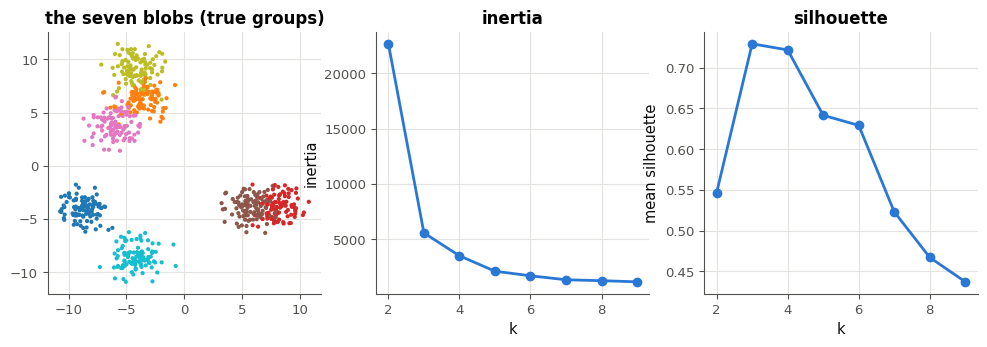

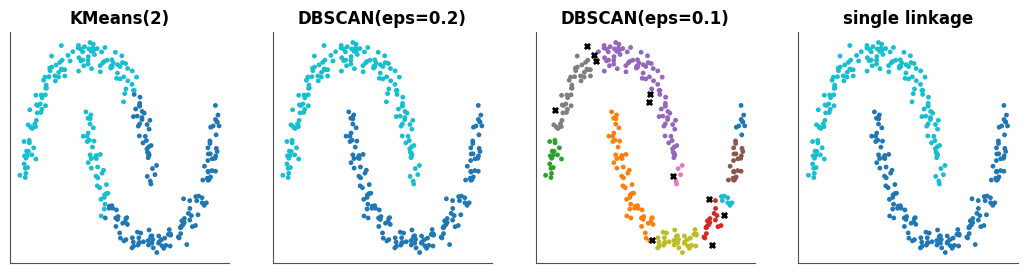

In [38]:
models_13 = [KMeans(n_clusters=k, n_init=10, random_state=0).fit(X_blobs_13) for k in KS_13]
inertias_13 = [m.inertia_ for m in models_13]
silhouettes_13 = [silhouette_score(X_blobs_13, m.labels_) for m in models_13]
best_k_13 = KS_13[int(np.argmax(silhouettes_13))]
kmeans_ari_13 = adjusted_rand_score(y_moons_13, KMeans(n_clusters=2, n_init=10, random_state=0).fit_predict(X_moons_13))
dbscan_ari_13 = adjusted_rand_score(y_moons_13, DBSCAN(eps=0.2).fit_predict(X_moons_13))
small_labels_13 = DBSCAN(eps=0.1).fit_predict(X_moons_13)
small_eps_13 = [len(set(small_labels_13) - {-1}), int(np.sum(small_labels_13 == -1))]
single_ari_13 = adjusted_rand_score(y_moons_13, AgglomerativeClustering(n_clusters=2, linkage="single").fit_predict(X_moons_13))
ward_ari_13 = adjusted_rand_score(y_moons_13, AgglomerativeClustering(n_clusters=2).fit_predict(X_moons_13))
print_answer("15.13a", inertias_13)
print_answer("15.13b", silhouettes_13)
print_answer("15.13c", best_k_13)
print_answer("15.13d", kmeans_ari_13)
print_answer("15.13e", dbscan_ari_13)
print_answer("15.13f", small_eps_13)
print_answer("15.13g", single_ari_13)
print_answer("15.13h", ward_ari_13)
if True:
    if not filled(inertias_13, silhouettes_13):
        raise NotImplementedError("inertias_13, silhouettes_13")
    try:
        shown_inertias_13 = np.asarray(inertias_13, dtype=float)
        shown_silhouettes_13 = np.asarray(silhouettes_13, dtype=float)
    except (TypeError, ValueError):
        shown_inertias_13 = shown_silhouettes_13 = np.empty(0)
    if shown_inertias_13.shape != (len(KS_13),) or shown_silhouettes_13.shape != (len(KS_13),):
        print(f"❌ Ex 15.13 : inertias_13 et silhouettes_13 doivent être deux listes de {len(KS_13)} nombres, une valeur par k de KS_13.")
    else:
        fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
        axes[0].scatter(*X_blobs_13.T, s=4, c=y_blobs_13, cmap="tab10")
        axes[0].set(title="the seven blobs (true groups)")
        axes[1].plot(KS_13, shown_inertias_13, "o-")
        axes[1].set(xlabel="k", ylabel="inertia", title="inertia")
        axes[2].plot(KS_13, shown_silhouettes_13, "o-")
        axes[2].set(xlabel="k", ylabel="mean silhouette", title="silhouette")
        plt.show()
if filled(kmeans_ari_13, dbscan_ari_13, small_eps_13, single_ari_13):   # the pictures, once d) to g) are answered
    fig, axes = plt.subplots(1, 4, figsize=(13, 3))
    for ax, (name, model) in zip(axes, [("KMeans(2)", KMeans(n_clusters=2, n_init=10, random_state=0)), ("DBSCAN(eps=0.2)", DBSCAN(eps=0.2)),
                                        ("DBSCAN(eps=0.1)", DBSCAN(eps=0.1)), ("single linkage", AgglomerativeClustering(n_clusters=2, linkage="single"))]):
        found = model.fit_predict(X_moons_13)
        ax.scatter(*X_moons_13[found >= 0].T, s=6, c=found[found >= 0], cmap="tab10")
        ax.scatter(*X_moons_13[found < 0].T, s=14, marker="x", color="black")
        ax.set(title=name, xticks=[], yticks=[])
    plt.show()

In [39]:
auto_13 = [KMeans(n_clusters=k, random_state=0).fit(X_blobs_13).inertia_ for k in KS_13]
wb.record("15.13a", inertias_13, decimals=1, mistakes={"ce sont les inerties avec le n_init par défaut (\"auto\" : une seule initialisation) : l'énoncé demande n_init=10": auto_13})
wb.record("15.13b", silhouettes_13, decimals=5)
wb.record("15.13c", best_k_13, choices=KS_13, fractional="on demande un nombre de clusters k, pas une silhouette",
          mistakes={**{f"k = {k} : est-ce celui de la plus grande silhouette de b) ?": k for k in KS_13 if k not in (best_k_13, 7, 1)},
                    "c'est le vrai nombre de nuages : la question demande le k que choisit la silhouette": 7,
                    "c'est la position du maximum dans la liste, pas la valeur de k correspondante": int(np.argmax(silhouettes_13))})
wb.record("15.13d", kmeans_ari_13, decimals=3)
wb.record("15.13e", dbscan_ari_13, decimals=3, mistakes={"c'est l'indice avec eps=0.1 : relis la question e)": adjusted_rand_score(y_moons_13, small_labels_13)})
wb.record("15.13f", small_eps_13, mistakes={"le bruit (label −1) n'est pas un cluster : ne le compte pas": [small_eps_13[0] + 1, small_eps_13[1]]})
wb.record("15.13g", single_ari_13, decimals=3)
wb.record("15.13h", ward_ari_13, decimals=3, mistakes={"relis la question : h) demande la liaison par défaut de AgglomerativeClustering, \"ward\"": single_ari_13})

WB_ANSWER {"decimals": 1, "element_hashes": ["4d9d0ee4d5ff1a84246c10f825418eccba4ca04ca4673693e7205ccdf178027a", "177281f073405fc98db4801fcbd600f55dc11f83027a08b9b56f6c3c57269bca", "3863871e4af098d4d35ca3a68ab5617ba04c533188d625e5a19e2cf1fced8996", "18deb9e3c933381d294aaac00128a9b18824964ec41e2d5a6995caf501524a41", "3887cc61c229eadd4de91baabfe67c4113ff373a312796fe91a74ba0f32279aa", "153d06689d718cafe81c47014802fedf1e282a260e35688bd984bc8a964afe89", "099fb69016410cd141cf14c6b84c2b4704525dc03efbf70c5edbe36d34a2b3ca", "5bc6a6f86a6bfac3b2491df562d4acc200a0db77b112c741f261442660422d34"], "hash": "e22ed4e75b43ac4e93a5738e749b8b5b355c79b86790191f66490cf927dedf98", "id": "15.13a", "kind": "array", "mistakes": {"d2b73b983cb8656b6a7dd5e0e012b209dc72b67ac89d5320a76446bec8f8fd81": "ce sont les inerties avec le n_init par défaut (\"auto\" : une seule initialisation) : l'énoncé demande n_init=10"}, "shape": [8]}
📝 Ex 15.13a : réponse enregistrée (array, 1 décimale(s)).
WB_ANSWER {"decimals": 5, "ele

💡 L'inertie passe de 22 675 (k = 2) à 5 572, 3 504, 2 109, 1 695… : la grande cassure est entre 2 et 3 (−17 103), puis les baisses s'amenuisent (−2 068, −1 396, −413) : un coude flou, entre 3 et 5. La silhouette choisit k = 3 (0,729) : plusieurs des sept nuages se chevauchent et forment trois gros paquets bien séparés ; elle juge des groupes séparés, pas le nombre de centres qui ont produit les données. Sur les lunes, k-means et la liaison de Ward (indices 0,261 et 0,358) cherchent des groupes compacts et coupent chaque lune ; DBSCAN (eps = 0,2) et la liaison simple suivent la chaîne des voisins et retrouvent les deux lunes (indice 1). Avec eps = 0,1, DBSCAN émiette les lunes en 10 clusters et laisse 11 points de bruit. Avec des nuages plus serrés (`cluster_std=0.6`), la silhouette choisit k = 4.

### Ex 15.14 — Transformateurs : test hors de [0, 1] et inverse_transform 📦 ★★ ⏱️ 20 min
**Objectif :** appliquer à des données nouvelles une transformation apprise sur l'entraînement, puis revenir dans les unités d'origine.  
**Prérequis :** ✏️ 15.3 · ch. 12 (min-max, règle d'or) · fiche §15.6 et §15.6.1 · **Fil rouge :** synthétique · **Parcours :** C

Deux situations du livre (§15.6, figures 15.7 à 15.12). D'abord, `TRAIN_14` et `TEST_14` : 80 points d'entraînement et 40 de test, à deux features, le test plus étendu sur la première et plus resserré sur la seconde. Ensuite, l'exemple de la circulation du ch. 12 : l'heure de la journée (`hours_14`) et le nombre de voitures par heure (`cars_14`), réunis dans `POINTS_14`. **Contrat** :
`scaler_14` : un `MinMaxScaler` appris sur `TRAIN_14` seul ; a) `test_min_14` et b) `test_max_14` : pour chaque feature, le minimum et le maximum de `TEST_14` transformé (deux listes de 2 nombres) ;
c) `outside_14` : la part des points de test (des lignes) qui sortent du carré $[0, 1] \times [0, 1]$ une fois transformés ;
`points_scaler_14` : un `MinMaxScaler` appris sur `POINTS_14` (les deux colonnes) ; d) `ends_14` : un tableau `(2, 2)`, les deux extrémités de la droite ajustée dans l'espace transformé (une `LinearRegression` des voitures transformées sur les heures transformées, prise aux heures transformées 0 et 1), ramenées dans les unités d'origine par `points_scaler_14.inverse_transform` ;
e) `slope_14` : la pente de la droite qui passe par les deux points de `ends_14`, en voitures par heure de la journée ;
f) `direct_slope_14` : la pente d'une `LinearRegression` ajustée directement sur les heures et les voitures, sans mise à l'échelle.

La vérification contrôle a) à f), puis trace ta droite sur les données d'origine.

Dans tes notes : pourquoi le test sort-il de $[0, 1]$, et est-ce un problème ? Compare e) et f) : comment expliques-tu ce que tu observes ? Qu'observerais-tu avec un `StandardScaler` ? Avec une `Ridge` à la place de la régression linéaire ?

In [40]:
rng_14 = np.random.default_rng(1514)
TRAIN_14 = np.column_stack([rng_14.uniform(10, 30, 80), rng_14.uniform(0, 5, 80)])     # 80 training points, 2 features
TEST_14 = np.column_stack([rng_14.uniform(5, 38, 40), rng_14.uniform(1.5, 3.5, 40)])   # 40 test points
hours_14 = rng_14.uniform(6, 22, 50)                               # traffic (ch. 12): the hour of the day
cars_14 = 40 * hours_14 - 120 + rng_14.normal(0, 60, 50)           # and the number of cars per hour
POINTS_14 = np.column_stack([hours_14, cars_14])

15.14a: [-0.256, 0.3004]
15.14b: [1.3829, 0.6995]
15.14c: 0.4
15.14d: [[6.2838, 130.9042], [21.5574, 777.776]]
15.14e: 42.35239145418382
15.14f: 42.35239145418381


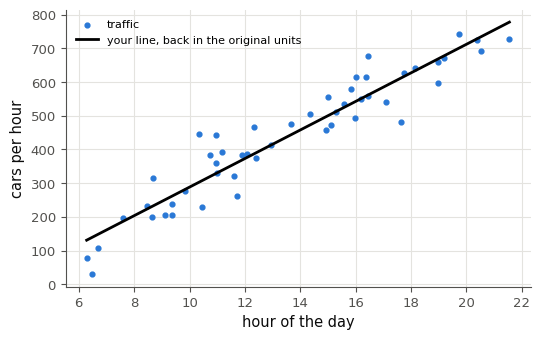

In [41]:
scaler_14 = MinMaxScaler().fit(TRAIN_14)
scaled_test_14 = scaler_14.transform(TEST_14)
test_min_14 = scaled_test_14.min(axis=0).tolist()
test_max_14 = scaled_test_14.max(axis=0).tolist()
outside_14 = float(np.mean(((scaled_test_14 < 0) | (scaled_test_14 > 1)).any(axis=1)))
points_scaler_14 = MinMaxScaler().fit(POINTS_14)
scaled_points_14 = points_scaler_14.transform(POINTS_14)
line_14 = LinearRegression().fit(scaled_points_14[:, [0]], scaled_points_14[:, 1])
scaled_ends_14 = np.column_stack([[0.0, 1.0], line_14.predict(np.array([[0.0], [1.0]]))])
ends_14 = points_scaler_14.inverse_transform(scaled_ends_14)
slope_14 = float((ends_14[1, 1] - ends_14[0, 1]) / (ends_14[1, 0] - ends_14[0, 0]))
direct_slope_14 = float(LinearRegression().fit(hours_14.reshape(-1, 1), cars_14).coef_[0])
print_answer("15.14a", test_min_14)
print_answer("15.14b", test_max_14)
print_answer("15.14c", outside_14)
print_answer("15.14d", ends_14)
print_answer("15.14e", slope_14)
print_answer("15.14f", direct_slope_14)
if True:
    if not filled(ends_14):
        raise NotImplementedError("ends_14")
    try:
        ends_shown_14 = np.asarray(ends_14, dtype=float)
    except (TypeError, ValueError):
        ends_shown_14 = np.empty(0)
    if ends_shown_14.shape != (2, 2):
        print(f"❌ Ex 15.14 : ends_14 doit être un tableau de nombres de forme (2, 2), deux points (heure, voitures) ; reçu {type(ends_14).__name__} de forme {ends_shown_14.shape}.")
    else:
        fig, ax = plt.subplots(figsize=(6, 3.6))
        ax.scatter(hours_14, cars_14, s=12, label="traffic")
        ax.plot(*ends_shown_14.T, color="black", label="your line, back in the original units")
        ax.set(xlabel="hour of the day", ylabel="cars per hour")
        ax.legend(fontsize=8)
        plt.show()

In [42]:
whole_14 = MinMaxScaler().fit(TEST_14).transform(TEST_14)
wb.record("15.14a", test_min_14, decimals=3, mistakes={"c'est un scaler appris sur le test : la transformation doit être celle de l'entraînement": whole_14.min(axis=0).tolist()})
wb.record("15.14b", test_max_14, decimals=4, mistakes={"c'est un scaler appris sur le test : la transformation doit être celle de l'entraînement": whole_14.max(axis=0).tolist()})
by_value_14 = float(np.mean((scaled_test_14 < 0) | (scaled_test_14 > 1)))
wb.record("15.14c", outside_14, decimals=3, mistakes={"tu as compté des valeurs (80 cases), pas des points : un point est dehors si l'UNE de ses deux coordonnées sort de [0, 1]": by_value_14})
wb.record("15.14d", ends_14, decimals=2, mistakes={"ce sont encore les extrémités dans l'espace transformé : ramène-les avec inverse_transform": scaled_ends_14})
wb.record("15.14e", slope_14, decimals=3, mistakes={"c'est la pente dans l'espace transformé, sans unité : calcule-la sur les extrémités ramenées": float(line_14.coef_[0])})
wb.record("15.14f", direct_slope_14, decimals=3)

WB_ANSWER {"decimals": 3, "element_coarse": [["a4cb470b4ecdb0d5cab532ec97b9841b5b8dcbe3751c87a9bfc81776bde8cfc2"], ["03ce6c9ef39b428d141d88a0b69128e3f86a5bb8e3edb2817156228f6b279472"]], "element_hashes": ["8a693d3b10d050f1b9924287edeb1f65a925271a1517d932d12ddfcbc5dc7438", "1e151700b989167067a87d81dd3984bad6d9fd4c91d5e1f748a95a33139cb51e"], "hash": "2c50458c91dcf34fc433163aac6f50f8646a6e9863e7b699354e7bab540d1ca3", "id": "15.14a", "kind": "array", "mistakes": {"452c9f299110a739cd19d42009aaa9dc5d402dabe417ef0390433ff0975a8429": "c'est un scaler appris sur le test : la transformation doit être celle de l'entraînement"}, "shape": [2]}
📝 Ex 15.14a : réponse enregistrée (array, 3 décimale(s)).
WB_ANSWER {"decimals": 4, "element_coarse": [["ce20a781d8d151535b6c7fc7a9bd1e3cecfee4a2553bf9c263fd86ec68f9b070"], ["cf14b68d36ac48d2d611319811232f1364134d83c9b5910878ac29fa492d6433"]], "element_hashes": ["9287fa2a35f8e06e05bf353c11ea6fe2aac1dfa3fb0de1804fdb81ddd54a113a", "1df508ff1a98a9e7590e19dc408b7

💡 Le test transformé va de −0,256 à 1,383 sur la première feature et de 0,300 à 0,700 sur la seconde : 40 % des points de test sortent du carré unité. C'est normal : la transformation est celle de l'entraînement (avec `clip=True`, ils seraient ramenés au bord). La droite ajustée dans l'espace transformé, ramenée par `inverse_transform`, va de (6,28 ; 130,9) à (21,56 ; 777,8) : pente 42,35 voitures par heure de la journée, exactement celle d'une régression faite sur les données brutes. Une mise à l'échelle est affine, et la droite des moindres carrés ne dépend pas du choix des unités de chaque axe : c'est la même droite. Avec un `StandardScaler` aussi (42,35). Avec une `Ridge(alpha=1.0)`, non : la pénalité dépend de l'échelle (32,93 en passant par l'espace transformé, 42,30 directement).

### Ex 15.15 — PCA de 3D vers 2D et blanchiment 📦 ★★ ⏱️ 20 min
**Objectif :** réduire un nuage en trois dimensions à deux, mesurer ce que l'on perd, et voir quand le blanchiment aide le modèle suivant.  
**Prérequis :** ch. 12 (PCA, projection) · ch. 7 (k-means) · Ex 15.13 · fiche §15.7 · **Fil rouge :** synthétique · **Parcours :** M, C

L'exemple du livre (§15.7, figures 15.13 et 15.14) : un nuage en forme d'ellipsoïde aplati, en trois dimensions (`BLOB_15`, 400 points). On a caché dedans deux groupes (`group_15`), séparés le long de la **deuxième** direction de variance, beaucoup moins étendue que la première. **Contrat** :
a) `pca_15` : une `PCA(n_components=2)` entraînée sur `BLOB_15` ; `ratio_15` : sa liste `explained_variance_ratio_` ;
b) `kept_15` : la part de la variance gardée par les deux composantes ;
c) `recon_15` : l'erreur de reconstruction, la moyenne sur toutes les valeurs de $(\text{inverse\_transform}(\text{transform}(\mathbf{X})) - \mathbf{X})^2$ ;
d) `white_15` : `BLOB_15` transformé par une `PCA(n_components=2, whiten=True)` entraînée sur lui (forme `(400, 2)`) ; `white_var_15` : la variance (`ddof=1`) de chacune de ses deux colonnes ;
e) `ari_plain_15` : l'indice de Rand ajusté (15.13) entre `group_15` et les labels d'un `KMeans(n_clusters=2, n_init=10, random_state=0)` entraîné sur les deux composantes de `pca_15`, **sans** blanchiment ;
f) `ari_white_15` : le même indice, avec le k-means entraîné sur `white_15`.

La vérification contrôle a) à f), puis trace les deux projections, colorées par groupe caché.

Dans tes notes : pourquoi l'inverse de c) n'est-il pas exact ? Que fait le blanchiment aux directions, et à la forme du nuage ? Compare e) et f) : qu'est-ce qui, dans la forme des deux nuages projetés, explique ce que tu observes ? Le blanchiment aiderait-il un arbre de décision ?

In [43]:
rng_15 = np.random.default_rng(1515)
group_15 = rng_15.integers(0, 2, 400)                     # two hidden groups (not given to the PCA nor to the k-means)
latent_15 = np.column_stack([rng_15.normal(0, 4, 400),                                       # a long direction
                             np.where(group_15 == 1, 1.2, -1.2) + rng_15.normal(0, 0.45, 400),  # the two groups
                             rng_15.normal(0, 0.3, 400)])                                    # a thin direction
rotation_15 = np.linalg.qr(rng_15.normal(size=(3, 3)))[0]
BLOB_15 = latent_15 @ rotation_15.T + np.array([5.0, -2.0, 10.0])   # a flattened, elongated blob in 3-D

15.15a: [0.9026, 0.0917]
15.15b: 0.9943231239955341
15.15c: 0.03353088660616694
15.15d: [1.0, 1.0]
15.15e: -0.0018919710890234584
15.15f: 0.9800500172306698


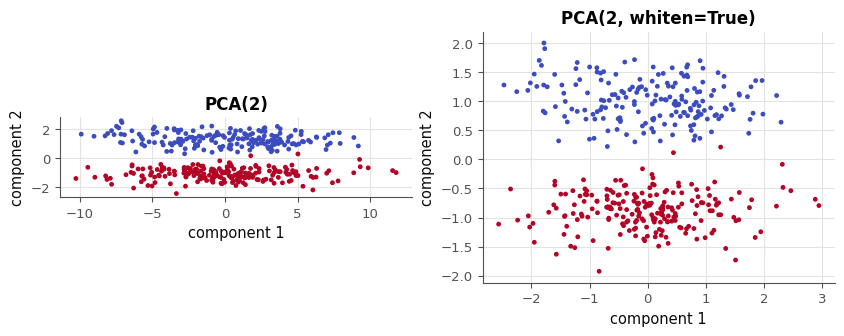

In [44]:
pca_15 = PCA(n_components=2).fit(BLOB_15)
ratio_15 = pca_15.explained_variance_ratio_.tolist()
kept_15 = float(np.sum(pca_15.explained_variance_ratio_))
reduced_15 = pca_15.transform(BLOB_15)
recon_15 = float(np.mean((pca_15.inverse_transform(reduced_15) - BLOB_15) ** 2))
white_15 = PCA(n_components=2, whiten=True).fit_transform(BLOB_15)
white_var_15 = np.var(white_15, axis=0, ddof=1).tolist()
ari_plain_15 = adjusted_rand_score(group_15, KMeans(n_clusters=2, n_init=10, random_state=0).fit_predict(reduced_15))
ari_white_15 = adjusted_rand_score(group_15, KMeans(n_clusters=2, n_init=10, random_state=0).fit_predict(white_15))
print_answer("15.15a", ratio_15)
print_answer("15.15b", kept_15)
print_answer("15.15c", recon_15)
print_answer("15.15d", white_var_15)
print_answer("15.15e", ari_plain_15)
print_answer("15.15f", ari_white_15)
if True:
    if not filled(pca_15, white_15):
        raise NotImplementedError("pca_15, white_15")
    plain_shown_15 = pca_15.transform(BLOB_15) if hasattr(pca_15, "components_") else None
    try:
        white_shown_15 = np.asarray(white_15, dtype=float)
    except (TypeError, ValueError):
        white_shown_15 = np.empty(0)
    if plain_shown_15 is None:
        print(f"❌ Ex 15.15 : pca_15 doit être une PCA entraînée sur BLOB_15 (l'objet, pas sa projection) ; reçu {type(pca_15).__name__}.")
    elif plain_shown_15.shape != (400, 2):
        print(f"❌ Ex 15.15 : pca_15 doit garder 2 composantes (PCA(n_components=2)) ; sa projection a la forme {plain_shown_15.shape}.")
    elif white_shown_15.shape != (400, 2):
        print(f"❌ Ex 15.15 : white_15 doit être un tableau de nombres de forme (400, 2), reçu la forme {white_shown_15.shape}.")
    else:
        fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
        for ax, data, title in zip(axes, (plain_shown_15, white_shown_15), ("PCA(2)", "PCA(2, whiten=True)")):
            ax.scatter(*data.T, s=6, c=group_15, cmap="coolwarm")
            ax.set(title=title, xlabel="component 1", ylabel="component 2", aspect="equal")
        plt.show()

In [45]:
wb.record("15.15a", ratio_15, decimals=4, mistakes={"ce sont les variances expliquées (explained_variance_), pas leurs parts : prends explained_variance_ratio_": pca_15.explained_variance_.tolist()})
wb.record("15.15b", kept_15, decimals=4, mistakes={"relis la question : on demande la part gardée par les DEUX composantes ensemble": ratio_15[0],
                                                  "relis la question : on demande la part gardée, pas la part perdue": 1 - kept_15})
wb.record("15.15c", recon_15, decimals=4, mistakes={"c'est une racine d'erreur : on demande la moyenne des carrés": float(np.sqrt(recon_15))})
wb.record("15.15d", white_var_15, decimals=4, mistakes={"variance avec ddof=0 : l'énoncé demande ddof=1": np.var(white_15, axis=0).tolist()})
wb.record("15.15e", ari_plain_15, decimals=3, mistakes={"relis la question : e) porte sur les composantes de pca_15, sans blanchiment": ari_white_15})
wb.record("15.15f", ari_white_15, decimals=3)

WB_ANSWER {"decimals": 4, "element_coarse": [["9fb02453ba1bbe2c94587f5c23cedaa1166e3e7e3793d33694d603e214889123"], ["df16984378437585976736bfe3c6b5b907b91f368ee4fa4163bc7c296e3cde4a"]], "element_hashes": ["affb9c0dedc4c1402887e5dccca784b560b5bc106306c4d3a5f33754e9a1e82a", "fdaf8cb2654a2cc4df5195ebf7b2b474d62f9bf24abf589c404499adca835e67"], "hash": "a30391e6c19d104017f588d71685748b1e0f93078db2b8ba765f119670a08807", "id": "15.15a", "kind": "array", "mistakes": {"652e3970f3b909417ff043d0cb0e82037cc6c3fc25e2a284a8e80b4cf54f303f": "ce sont les variances expliquées (explained_variance_), pas leurs parts : prends explained_variance_ratio_"}, "shape": [2]}
📝 Ex 15.15a : réponse enregistrée (array, 4 décimale(s)).
WB_ANSWER {"decimals": 4, "hash": "6e6c5632d7331b30800260a50048198a1832c1b535cbaf532ca9184d728f7838", "hash_coarse": "637ede7140d0c6f931041ef7aa01b063451f9256ce6fabecf5974f7b56fe86ce", "id": "15.15b", "kind": "float", "magnitude": -1, "mistakes": {"a981d7c70281ca0bf2662f6a8a69021d6a83

💡 Les deux composantes gardent 90,26 % et 9,17 % de la variance, 99,43 % à elles deux ; l'erreur de reconstruction vaut 0,0335 : la troisième direction est perdue, l'inverse est une projection, pas une copie. Le blanchiment divise chaque composante par son écart-type : deux variances de 1, les mêmes directions. Sans blanchiment, k-means coupe le nuage en travers de sa grande direction (indice −0,002 : rien à voir avec les groupes cachés) ; blanchi, le nuage est arrondi, et la coupure la plus économique passe entre les deux groupes : indice 0,980. Un `StandardScaler` sur les trois coordonnées ne suffit pas (0,150) : la direction qui sépare les groupes est oblique. Un arbre ne regarde qu'un axe à la fois, et diviser une composante par un nombre positif ne change pas l'ordre de ses valeurs : un arbre sur les composantes ne verrait aucune différence.

### Ex 15.16 — Cinq spirales : quel ensemble les démêle ? 🔬 ★★ ⏱️ 30 min
**Objectif :** comparer des AdaBoost de modèles de base différents, compter leurs membres et trouver la bonne profondeur des arbres.  
**Prérequis :** ch. 14 (AdaBoost, SAMME, forêts) · Ex 15.9 · fiche §15.8 · **Fil rouge :** synthétique · **Parcours :** C

L'expérience du livre (§15.8, figures 15.15 à 15.17) : 1 000 points répartis en cinq spirales, une par classe, deux tiers pour l'entraînement et un tiers pour le test (`X_TRAIN_16`, `X_TEST_16`). Tous les AdaBoost ont `n_estimators=50` et `random_state=0`. **Contrat** :
a) `ridge_16` : la liste `[accuracy de test, nombre de membres gardés]` d'un AdaBoost de `RidgeClassifier()` (le nombre de membres : `len(model.estimators_)`) ;
b) `tree_16` : la même liste pour un AdaBoost de `DecisionTreeClassifier(random_state=0)`, des arbres **sans limite** de profondeur ;
c) `tree_train_16` : l'accuracy d'**entraînement** de l'AdaBoost de b) ;
d) `stumps_16` : la même liste qu'en a) pour `AdaBoostClassifier(n_estimators=50, random_state=0)`, avec ses membres par défaut ;
e) `depth_curve_16` : pour chaque `max_depth` de `DEPTHS_16`, la liste `[accuracy de test, membres gardés]` d'un AdaBoost de `DecisionTreeClassifier(max_depth=depth, random_state=0)` (une liste de listes) ;
f) `forest_16` : l'accuracy de test d'une `RandomForestClassifier(n_estimators=100, random_state=0)`.

La vérification contrôle a) à f), trace la courbe de e), puis les frontières de trois AdaBoost.

Dans tes notes : combien de membres les AdaBoost de a), b) et d) ont-ils gardés, et pourquoi ce nombre-là ? Que dit l'accuracy des souches de ce qu'une souche peut découper ? Quelle profondeur choisirais-tu, et comment, sans regarder le test ?

In [46]:
X_16, y_16 = wb.synth.make_spirals(n=1000, n_classes=5, noise=0.2, seed=1516)   # five spirals, one per class
X_TRAIN_16, X_TEST_16, Y_TRAIN_16, Y_TEST_16 = train_test_split(X_16, y_16, test_size=1 / 3, random_state=1516, stratify=y_16)
DEPTHS_16 = [1, 2, 3, 4, 6, 8, 12, None]

15.16a: [0.2725, 4.0]
15.16b: [0.9042, 1.0]
15.16c: 1.0
15.16d: [0.3503, 50.0]
15.16e: [[0.3503, 50.0], [0.5359, 50.0], [0.7216, 50.0], [0.8503, 50.0], [0.9251, 50.0], [0.9551, 50.0], [0.9281, 3.0], [0.9042, 1.0]]
15.16f: 0.9221556886227545


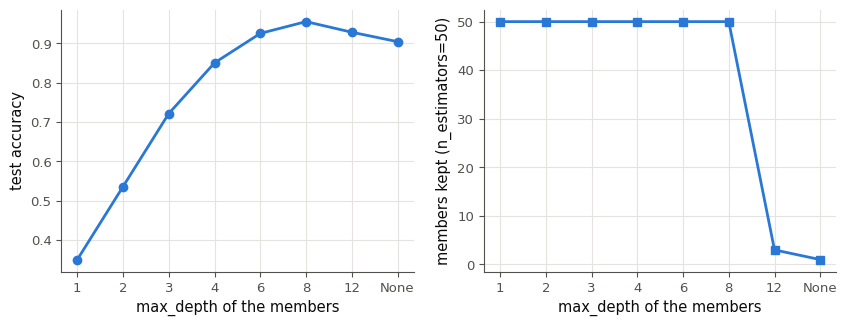

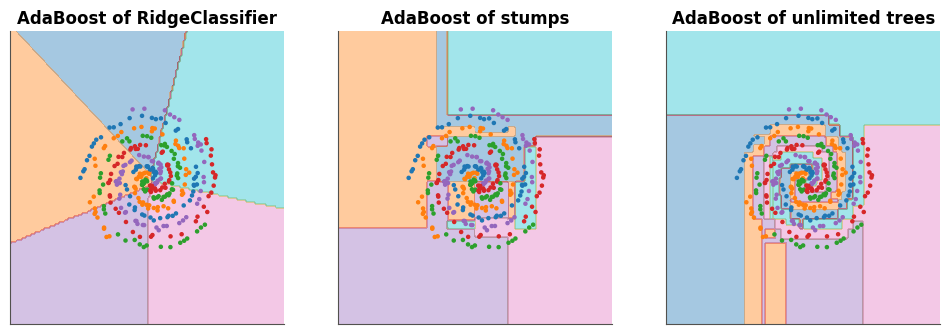

In [47]:
def ada_16(estimator=None):
    """AdaBoost (50 rounds at most) fitted on the training spirals."""
    return AdaBoostClassifier(estimator=estimator, n_estimators=50, random_state=0).fit(X_TRAIN_16, Y_TRAIN_16)


def summary_16(model):
    """[test accuracy, number of members kept]."""
    return [model.score(X_TEST_16, Y_TEST_16), len(model.estimators_)]


ridge_16 = summary_16(ada_16(RidgeClassifier()))
tree_model_16 = ada_16(DecisionTreeClassifier(random_state=0))
tree_16 = summary_16(tree_model_16)
tree_train_16 = tree_model_16.score(X_TRAIN_16, Y_TRAIN_16)
stumps_16 = summary_16(ada_16())
depth_curve_16 = [summary_16(ada_16(DecisionTreeClassifier(max_depth=depth, random_state=0))) for depth in DEPTHS_16]
forest_16 = RandomForestClassifier(n_estimators=100, random_state=0).fit(X_TRAIN_16, Y_TRAIN_16).score(X_TEST_16, Y_TEST_16)
print_answer("15.16a", ridge_16)
print_answer("15.16b", tree_16)
print_answer("15.16c", tree_train_16)
print_answer("15.16d", stumps_16)
print_answer("15.16e", depth_curve_16)
print_answer("15.16f", forest_16)
if True:
    if not filled(depth_curve_16):
        raise NotImplementedError("depth_curve_16")
    try:
        curve_16 = np.asarray(depth_curve_16, dtype=float)
    except (TypeError, ValueError):
        curve_16 = np.empty(0)
    if curve_16.shape != (len(DEPTHS_16), 2):
        print(f"❌ Ex 15.16 : depth_curve_16 doit être une liste de {len(DEPTHS_16)} paires [accuracy, membres], une par profondeur de DEPTHS_16.")
    else:
        labels_16 = [str(d) for d in DEPTHS_16]
        fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
        axes[0].plot(labels_16, curve_16[:, 0], "o-")
        axes[0].set(xlabel="max_depth of the members", ylabel="test accuracy")
        axes[1].plot(labels_16, curve_16[:, 1], "s-")
        axes[1].set(xlabel="max_depth of the members", ylabel="members kept (n_estimators=50)")
        plt.show()
if filled(ridge_16, tree_16, stumps_16):        # the frontiers, once a), b) and d) are answered
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
    for ax, (name, model) in zip(axes, [("AdaBoost of RidgeClassifier", AdaBoostClassifier(estimator=RidgeClassifier(), n_estimators=50, random_state=0)),
                                        ("AdaBoost of stumps", AdaBoostClassifier(n_estimators=50, random_state=0)),
                                        ("AdaBoost of unlimited trees", AdaBoostClassifier(estimator=DecisionTreeClassifier(random_state=0), n_estimators=50, random_state=0))]):
        DecisionBoundaryDisplay.from_estimator(model.fit(X_TRAIN_16, Y_TRAIN_16), X_16, response_method="predict",
                                               alpha=0.4, cmap="tab10", ax=ax, grid_resolution=150)
        ax.scatter(*X_TEST_16.T, c=Y_TEST_16, s=5, cmap="tab10", vmin=0, vmax=9)
        ax.set(title=name, xticks=[], yticks=[])
    plt.show()

In [48]:
wb.record("15.16a", ridge_16, decimals=3, mistakes={"le second nombre est-il bien le nombre de membres gardés, len(estimators_) ? n_estimators n'est qu'un maximum": [ridge_16[0], 50]})
wb.record("15.16b", tree_16, decimals=3, mistakes={"le second nombre est-il bien le nombre de membres gardés, len(estimators_) ? n_estimators n'est qu'un maximum": [tree_16[0], 50]})
wb.record("15.16c", tree_train_16, decimals=3)
wb.record("15.16d", stumps_16, decimals=3)
wb.record("15.16e", depth_curve_16, decimals=3)
wb.record("15.16f", forest_16, decimals=3)

WB_ANSWER {"decimals": 3, "element_coarse": [["c6f3d2e0fe6cea3cb575870d1b53cd29aeb0c82c147993eae95831571dcd06d4"], ["f0f51ff321280c9bb9c109ad7214591b15e399676e53afaa50e38ca1f0541f91"]], "element_hashes": ["eecfef19cc2fd532a1463c4adfb6d8c7b53649ede2a5f6213685c53b80a922f9", "1ceb7374640a5a3b74962c49ea0a65bcaaddba7c9a512679acec9ec493be6581"], "hash": "4e8b6aef15a9076388d06ca3cc5c94472413644659e9c48463b44b83388bec74", "id": "15.16a", "kind": "array", "mistakes": {"709ed8e115b831c4053d5be096cfa651d47f4dc3af7d7a7a1487a912e9212122": "le second nombre est-il bien le nombre de membres gardés, len(estimators_) ? n_estimators n'est qu'un maximum"}, "shape": [2]}
📝 Ex 15.16a : réponse enregistrée (array, 3 décimale(s)).
WB_ANSWER {"decimals": 3, "element_coarse": [["3f4fe0c18654ee20dfdfc5a12566d8549469e1f87ba064c80b6f110e735a45dd"], ["cd5d60b8f3c96bfdf15304099d16141d4b2c212ba6c60969529eba21c5dab80d"]], "element_hashes": ["fdac31a70d21db109eb8700a1e4e994e09aff7c66e208f7a040e6ac407b9974b", "e6a4b349

💡 L'AdaBoost de `RidgeClassifier` fait 0,272 (le hasard, à cinq classes, fait 0,2) et ne garde que 4 membres : leurs erreurs pondérées montent (0,716, 0,758, 0,773, 0,790), et le cinquième atteint 1 − 1/5 = 0,8 ou plus, la limite de SAMME : arrêt. L'AdaBoost d'arbres sans limite garde 1 membre : le premier arbre classe parfaitement l'entraînement (accuracy d'entraînement 1,000), et l'on ne peut pas corriger des erreurs qui n'existent pas : c'est un arbre seul (0,904). Les souches (0,350) ne coupent qu'un axe chacune : 50 coupures droites ne suivent pas cinq spirales. La courbe : 0,350, 0,536, 0,722, 0,850, 0,925, puis 0,955 à la profondeur 8 (50 membres), 0,928 à 12 (3 membres) et 0,904 sans limite : des arbres assez forts pour apprendre, assez faibles pour se tromper. La forêt fait 0,922 (0,931 avec 500 arbres). Pour choisir la profondeur sans regarder le test : une validation croisée sur l'entraînement, par exemple une `GridSearchCV` sur `estimator__max_depth`.

## Partie C · Évaluer, régler et enchaîner

La validation croisée et les estimateurs `...CV` (15.17), les recherches en grille et au hasard (15.18 à 15.20), la frontière de décision (15.21), le pipeline polynomial et la lecture de `cv_results_` (15.22 et 15.23), puis la fuite du ch. 8 refaite avec un pipeline (15.24). La cellule suivante importe les distributions de SciPy et la sélection de features.

In [49]:
from scipy.stats import loguniform, randint, uniform
from sklearn.feature_selection import SelectKBest, f_classif
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401  (registers the 3-D projection)

### Ex 15.17 — cross_validate, KFold, StratifiedKFold et RidgeClassifierCV 📦 ★★ ⏱️ 25 min
**Objectif :** choisir ses folds, lire plusieurs mesures à la fois, et comprendre ce que fait vraiment un estimateur `...CV`.  
**Prérequis :** ch. 8 (validation croisée, stratification) · Ex 15.9 · fiche §15.9.1 · **Fil rouge :** Penguins · **Parcours :** R, M, C

Les 333 manchots, **dans l'ordre du fichier** (triés par espèce : 146 Adélie, puis 119 Gentoo, puis 68 Chinstrap), décrits par deux mesures : l'épaisseur du bec et la nageoire (`X_17`). `MODEL_17` : une régression logistique après un `StandardScaler`. **Contrat** :
a) `kfold_17` : la liste des 5 scores de `cross_val_score(MODEL_17, X_17, Y_17, cv=KFold(5))` (sans mélange) ;
b) `default_17` : la moyenne des scores avec `cv=5` ;
`results_17` : `cross_validate(MODEL_17, X_17, Y_17, cv=FOLDS_17, scoring=["accuracy", "f1_macro"], return_train_score=True)`, avec `FOLDS_17` un `StratifiedKFold` mélangé ; c) `test_acc_17`, d) `train_acc_17` et e) `f1_17` : les moyennes de l'accuracy de validation, de l'accuracy d'entraînement et du F1 macro de validation ;
`ridge_cv_17` : un pipeline `PolynomialFeatures(degree=3)`, `StandardScaler`, puis `RidgeClassifierCV(alphas=ALPHAS_17)`, entraîné sur `X_17` et `Y_17` ; f) `alpha_17` : l'`alpha` qu'il a choisi ; g) `score_17` : `ridge_cv_17.score(X_17, Y_17)` ;
h) `outer_17` : la moyenne de `cross_val_score` d'un **nouveau** pipeline identique à `ridge_cv_17`, avec `cv=FOLDS_17`.

La vérification contrôle a) à h).

Dans tes notes : que s'est-il passé dans le dernier fold de a) ? Pourquoi b) ne souffre-t-il pas du tri, alors que `cv=5` ne mélange pas ? Qu'est-ce que `RidgeClassifierCV` a fait par validation croisée, et lequel de g) et h) estime honnêtement sa performance ?

In [50]:
X_17 = PENGUINS[["bill_depth_mm", "flipper_length_mm"]].to_numpy()   # two measures, the 333 penguins
Y_17 = PENGUINS["species"].to_numpy()                                    # in the order of the file: sorted by species
MODEL_17 = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
FOLDS_17 = StratifiedKFold(n_splits=5, shuffle=True, random_state=1517)
ALPHAS_17 = [0.01, 0.1, 1, 10, 100]
print("the first, middle and last penguins:", Y_17[0], Y_17[166], Y_17[-1])

the first, middle and last penguins: Adelie Gentoo Chinstrap


In [51]:
kfold_17 = cross_val_score(MODEL_17, X_17, Y_17, cv=KFold(5)).tolist()
default_17 = cross_val_score(MODEL_17, X_17, Y_17, cv=5).mean()          # an integer: stratified folds, not shuffled
results_17 = cross_validate(MODEL_17, X_17, Y_17, cv=FOLDS_17, scoring=["accuracy", "f1_macro"], return_train_score=True)
test_acc_17 = results_17["test_accuracy"].mean()
train_acc_17 = results_17["train_accuracy"].mean()
f1_17 = results_17["test_f1_macro"].mean()
ridge_cv_17 = make_pipeline(PolynomialFeatures(degree=3), StandardScaler(), RidgeClassifierCV(alphas=ALPHAS_17)).fit(X_17, Y_17)
alpha_17 = ridge_cv_17[-1].alpha_                                       # chosen during fit, by efficient leave-one-out
score_17 = ridge_cv_17.score(X_17, Y_17)                                # an accuracy on the data passed: no CV here
outer_17 = cross_val_score(make_pipeline(PolynomialFeatures(degree=3), StandardScaler(), RidgeClassifierCV(alphas=ALPHAS_17)),
                           X_17, Y_17, cv=FOLDS_17).mean()
print_answer("15.17a", kfold_17)
print_answer("15.17b", default_17)
print_answer("15.17c", test_acc_17)
print_answer("15.17d", train_acc_17)
print_answer("15.17e", f1_17)
print_answer("15.17f", alpha_17)
print_answer("15.17g", score_17)
print_answer("15.17h", outer_17)

15.17a: [0.8955, 0.597, 0.9851, 0.9697, 0.0]
15.17b: 0.8228855721393036
15.17c: 0.8198100407055632
15.17d: 0.831077694235589
15.17e: 0.7247743611588006
15.17f: 0.01
15.17g: 0.8288288288288288
15.17h: 0.8167797376752601


In [52]:
shuffled_17 = cross_val_score(MODEL_17, X_17, Y_17, cv=KFold(5, shuffle=True, random_state=1517)).tolist()
wb.record("15.17a", kfold_17, decimals=3, mistakes={"ces folds ont été mélangés : KFold(5) sans argument ne mélange pas": shuffled_17})
wb.record("15.17b", default_17, decimals=4, mistakes={"relis la question : b) demande cv=5, un entier ; pour un classifieur, quels folds un entier donne-t-il ?": float(np.mean(kfold_17)),
                                                    "relis la question : b) demande cv=5, pas les folds mélangés de FOLDS_17": test_acc_17})
wb.record("15.17c", test_acc_17, decimals=4, mistakes={"relis la question : c) demande l'accuracy des folds de validation (la clé test_accuracy)": train_acc_17,
                                                     "relis la question : c) demande l'accuracy, pas le F1": f1_17})
wb.record("15.17d", train_acc_17, decimals=4, mistakes={"relis la question : d) demande l'accuracy d'entraînement (la clé train_accuracy)": test_acc_17})
wb.record("15.17e", f1_17, decimals=4, mistakes={"c'est le F1 sur l'entraînement : on demande celui des folds de validation": float(results_17["train_f1_macro"].mean()),
                                               "relis la question : e) demande le F1 macro, pas l'accuracy": test_acc_17})
wb.record("15.17f", alpha_17, decimals=2, choices=ALPHAS_17,
          mistakes={f"alpha = {a} : est-ce la valeur que RidgeClassifierCV a choisie (son attribut alpha_) ?": a for a in ALPHAS_17 if a != alpha_17})
wb.record("15.17g", score_17, decimals=4, mistakes={"relis la question : g) demande ridge_cv_17.score(X_17, Y_17), l'accuracy du modèle entraîné sur les données qu'on lui passe": outer_17})
wb.record("15.17h", outer_17, decimals=4, mistakes={"relis la question : h) demande la moyenne d'une validation croisée d'un NOUVEAU pipeline, pas un score sur l'entraînement": score_17})

WB_ANSWER {"decimals": 3, "element_coarse": [["0d98612fac7bfdd76a02e8d8e12df6cd54d31ea300469484fa77c079b517ceb6"], ["0ba530d7ef1001daed6d7ee6f2978fde548f0e701330ef141555ee8c795834bb"], ["0295eccbacbe4d762d24c5ca98963852c1a6fd840587369d0f06fbbcb5ce8fe9"], ["4868fb0060adef7cd71bb30c30b64c5f30b2bd546b36b47cfc70ade8820f3793"], ["2d226e794c782b224d62305fddbf014a4bf6912e260adebdee92b033876ae9c1"]], "element_hashes": ["ac5a3d10e0d9caea7cbdd2d51cf73265ac70da3488df1ea7f7751351954d1e52", "2972ac995e8857b1a6562cbc025a7c3a69f25ad969854aa5e7aef8a6224aec1f", "f49b9fa8b9acc1ca6b0f12f83b44a62996e08a63d15382183d450a05840d5c18", "317af8ced3e49631be1ffaaa75b509e161a4104b4b933d02bf45650ce0f81721", "9e6dd1bfc6e3042a4bacd1d1064490255a0b55ef6f48e9a65ab92706590ba172"], "hash": "669629c796c4ca86404cf5f3e4fd3d938dc93805b8c06ff7c8eede245e73761f", "id": "15.17a", "kind": "array", "mistakes": {"06e64b9c3b12e6b431c0c526412941fa4535e81fe42af1339f7fafd17805934b": "ces folds ont été mélangés : KFold(5) sans argument n

💡 Sans mélange, `KFold(5)` suit l'ordre du fichier : le dernier fold ne contient que des Chinstrap (66), une espèce dont son entraînement n'a vu que 2 manchots : 0,000 ; le deuxième, tout Adélie, fait 0,597 (son entraînement ne contient plus que 79 Adélie, pour 187 autres manchots). Avec `cv=5`, un classifieur reçoit des folds stratifiés : chacun garde les proportions des espèces, même sans mélange : 0,823. Avec `FOLDS_17` : accuracy de validation 0,820, d'entraînement 0,831, F1 macro 0,725 (les Chinstrap, minoritaires et confondus avec les Adélie sur ces deux mesures, tirent le F1 vers le bas). `RidgeClassifierCV` a choisi `alpha = 0.01`, la plus petite valeur de la grille (à étendre vers le bas), par un leave-one-out calculé pendant `fit` ; son `score` (0,829) est une accuracy sur ses propres données d'entraînement. La validation croisée de h), qui refait ce choix dans chaque fold, donne l'estimation honnête : 0,817.

### Ex 15.18 — GridSearchCV : best_params_, cv_results_ et score d'entraînement 📦 ★★ ⏱️ 25 min
**Objectif :** lancer une recherche en grille et lire tout ce qu'elle rend, égalités comprises.  
**Prérequis :** ✏️ 15.1 · Ex 15.17 · fiche §15.9.2 et §15.9.3 · **Fil rouge :** synthétique · **Parcours :** R, M, C

L'exemple du livre (§15.9.3) : un `RidgeClassifier` sur deux demi-lunes bruitées, réglé sur six valeurs d'`alpha` et trois algorithmes de calcul (`solver`), soit 18 candidats. Les 400 points sont coupés en 300 pour la recherche et 100 pour le test. **Contrat** :
`search_18` : `GridSearchCV(RidgeClassifier(), GRID_18, cv=FOLDS_18, return_train_score=True)`, entraîné sur `X_TRAIN_18`, `Y_TRAIN_18` ; a) `best_alpha_18` et b) `best_solver_18` : le réglage du meilleur candidat ;
c) `best_score_18` : son score moyen de validation ;
d) `n_candidates_18` : le nombre de candidats évalués ;
e) `ties_18` : le nombre de candidats classés premiers (`rank_test_score` égal à 1) ;
f) `second_solver_18` : le `solver` du **deuxième** candidat, dans l'ordre de `cv_results_["params"]` ;
g) `gap_18` : pour le meilleur candidat, son score moyen d'entraînement moins son score moyen de validation ;
h) `test_18` : l'accuracy de `search_18` sur le test, mesurée une seule fois.

La vérification contrôle a) à h), puis affiche les premières lignes de `cv_results_`.

Dans tes notes : pourquoi tant d'égalités, et pourquoi le `solver` ne change-t-il rien ici ? Comment la recherche départage-t-elle des candidats à égalité ? Que dit `gap_18` de l'overfitting ? Pourquoi `test_18` et `best_score_18` diffèrent-ils ?

In [53]:
X_18, Y_18 = wb.synth.make_moons(n=400, noise=0.3, seed=1518)
X_TRAIN_18, X_TEST_18, Y_TRAIN_18, Y_TEST_18 = train_test_split(X_18, Y_18, test_size=0.25, random_state=1518, stratify=Y_18)
GRID_18 = {"solver": ["svd", "cholesky", "lsqr"], "alpha": [0.001, 0.01, 0.1, 1, 10, 100]}   # 18 candidates
FOLDS_18 = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

In [54]:
search_18 = GridSearchCV(RidgeClassifier(), GRID_18, cv=FOLDS_18, return_train_score=True).fit(X_TRAIN_18, Y_TRAIN_18)
best_alpha_18 = search_18.best_params_["alpha"]
best_solver_18 = search_18.best_params_["solver"]
best_score_18 = search_18.best_score_
table_18 = pd.DataFrame(search_18.cv_results_)
n_candidates_18 = len(table_18)
ties_18 = int((table_18["rank_test_score"] == 1).sum())
second_solver_18 = search_18.cv_results_["params"][1]["solver"]
gap_18 = table_18.loc[search_18.best_index_, "mean_train_score"] - table_18.loc[search_18.best_index_, "mean_test_score"]
test_18 = search_18.score(X_TEST_18, Y_TEST_18)
print_answer("15.18a", best_alpha_18)
print_answer("15.18b", best_solver_18)
print_answer("15.18c", best_score_18)
print_answer("15.18d", n_candidates_18)
print_answer("15.18e", ties_18)
print_answer("15.18f", second_solver_18)
print_answer("15.18g", gap_18)
print_answer("15.18h", test_18)
if True:
    if not filled(search_18):
        raise NotImplementedError("search_18")
    shown_18 = pd.DataFrame(search_18.cv_results_)[["param_alpha", "param_solver", "mean_test_score", "std_test_score",
                                                    "rank_test_score"]]
    print(shown_18.head(8).to_string())

15.18a: 0.001
15.18b: svd
15.18c: 0.8633333333333335
15.18d: 18
15.18e: 15
15.18f: cholesky
15.18g: 0.0024999999999998357
15.18h: 0.83
   param_alpha param_solver  mean_test_score  std_test_score  rank_test_score
0        0.001          svd         0.863333        0.037118                1
1        0.001     cholesky         0.863333        0.037118                1
2        0.001         lsqr         0.863333        0.037118                1
3        0.010          svd         0.863333        0.037118                1
4        0.010     cholesky         0.863333        0.037118                1
5        0.010         lsqr         0.863333        0.037118                1
6        0.100          svd         0.863333        0.037118                1
7        0.100     cholesky         0.863333        0.037118                1


In [55]:
wb.record("15.18a", best_alpha_18, decimals=3, choices=GRID_18["alpha"],
          mistakes={f"alpha = {a} : est-ce celui de best_params_ ? En cas d'égalité, c'est le PREMIER candidat de la grille qui gagne": a
                    for a in GRID_18["alpha"] if a != best_alpha_18})
wb.record("15.18b", best_solver_18, mistakes={f"{s} : en cas d'égalité, c'est le premier candidat de cv_results_[\"params\"] qui l'emporte ; relis l'ordre dans lequel la grille parcourt ses candidats": s
                                              for s in GRID_18["solver"] if s != best_solver_18})
wb.record("15.18c", best_score_18, decimals=4, mistakes={"relis la question : c) demande le score moyen de validation du meilleur candidat (best_score_)": test_18})
wb.record("15.18d", n_candidates_18, fractional="on demande un nombre de candidats",
          mistakes={"une grille essaie le produit des nombres de valeurs, pas leur somme": 9,
                    "c'est le nombre d'entraînements des validations croisées : on demande les candidats": n_candidates_18 * 5,
                    "c'est le nombre d'entraînements, réentraînement final compris : on demande les candidats": n_candidates_18 * 5 + 1})
wb.record("15.18e", ties_18, fractional="on demande un nombre de candidats",
          mistakes={"plusieurs candidats ont exactement la même moyenne : compte toutes les lignes de rang 1": 1})
wb.record("15.18f", second_solver_18, mistakes={"la grille trie ses hyperparamètres par ordre alphabétique de leur nom, et c'est le dernier qui varie le plus vite : lequel des deux ?": "svd",
                                                "relis l'ordre des valeurs de solver dans GRID_18": "lsqr"})
wb.record("15.18g", gap_18, decimals=4, mistakes={"le signe : on demande le score d'entraînement moins le score de validation": -gap_18})
wb.record("15.18h", test_18, decimals=2, mistakes={"relis la question : h) demande l'accuracy de search_18 sur X_TEST_18, mesurée une fois": best_score_18})

WB_ANSWER {"choices": ["0.001", "0.010", "0.100", "1.000", "10.000", "100.000"], "decimals": 3, "hash": "6c45faf2579d2f381cd9e847e04696a5829c7f6243fb99e269af3889f814dd22", "hash_coarse": "b8492cca8f4b41b320da2c933909c471f23cd766af6520019f0aa01f8e470954", "id": "15.18a", "kind": "float", "magnitude": -3, "mistakes": {"023f6e6c5ae9a72bd00b48152bd556b1eef1bbe2cf84a7e5524506f63930834b": "alpha = 100 : est-ce celui de best_params_ ? En cas d'égalité, c'est le PREMIER candidat de la grille qui gagne", "250088e540b4c93a8af935d23f34d118fba53677048b6ab234fb9f04f8dfef2b": "alpha = 0.01 : est-ce celui de best_params_ ? En cas d'égalité, c'est le PREMIER candidat de la grille qui gagne", "75ebcf5932f9920bf775e1d42551b7811ea18d147f814be6513b0b496f47f8cf": "alpha = 10 : est-ce celui de best_params_ ? En cas d'égalité, c'est le PREMIER candidat de la grille qui gagne", "ac875b1991431306f45f1b90d48f3a2ccfcd0a8c3d0cdc738175c039e4dd413d": "alpha = 1 : est-ce celui de best_params_ ? En cas d'égalité, c'e

💡 Le meilleur candidat : `alpha = 0.001` avec `svd`, score de validation 0,863 ; 18 candidats, dont 15 à égalité au premier rang : les trois solveurs résolvent le même problème convexe et trouvent les mêmes poids, et les alphas de 0,001 à 10 donnent les mêmes scores : jusqu'à 1, aucun point de validation ne change de classe ; à 10, deux points d'un même fold en changent, l'un devient juste et l'autre faux, et l'accuracy ne bouge pas. À égalité, `best_index_` prend le premier candidat de `cv_results_["params"]` : la grille range ses hyperparamètres par ordre alphabétique de leur nom (`alpha` avant `solver`, quel que soit l'ordre du dictionnaire) et fait varier le dernier le plus vite, d'où un deuxième candidat (0,001 ; `cholesky`). L'écart entraînement − validation vaut 0,0025 : pas d'overfitting pour un modèle linéaire à deux features. Le test donne 0,83 : 100 points seulement, et un score de validation un peu optimiste, puisqu'il a servi à choisir. Avec des alphas jusqu'à 10 000, les scores baissent à partir de 100 (0,850, 0,830, 0,827).

### Ex 15.19 — RandomizedSearchCV avec des distributions 📦 ★★ ⏱️ 25 min
**Objectif :** régler un modèle par une recherche au hasard, choisir ses distributions et savoir quand elle tire avec remise.  
**Prérequis :** Ex 15.18 · fiche §15.9.4 (encadré sur les distributions) · **Fil rouge :** synthétique · **Parcours :** M, C

Un `SVC` à noyau RBF sur 400 points de deux demi-lunes, réglé par une recherche au hasard sur `C` et `gamma`. **Contrat** :
`random_19` : `RandomizedSearchCV(SVC(), {"C": loguniform(1e-2, 1e3), "gamma": loguniform(1e-3, 1e2)}, n_iter=20, cv=FOLDS_19, random_state=1519)`, entraîné sur `X_19`, `Y_19` ; a) `best_C_19` et b) `best_gamma_19` : le réglage du meilleur candidat (deux `float`) ;
c) `best_score_19` : son score moyen de validation ;
d) `distinct_C_19` : le nombre de valeurs **distinctes** de `C` parmi les 20 candidats ;
e) `list_dupes_19` : pour `RandomizedSearchCV(KNeighborsClassifier(), {"n_neighbors": list(range(1, 31)), "weights": ["uniform", "distance"]}, n_iter=20, cv=FOLDS_19, random_state=1519)` entraîné sur les mêmes données, le nombre de candidats qui **répètent** un candidat précédent (20 moins le nombre de candidats distincts) ;
f) `randint_dupes_19` : le même nombre, avec `"n_neighbors": randint(1, 31)` à la place de la liste ;
g) `log_share_19` : la part des valeurs inférieures à 1 parmi `loguniform(1e-3, 1e3).rvs(10_000, random_state=1519)` ;
h) `uniform_share_19` : la même part pour `uniform(1e-3, 1e3).rvs(10_000, random_state=1519)`.

La vérification contrôle a) à h), puis place les 20 candidats de a) sur des axes logarithmiques, colorés par leur score.

Dans tes notes : pourquoi une échelle logarithmique pour `C` et `gamma` ? Que tire `uniform(1e-3, 1e3)` au juste (relis l'encadré sur ses deux arguments) ? Compare g) et h), puis e) et f) : qu'est-ce qui explique ce que tu observes, et qu'est-ce que cela coûte ?

In [56]:
X_19, Y_19 = wb.synth.make_moons(n=400, noise=0.3, seed=1519)
FOLDS_19 = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

15.19a: 0.3502937523300735
15.19b: 8.362265301185248
15.19c: 0.9099999999999999
15.19d: 20
15.19e: 0
15.19f: 3
15.19g: 0.5023
15.19h: 0.0005


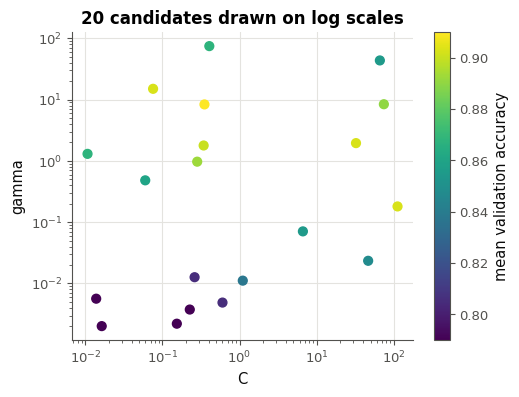

In [57]:
random_19 = RandomizedSearchCV(SVC(), {"C": loguniform(1e-2, 1e3), "gamma": loguniform(1e-3, 1e2)}, n_iter=20,
                               cv=FOLDS_19, random_state=1519).fit(X_19, Y_19)
best_C_19 = float(random_19.best_params_["C"])
best_gamma_19 = float(random_19.best_params_["gamma"])
best_score_19 = random_19.best_score_
distinct_C_19 = len({float(c) for c in random_19.cv_results_["param_C"]})


def repeats_19(search):
    """Number of candidates that repeat an earlier one: 20 minus the number of distinct candidates."""
    seen = [tuple(sorted(params.items())) for params in search.cv_results_["params"]]
    return len(seen) - len(set(seen))


knn_lists_19 = RandomizedSearchCV(KNeighborsClassifier(), {"n_neighbors": list(range(1, 31)), "weights": ["uniform", "distance"]},
                                  n_iter=20, cv=FOLDS_19, random_state=1519).fit(X_19, Y_19)
list_dupes_19 = repeats_19(knn_lists_19)
knn_randint_19 = RandomizedSearchCV(KNeighborsClassifier(), {"n_neighbors": randint(1, 31), "weights": ["uniform", "distance"]},
                                    n_iter=20, cv=FOLDS_19, random_state=1519).fit(X_19, Y_19)
randint_dupes_19 = repeats_19(knn_randint_19)
log_share_19 = float(np.mean(loguniform(1e-3, 1e3).rvs(10_000, random_state=1519) < 1))
uniform_share_19 = float(np.mean(uniform(1e-3, 1e3).rvs(10_000, random_state=1519) < 1))
print_answer("15.19a", best_C_19)
print_answer("15.19b", best_gamma_19)
print_answer("15.19c", best_score_19)
print_answer("15.19d", distinct_C_19)
print_answer("15.19e", list_dupes_19)
print_answer("15.19f", randint_dupes_19)
print_answer("15.19g", log_share_19)
print_answer("15.19h", uniform_share_19)
if True:
    if not filled(random_19):
        raise NotImplementedError("random_19")
    tried_19 = pd.DataFrame(random_19.cv_results_)
    fig, ax = plt.subplots(figsize=(5.5, 4))
    points_19 = ax.scatter(tried_19["param_C"].astype(float), tried_19["param_gamma"].astype(float),
                           c=tried_19["mean_test_score"], cmap="viridis", s=40)
    ax.set(xscale="log", yscale="log", xlabel="C", ylabel="gamma", title="20 candidates drawn on log scales")
    fig.colorbar(points_19, label="mean validation accuracy")
    plt.show()

In [58]:
wb.record("15.19a", best_C_19, decimals=4)
wb.record("15.19b", best_gamma_19, decimals=4, mistakes={"relis la question : b) demande le gamma du meilleur candidat, pas son C": best_C_19})
wb.record("15.19c", best_score_19, decimals=4)
wb.record("15.19d", distinct_C_19, choices=list(range(1, 21)), fractional="on demande un nombre de valeurs distinctes",
          mistakes={"une distribution continue donne-t-elle deux fois exactement la même valeur ?": 10})
wb.record("15.19e", list_dupes_19, choices=list(range(0, 20)), fractional="on demande un nombre de candidats",
          mistakes={"quand toutes les entrées sont des listes, la recherche tire-t-elle avec ou sans remise ? (fiche §15.9.4)": randint_dupes_19})
wb.record("15.19f", randint_dupes_19, choices=list(range(0, 20)), fractional="on demande un nombre de candidats",
          mistakes={"dès qu'une entrée est une distribution, même discrète, les tirages sont-ils encore sans remise ?": 0})
wb.record("15.19g", log_share_19, decimals=3, mistakes={"relis la question : g) porte sur loguniform": uniform_share_19,
                                                       "c'est la part AU-DESSUS de 1 : on demande la part sous 1": 1 - log_share_19})
wb.record("15.19h", uniform_share_19, decimals=4, mistakes={"relis la question : h) porte sur la loi uniform": log_share_19})

WB_ANSWER {"decimals": 4, "hash": "72f97fe16feed7e8a46a186b25657c2988dc1d4d8f3515f586706efb880f6b90", "hash_coarse": "7294ccc64cfb6b842656ec2fa7ccfa72e22f60fdacee91f1de63212ffc2cf309", "id": "15.19a", "kind": "float", "magnitude": -1, "sign": 1}
📝 Ex 15.19a : réponse enregistrée (float, 4 décimale(s)).
WB_ANSWER {"decimals": 4, "hash": "3891dd2a9dcfcc88be757b2d7229cf74c7abf505fe9819cb5b4b0f55864ad795", "hash_coarse": "c43b06bce7522a95b60d135be21130292f46c1ffcfa20e170311af5585e1c753", "id": "15.19b", "kind": "float", "magnitude": 0, "mistakes": {"bdfdef2ebf0da0d0e059aa948b6ae4e2bfb981a6a12fc8100d4b072f4bf6e761": "relis la question : b) demande le gamma du meilleur candidat, pas son C"}, "sign": 1}
📝 Ex 15.19b : réponse enregistrée (float, 4 décimale(s)).
WB_ANSWER {"decimals": 4, "hash": "0fae0af1ee7bf79efb4bdeb7098e2db5c41619ee0e426e970bc8e03ec1868d96", "hash_coarse": "b75f16b3250e3977281e7ea7358cab4cb623e5e1ffec7186d3905c16883d3b4c", "id": "15.19c", "kind": "float", "magnitude": -1, "

💡 Le meilleur candidat : `C` ≈ 0,350 et `gamma` ≈ 8,36, score 0,910. Les 20 valeurs de `C` sont distinctes (une loi continue ne se répète pas). Avec des listes seulement, la recherche tire sans remise : aucun doublon ; avec `randint`, les tirages sont indépendants : 3 candidats sur 20 répètent un candidat déjà évalué, autant de validations croisées faites pour rien. `loguniform(1e-3, 1e3)` met 50,2 % de ses tirages sous 1 (autant de chances par décade) ; `uniform(1e-3, 1e3)`, qui tire entre 0,001 et 1 000,001 (le second argument est la largeur), 0,05 % : presque jamais une petite valeur. Avec 60 essais au lieu de 20, le meilleur score passe à 0,9125.

### Ex 15.20 — Grille ou hasard : qui gagne avec 16 essais ? 🔮 ★★ ⏱️ 20 min
**Objectif :** prévoir, avant de le simuler, quand 16 essais au hasard battent une grille de 4 × 4, et le justifier par le calcul.  
**Prérequis :** Ex 15.19 · 🧮 15.5 · fiche §15.9.2 (Bergstra et Bengio, la formule $1 - (1 - q)^{n}$) · **Fil rouge :** synthétique · **Parcours :** M, C

Pour aller vite, pas de modèle à entraîner : trois **surfaces de validation inventées** sur le carré $[0, 1] \times [0, 1]$ de deux hyperparamètres $h_1$ et $h_2$, connues d'avance (`surface_a_20`, `surface_b_20`, `surface_c_20`). Une grille de $4 \times 4$ (les valeurs 0,125, 0,375, 0,625 et 0,875 de chaque hyperparamètre) et 16 essais tirés uniformément dans le carré coûtent autant ; on compare le meilleur score de chacun. Les trois surfaces :
- a) seul $h_1$ compte : un pic étroit en $h_1 = 0{,}53$ ;
- b) les deux comptent : un pic rond en $(0{,}53 ;\ 0{,}47)$ ;
- c) les deux comptent, et le pic tombe **exactement** sur un point de la grille, $(0{,}375 ;\ 0{,}625)$.

Prédis, **avant** d'exécuter quoi que ce soit, pour chaque surface, la part des 2 000 graines où les 16 essais au hasard battent **strictement** la grille : `"A"` moins de 25 % ; `"B"` de 25 à 50 % ; `"C"` de 50 à 75 % ; `"D"` plus de 75 %. Trois prédictions : `share_a_20`, `share_b_20` et `share_c_20`.

Puis exécute l'expérience : elle compte les victoires sur 2 000 graines et trace les trois surfaces, la grille et un tirage de 16 essais. Après l'expérience, la question d) te fait retrouver un de ces nombres par le calcul.

In [59]:
GRID_20 = np.array([0.125, 0.375, 0.625, 0.875])        # 4 values per hyperparameter: a 4 x 4 grid of 16 points


def surface_a_20(h1, h2):
    """A made-up validation score on [0, 1] x [0, 1]: only h1 matters (a narrow peak at h1 = 0.53)."""
    return np.exp(-(h1 - 0.53) ** 2 / (2 * 0.05 ** 2)) + 0 * h2


def surface_b_20(h1, h2):
    """Both hyperparameters matter: a round peak at (0.53, 0.47)."""
    return np.exp(-((h1 - 0.53) ** 2 + (h2 - 0.47) ** 2) / (2 * 0.1 ** 2))


def surface_c_20(h1, h2):
    """Both matter, and the peak sits exactly on a point of the grid, (0.375, 0.625)."""
    return np.exp(-((h1 - 0.375) ** 2 + (h2 - 0.625) ** 2) / (2 * 0.1 ** 2))


def grid_best_20(surface):
    """The best score of the 16 points of the grid."""
    h1, h2 = np.meshgrid(GRID_20, GRID_20)
    return float(surface(h1, h2).max())


def random_best_20(surface, seed):
    """The best score of 16 points drawn uniformly in the square, with np.random.default_rng(seed)."""
    points = np.random.default_rng(seed).random((16, 2))
    return float(surface(points[:, 0], points[:, 1]).max())

In [60]:
share_a_20, share_b_20, share_c_20 = "D", "C", "A"   # the answers, for the record

In [61]:
wb.record("15.20a", "D", mistakes={"une grille 4 × 4 n'essaie que 4 valeurs de h1 : à quelle distance du pic tombe la plus proche, et combien de valeurs de h1 essaient 16 tirages ?": "A",
                                    "seul h1 compte : 16 tirages essaient 16 valeurs de h1 au lieu de 4 ; la chance qu'aucune ne tombe près du pic est-elle grande ?": "B",
                                    "seul h1 compte : compte la chance qu'UN tirage tombe plus près du pic (en h1) que la meilleure valeur de la grille, puis qu'aucun des 16 n'y tombe": "C"})
wb.record("15.20b", "C", mistakes={"la grille n'est pas si près du pic : à quelle distance tombe son meilleur point, quelle part du carré est plus proche du pic, et que donne 1 − (1 − q)^n pour 16 tirages ?": "A",
                                    "la bonne zone est le disque autour du pic, de rayon égal à la distance du meilleur point de la grille : quelle part du carré, et pour 16 tirages ?": "B",
                                    "quand les deux comptent, 16 tirages ne valent plus 16 valeurs utiles : la part du carré plus proche du pic que la grille est-elle grande ?": "D"})
wb.record("15.20c", "A", mistakes={"un tirage au hasard peut-il faire MIEUX que le sommet exact de la surface, qu'un point de la grille touche déjà ?": "B",
                                    "le pic est sur un point de la grille : quel score la grille atteint-elle, et un tirage peut-il le dépasser ?": "C",
                                    "le pic est exactement sur un point de la grille : relis surface_c_20": "D"})

WB_ANSWER {"hash": "2b56280d6182c5a972ce2dbb267bf726a7dfa13c3042d06f44b42a15fa52aa44", "id": "15.20a", "kind": "str", "mistakes": {"21c6693b9f978204fd0077db957d4d6791771feb1330ce8a6dab387b33d19a1b": "une grille 4 × 4 n'essaie que 4 valeurs de h1 : à quelle distance du pic tombe la plus proche, et combien de valeurs de h1 essaient 16 tirages ?", "c91fd22a494244b7337aa0e45c1fd7ccc9c231dea69a73baaa67f052c3f43503": "seul h1 compte : 16 tirages essaient 16 valeurs de h1 au lieu de 4 ; la chance qu'aucune ne tombe près du pic est-elle grande ?", "ccf178c6d8c0117c6508657a10fbc6392b191bcd1f4e735bb7bf176cb25b30ad": "seul h1 compte : compte la chance qu'UN tirage tombe plus près du pic (en h1) que la meilleure valeur de la grille, puis qu'aucun des 16 n'y tombe"}}
📝 Ex 15.20a : réponse enregistrée (str).
WB_ANSWER {"hash": "d7923fade3ab1672ce8bbbebe522056cd653199a81c32eb753a1591eb6554990", "id": "15.20b", "kind": "str", "mistakes": {"15d1ee50b865692e39c1393e623112560ee72201986868d2f34710d027ce72

surface a: 16 random trials beat the 4 x 4 grid for 96.5% of 2,000 seeds (grid best 0.164)


surface b: 16 random trials beat the 4 x 4 grid for 61.6% of 2,000 seeds (grid best 0.406)


surface c: 16 random trials beat the 4 x 4 grid for 0.0% of 2,000 seeds (grid best 1.000)


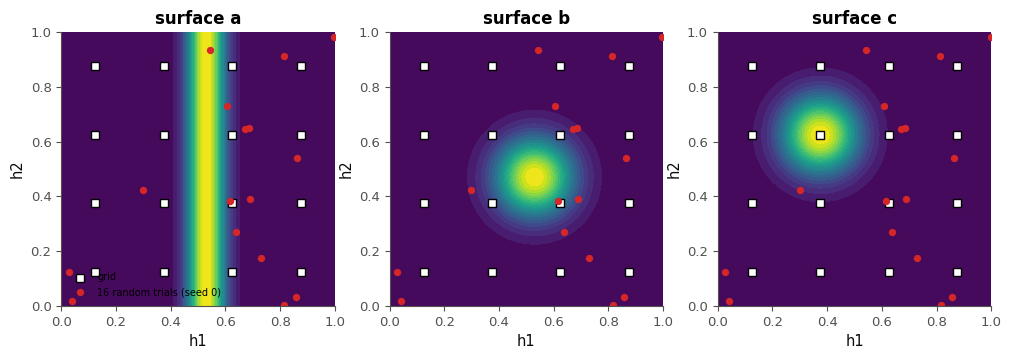

✅ Ex 15.20a : C'est ça !
✅ Ex 15.20b : Parfait !
✅ Ex 15.20c : Bravo !


In [62]:
if any(answer is ... or answer is None for answer in [share_a_20, share_b_20, share_c_20]):
    print("⏳ Ex 15.20 : écris d'abord tes trois prédictions, puis relance cette cellule.")
else:
    for name, surface in [("a", surface_a_20), ("b", surface_b_20), ("c", surface_c_20)]:
        wins = np.mean([random_best_20(surface, seed) > grid_best_20(surface) for seed in range(2000)])
        print(f"surface {name}: 16 random trials beat the 4 x 4 grid for {wins:.1%} of 2,000 seeds "
              f"(grid best {grid_best_20(surface):.3f})")
    h1_20, h2_20 = np.meshgrid(np.linspace(0, 1, 201), np.linspace(0, 1, 201))
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
    drawn_20 = np.random.default_rng(0).random((16, 2))
    for ax, (name, surface) in zip(axes, [("a", surface_a_20), ("b", surface_b_20), ("c", surface_c_20)]):
        ax.contourf(h1_20, h2_20, surface(h1_20, h2_20), levels=20, cmap="viridis")
        grid_h1_20, grid_h2_20 = np.meshgrid(GRID_20, GRID_20)
        ax.scatter(grid_h1_20, grid_h2_20, marker="s", color="white", edgecolor="black", s=30, label="grid")
        ax.scatter(*drawn_20.T, marker="o", color="tab:red", s=18, label="16 random trials (seed 0)")
        ax.set(title=f"surface {name}", xlabel="h1", ylabel="h2", aspect="equal")
    axes[0].legend(fontsize=7, loc="lower left")
    plt.show()
    wb.check("15.20a", share_a_20)
    wb.check("15.20b", share_b_20)
    wb.check("15.20c", share_c_20)

**d)** Pour la surface b, les 16 essais battent la grille quand l'un d'eux tombe **plus près du pic** que le meilleur point de la grille. Calcule la probabilité exacte de cet événement (la formule $1 - (1 - q)^{n}$ de la fiche, avec $q$ la part du carré concernée ; ce disque est tout entier dans le carré), et compare-la à la simulation.

Dans tes notes : compare avec tes prédictions, et explique chacun des trois résultats par ce que la grille et le hasard essaient sur chaque axe. Une vraie surface de validation ressemble-t-elle plutôt à a), à b) ou à c) ? Que t'apprend le cas c) sur les comparaisons « grille contre hasard » ?

In [63]:
r_20 = np.hypot(0.625 - 0.53, 0.375 - 0.47)     # the grid point closest to the peak: (0.625, 0.375)
q_20 = np.pi * r_20 ** 2                         # the share of the square closer to the peak than that point
theory_b_20 = 1 - (1 - q_20) ** 16
print(f"r = {r_20:.4f}, q = {q_20:.4f}, theory {theory_b_20:.4f}")

r = 0.1344, q = 0.0567, theory 0.6070


In [64]:
wb.record("15.20d", theory_b_20, decimals=3, mistakes={"q est l'aire du disque, π r², pas r²": 1 - (1 - r_20 ** 2) ** 16,
                                                      "q est l'aire du disque, π r², pas π r (la moitié d'un périmètre)": 1 - (1 - np.pi * r_20) ** 16,
                                                      "c'est la probabilité pour UN essai : il y en a 16": q_20,
                                                      "c'est la probabilité qu'AUCUN essai ne tombe dans le disque : on demande le complément": (1 - q_20) ** 16})

WB_ANSWER {"decimals": 3, "hash": "778482b156c767740ae3d422303c4753ea57873f1fe9316a0a0e3e18517e85ad", "hash_coarse": "d0793cfb1a26962ceaf1cffd3523f20b082310512ca986be566721f3f0ee45d3", "id": "15.20d", "kind": "float", "magnitude": -1, "mistakes": {"71c1be6af542b001a154fafc0ffb4d802ea8c51668377f7fc35327f1afb0985e": "c'est la probabilité qu'AUCUN essai ne tombe dans le disque : on demande le complément", "ccded0f8fe69c97d4123bc25aec14322339eb59ef930a18eb02a9080fdea6bc2": "c'est la probabilité pour UN essai : il y en a 16", "d6a6bcf12f7254c50144a4356cbe8c71fb6770606e7fad68c999c740b8d12ddf": "q est l'aire du disque, π r², pas r²", "e8da7f074cc41a52cf5cd8cabc5f4f67d858c5ec5b87c693732f7f0058a080e1": "q est l'aire du disque, π r², pas π r (la moitié d'un périmètre)"}, "sign": 1}
📝 Ex 15.20d : réponse enregistrée (float, 3 décimale(s)).


💡 Surface a : le hasard gagne pour 96,5 % des graines. La grille n'essaie que 4 valeurs de $h_1$, dont la plus proche du pic est à 0,095 ; un essai au hasard tombe plus près avec la probabilité 0,19, et les 16 ratent tous avec la probabilité $0{,}81^{16} \approx 0{,}034$. Surface b : 61,6 % ; le calcul exact donne $1 - (1 - \pi \times 0{,}1344^2)^{16} \approx 0{,}607$, dans la marge de la simulation. Surface c : 0 % : la grille touche le sommet. Les vraies surfaces ressemblent souvent à a) (Bergstra et Bengio : peu d'hyperparamètres comptent vraiment), et personne ne sait d'avance où est le pic : le cas c) est un coup de chance de la grille, qui rappelle de comparer des méthodes sur plusieurs problèmes, pas sur un seul. Variante : sur la surface b, 36 essais contre une grille de 6 × 6 (les valeurs $(2k + 1)/12$) gagnent 47,6 % du temps (calcul : 47,8 %) : le meilleur point de la grille est plus près du pic (0,075).

### Ex 15.21 — Frontières de décision : DecisionBoundaryDisplay et surfaces 3D 📦 ★★ ⏱️ 20 min
**Objectif :** tracer la frontière et la surface de score d'un classifieur à deux features, en quelques lignes.  
**Prérequis :** Ex 15.10 · Ex 15.18 · fiche §15.9.6 · **Fil rouge :** synthétique · **Parcours :** C

`MODEL_21` est déjà entraîné : un pipeline `PolynomialFeatures(degree=3)`, `StandardScaler`, `RidgeClassifier(alpha=1.0)` sur 300 points de deux demi-lunes. Les figures du livre (§15.9.6, figures 15.36 et 15.37) demandaient une grille et une boucle ; `DecisionBoundaryDisplay.from_estimator(modèle, X, response_method=...)` calcule la grille et trace d'un coup, puis garde ses calculs dans ses attributs `xx0`, `xx1` (la grille) et `response` (les valeurs tracées), et ses axes dans `ax_`. **Contrat** :
a) `classes_21` : le `DecisionBoundaryDisplay` des classes prédites (`response_method="predict"`), avec les points de `X_21` dessinés par-dessus (`classes_21.ax_.scatter(...)`) ;
b) `scores_21` : celui du score (`response_method="decision_function"`, une palette divergente comme `"RdBu_r"`), avec la frontière, le niveau 0 du score, tracée par `scores_21.ax_.contour(scores_21.xx0, scores_21.xx1, scores_21.response, levels=[0])` ;
c) dans une cellule à toi : la surface 3D du score, écrêtée à $[-1, 1]$ comme dans le livre (`np.clip`), avec `ax = plt.figure().add_subplot(projection="3d")` et `ax.plot_surface(...)`.

La vérification contrôle que a) montre des classes et b) le score de `decision_function` ; les figures se corrigent avec `05_solutions.md`.

Dans tes notes : où la frontière de a) se trouve-t-elle sur la carte de b) ? Pourquoi le livre écrête-t-il la surface ? Que montrerait `response_method="predict_proba"` sur ce modèle ?

In [65]:
X_21, Y_21 = wb.synth.make_moons(n=300, noise=0.25, seed=1521)
MODEL_21 = make_pipeline(PolynomialFeatures(degree=3), StandardScaler(), RidgeClassifier(alpha=1.0)).fit(X_21, Y_21)

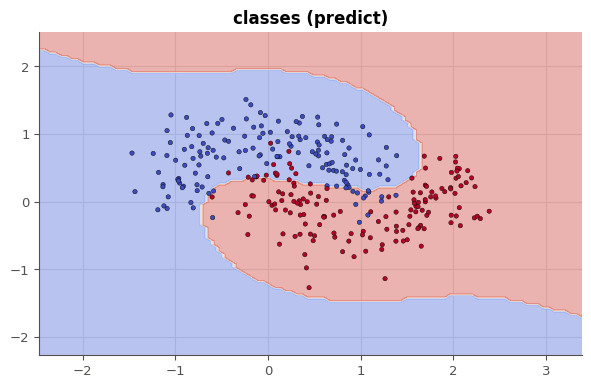

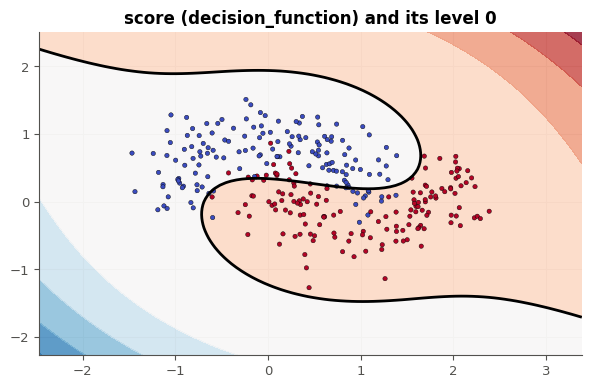

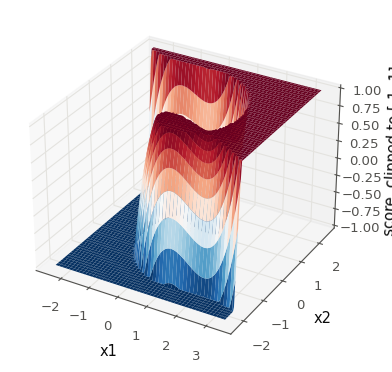

✅ Ex 15.21 : deux DecisionBoundaryDisplay.
✅ Ex 15.21 : a) montre les classes prédites (0 et 1).
✅ Ex 15.21 : b) montre le score de decision_function.
on the 10000 points of the grid, predict gives class 1 exactly where the score is positive: 100%


In [66]:
classes_21 = DecisionBoundaryDisplay.from_estimator(MODEL_21, X_21, response_method="predict", alpha=0.4, cmap="coolwarm")
classes_21.ax_.scatter(*X_21.T, c=Y_21, s=10, cmap="coolwarm", edgecolor="black", linewidth=0.3)
classes_21.ax_.set(title="classes (predict)")
plt.show()
scores_21 = DecisionBoundaryDisplay.from_estimator(MODEL_21, X_21, response_method="decision_function", cmap="RdBu_r",
                                                   alpha=0.8)
scores_21.ax_.contour(scores_21.xx0, scores_21.xx1, scores_21.response, levels=[0], colors="black")
scores_21.ax_.scatter(*X_21.T, c=Y_21, s=10, cmap="coolwarm", edgecolor="black", linewidth=0.3)
scores_21.ax_.set(title="score (decision_function) and its level 0")
plt.show()
ax_21 = plt.figure(figsize=(6, 4.5)).add_subplot(projection="3d")
ax_21.plot_surface(scores_21.xx0, scores_21.xx1, np.clip(scores_21.response, -1, 1), cmap="RdBu_r", linewidth=0)
ax_21.set(xlabel="x1", ylabel="x2", zlabel="score, clipped to [-1, 1]")
plt.show()
if True:
    if not filled(classes_21, scores_21):
        raise NotImplementedError("classes_21, scores_21")
    displays_ok_21 = isinstance(classes_21, DecisionBoundaryDisplay) and isinstance(scores_21, DecisionBoundaryDisplay)
    verdict("15.21", displays_ok_21, "deux DecisionBoundaryDisplay.",
            "classes_21 et scores_21 doivent être les objets rendus par DecisionBoundaryDisplay.from_estimator.")
    if displays_ok_21:
        grid_21 = np.column_stack([scores_21.xx0.ravel(), scores_21.xx1.ravel()])
        verdict("15.21", np.array_equal(np.unique(classes_21.response), [0, 1]),
                "a) montre les classes prédites (0 et 1).", "a) doit montrer predict : des classes 0 et 1.")
        same_21 = np.allclose(np.ravel(scores_21.response), MODEL_21.decision_function(grid_21))
        verdict("15.21", same_21, "b) montre le score de decision_function.",
                "b) doit montrer le score de decision_function (response_method=\"decision_function\").")
        if same_21:
            agree_21 = np.mean(MODEL_21.predict(grid_21) == (np.ravel(scores_21.response) > 0))
            print(f"on the {len(grid_21)} points of the grid, predict gives class 1 exactly where the score is "
                  f"positive: {agree_21:.0%}")

💡 La frontière de a) est exactement la ligne de niveau 0 de b) : `predict` donne la classe 1 là où le score est positif, sur les 10 000 points de la grille. Le score d'un `RidgeClassifier` n'a pas de borne : loin des données, le polynôme de degré 3 grandit vite, et l'écrêter à $[-1, 1]$ montre la zone où la décision se joue. `response_method="predict_proba"` lève une erreur : un `RidgeClassifier` n'a pas de `predict_proba` ; pour des probabilités, une régression logistique, ou un `CalibratedClassifierCV` autour du modèle.

### Ex 15.22 — Pipeline polynomial + ridge : degré et alpha ensemble 📦 ★★★ ⏱️ 35 min
**Objectif :** régler ensemble le degré des features polynomiales et la régularisation, dans un pipeline et une recherche en grille.  
**Prérequis :** Ex 15.18 · ✏️ 15.4 · ch. 9 (features polynomiales, régularisation) · fiche §15.9.5 · **Fil rouge :** synthétique · **Parcours :** R, C

L'exemple du livre (§15.9.5) : un `RidgeClassifier` ne trace qu'une droite ; avec des features polynomiales, sa frontière se courbe. 400 points de deux demi-lunes bruitées, 300 pour la recherche et 100 pour le test. **Contrat** :
`pipe_22` : un `Pipeline` de trois étapes nommées `"poly"` (`PolynomialFeatures()`), `"scale"` (`StandardScaler()`) et `"ridge"` (`RidgeClassifier()`) ; `grid_22` : la grille des degrés `DEGREES_22` et des alphas `ALPHAS_22`, avec les noms des étapes ; `search_22` : `GridSearchCV(pipe_22, grid_22, cv=FOLDS_22, return_train_score=True)`, entraîné sur la partie recherche ;
a) `best_22` : la liste `[meilleur degré, meilleur alpha]`, lue dans `best_params_` ;
b) `best_score_22` : le score moyen de validation du meilleur candidat ;
c) `n_features_22` : le nombre de colonnes que produit l'étape `"poly"` du meilleur pipeline (son attribut `n_output_features_`) ;
d) `test_22` : l'accuracy de `search_22` sur le test, mesurée une seule fois ;
e) `degree0_22` : le score moyen de validation des candidats de degré 0 (tous ont le même) ;
f) `overfit_22` : pour le degré 9 et l'alpha 0,001, le score moyen d'entraînement moins le score moyen de validation.

La vérification contrôle a) à f), puis trace les frontières du degré 1, du meilleur degré et du degré 9.

Dans tes notes : retrouve c) avec la formule de ✏️ 15.4. Pourquoi le degré 0 vaut-il ce score ? Le meilleur réglage est-il au bord de la grille, et que faudrait-il faire s'il l'était ? Pourquoi le `StandardScaler` est-il **après** `PolynomialFeatures` ?

In [67]:
X_22, Y_22 = wb.synth.make_moons(n=400, noise=0.3, seed=1522)
X_TRAIN_22, X_TEST_22, Y_TRAIN_22, Y_TEST_22 = train_test_split(X_22, Y_22, test_size=0.25, random_state=1522, stratify=Y_22)
FOLDS_22 = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
DEGREES_22 = [0, 1, 2, 3, 5, 7, 9]
ALPHAS_22 = [0.001, 0.1, 10, 1000]

15.22a: [5.0, 0.001]
15.22b: 0.9133333333333334
15.22c: 21
15.22d: 0.93
15.22e: 0.5
15.22f: 0.028333333333333544


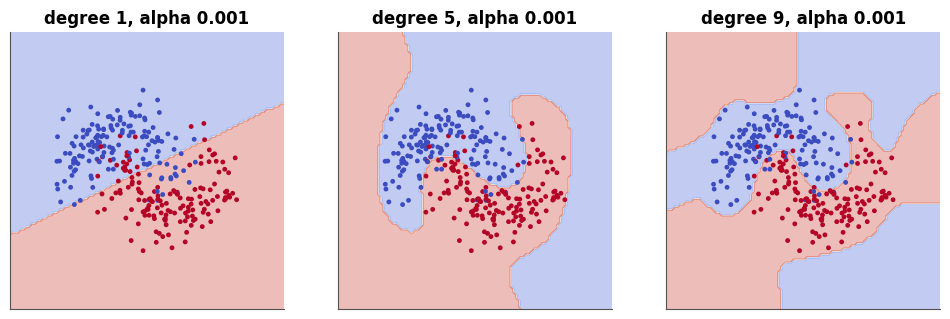

In [68]:
pipe_22 = Pipeline([("poly", PolynomialFeatures()), ("scale", StandardScaler()), ("ridge", RidgeClassifier())])
grid_22 = {"poly__degree": DEGREES_22, "ridge__alpha": ALPHAS_22}
search_22 = GridSearchCV(pipe_22, grid_22, cv=FOLDS_22, return_train_score=True).fit(X_TRAIN_22, Y_TRAIN_22)
best_22 = [search_22.best_params_["poly__degree"], search_22.best_params_["ridge__alpha"]]
best_score_22 = search_22.best_score_
n_features_22 = search_22.best_estimator_.named_steps["poly"].n_output_features_
test_22 = search_22.score(X_TEST_22, Y_TEST_22)
table_22 = pd.DataFrame(search_22.cv_results_)
degree0_22 = float(table_22.loc[table_22["param_poly__degree"] == 0, "mean_test_score"].iloc[0])
row_22 = table_22[(table_22["param_poly__degree"] == 9) & (table_22["param_ridge__alpha"] == 0.001)].iloc[0]
overfit_22 = row_22["mean_train_score"] - row_22["mean_test_score"]
print_answer("15.22a", best_22)
print_answer("15.22b", best_score_22)
print_answer("15.22c", n_features_22)
print_answer("15.22d", test_22)
print_answer("15.22e", degree0_22)
print_answer("15.22f", overfit_22)
if True:
    if not filled(search_22):
        raise NotImplementedError("search_22")
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
    for ax, degree in zip(axes, (1, search_22.best_params_["poly__degree"], 9)):
        model_22 = clone(search_22.best_estimator_).set_params(poly__degree=degree).fit(X_TRAIN_22, Y_TRAIN_22)
        DecisionBoundaryDisplay.from_estimator(model_22, X_22, response_method="predict", alpha=0.35, cmap="coolwarm", ax=ax)
        ax.scatter(*X_TRAIN_22.T, c=Y_TRAIN_22, s=6, cmap="coolwarm")
        ax.set(title=f"degree {degree}, alpha {search_22.best_params_['ridge__alpha']}", xticks=[], yticks=[])
    plt.show()

In [69]:
wb.record("15.22a", best_22, decimals=3, mistakes={"ce candidat est à égalité avec le meilleur : à égalité, la recherche garde le premier de la grille ; lis le réglage dans best_params_": [best_22[0], 0.1]})
wb.record("15.22b", best_score_22, decimals=4, mistakes={"relis la question : b) demande le score moyen de validation du meilleur candidat (best_score_)": test_22})
wb.record("15.22c", n_features_22, fractional="on demande un nombre de colonnes",
          mistakes={"as-tu compté la constante (include_bias=True par défaut) ?": n_features_22 - 1,
                    "c'est le nombre de features d'entrée : on demande celles que produit PolynomialFeatures": 2})
wb.record("15.22d", test_22, decimals=2, mistakes={"relis la question : d) demande l'accuracy de search_22 sur le test, mesurée une fois": best_score_22})
wb.record("15.22e", degree0_22, decimals=3)
wb.record("15.22f", overfit_22, decimals=4, mistakes={"le signe : on demande le score d'entraînement moins celui de validation": -overfit_22})

WB_ANSWER {"decimals": 3, "element_coarse": [["023870687e102eaf785be0aab9fd8c9cdc3be97803316ab1107511204fb4e5c6"], ["5effb28eca4434c2473101b64d0b9c411009a8770c119ce474cf1c8c08cb5e64"]], "element_hashes": ["d6987f929b6e0551dd4b4adac236287e5783f80fc1160e561e7c22fbcdea9de3", "bdf8686ecf4ecbc7d19f8bf2940bea2350a79b210b5b9b01533cb5eabae7fde0"], "hash": "acca829309d78e70ce9ad17af5c87a2e0888077fc968630132103a9c4a81972f", "id": "15.22a", "kind": "array", "mistakes": {"9d91bf8e8220484db2349c8bf3bae433735c691c6711b8b1f86585ee1d26e53f": "ce candidat est à égalité avec le meilleur : à égalité, la recherche garde le premier de la grille ; lis le réglage dans best_params_"}, "shape": [2]}
📝 Ex 15.22a : réponse enregistrée (array, 3 décimale(s)).
WB_ANSWER {"decimals": 4, "hash": "9eec54d1e431b35ac4049aa8bdba7db903d2979aed6cb312b2fff12265cfe2b5", "hash_coarse": "626de7ccfe2f7d116fd4a56966dca491e81cd09fa1d8aeed93c44fbb6f14df08", "id": "15.22b", "kind": "float", "magnitude": -1, "mistakes": {"2b81b1618

💡 Meilleur réglage : degré 5 et `alpha = 0.001` (à égalité avec 0,1 : le premier de la grille l'emporte), score de validation 0,913, et 0,93 sur le test. L'étape `"poly"` produit 21 colonnes : $\binom{2 + 5}{5} = 21$, constante comprise (✏️ 15.4). Le degré 0 vaut 0,500 : une seule colonne constante, le modèle répond partout la même classe, et les folds stratifiés sont moitié-moitié. Le degré choisi n'est pas au bord de la grille (0,900 et 0,903 aux degrés 7 et 9), l'alpha si (le plus petit) : on ajouterait des alphas plus petits pour s'en assurer ; avec des degrés jusqu'à 15, le meilleur reste (5 ; 0,001). Au degré 9, l'écart entraînement − validation monte à 0,028. Le `StandardScaler` vient après les features polynomiales parce que ce sont elles qui ont des échelles très différentes ($x^9$ contre $x$).

### Ex 15.23 — Lire cv_results_ : carte de chaleur et écarts-types 📈 ★★ ⏱️ 20 min
**Objectif :** transformer `cv_results_` en tableau et en carte de chaleur, et y lire ce qu'une recherche ne dit pas seule.  
**Prérequis :** Ex 15.22 · MP2 (règle d'une erreur type) · fiche §15.9.3 et §15.9.5 · **Fil rouge :** synthétique · **Parcours :** C

`SEARCH_23` est une recherche déjà faite : le pipeline polynomial de 15.22, sur deux cercles emboîtés bruités, avec 7 degrés et 4 alphas (28 candidats). **Contrat** :
a) `table_23` : un tableau d'une ligne par degré et d'une colonne par alpha, rempli par `mean_test_score` (`pd.DataFrame(SEARCH_23.cv_results_).pivot(...)`), et `spread_23`, le même pour `std_test_score` ; trace-les en cartes de chaleur (`plt.imshow`), avec les nombres dans les cases ;
b) `best_degree_23` : la liste, pour chaque alpha (dans l'ordre croissant), du degré qui a le meilleur score moyen dans sa colonne (à égalité, le plus petit degré, comme le rend `idxmax`) ;
c) `below_23` : le nombre de candidats dont le score moyen est **sous** 0,5, le score du modèle constant de degré 0 ;
d) `close_23` : le nombre de candidats dont le score moyen atteint au moins `best_score_` moins **une erreur type** du meilleur candidat (son `std_test_score` divisé par la racine du nombre de folds, 5).

La vérification contrôle a) à d).

Dans tes notes : en lisant tes cartes, que fait une forte régularisation au meilleur degré ? Pourquoi le degré 1 fait-il moins bien que le modèle constant sur des cercles ? Selon la règle d'une erreur type, choisirais-tu un autre réglage que le meilleur ? Où les écarts-types sont-ils les plus grands, et qu'en conclus-tu sur les différences de la carte des moyennes ?

In [70]:
X_23, Y_23 = make_circles(n_samples=300, noise=0.15, factor=0.5, random_state=1523)   # two noisy nested circles
pipe_23 = Pipeline([("poly", PolynomialFeatures()), ("scale", StandardScaler()), ("ridge", RidgeClassifier())])
SEARCH_23 = GridSearchCV(pipe_23, {"poly__degree": [0, 1, 2, 3, 4, 6, 8], "ridge__alpha": [0.01, 1, 100, 10000]},
                         cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=0)).fit(X_23, Y_23)
print("the search is done:", len(SEARCH_23.cv_results_["params"]), "candidates")

the search is done: 28 candidates


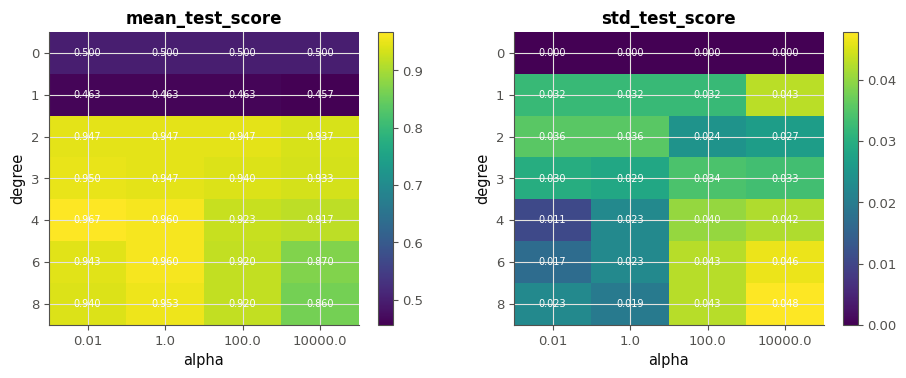

15.23a: [[0.5, 0.5, 0.5, 0.5], [0.4633, 0.4633, 0.4633, 0.4567], [0.9467, 0.9467, 0.9467, 0.9367], [0.95, 0.9467, 0.94, 0.9333], [0.9667, 0.96, 0.9233, 0.9167], [0.9433, 0.96, 0.92, 0.87], [0.94, 0.9533, 0.92, 0.86]]
15.23b: [4.0, 4.0, 2.0, 2.0]
15.23c: 4
15.23d: 1


In [71]:
results_23 = pd.DataFrame(SEARCH_23.cv_results_)
table_23 = results_23.pivot(index="param_poly__degree", columns="param_ridge__alpha", values="mean_test_score")
spread_23 = results_23.pivot(index="param_poly__degree", columns="param_ridge__alpha", values="std_test_score")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, table, title in zip(axes, (table_23, spread_23), ("mean_test_score", "std_test_score")):
    image = ax.imshow(table.to_numpy(), cmap="viridis", aspect="auto")
    ax.set(xticks=range(table.shape[1]), xticklabels=table.columns, yticks=range(table.shape[0]),
           yticklabels=table.index, xlabel="alpha", ylabel="degree", title=title)
    for i in range(table.shape[0]):
        for j in range(table.shape[1]):
            ax.text(j, i, f"{table.iloc[i, j]:.3f}", ha="center", va="center", fontsize=7, color="white")
    fig.colorbar(image, ax=ax)
plt.show()
best_degree_23 = [int(table_23[alpha].idxmax()) for alpha in table_23.columns]
below_23 = int((results_23["mean_test_score"] < 0.5).sum())
threshold_23 = SEARCH_23.best_score_ - results_23.loc[SEARCH_23.best_index_, "std_test_score"] / np.sqrt(5)
close_23 = int((results_23["mean_test_score"] >= threshold_23).sum())
if True:
    if not filled(table_23):
        raise NotImplementedError("table_23")
    try:
        values_23 = np.asarray(table_23, dtype=float)
    except (TypeError, ValueError):
        values_23 = None
    if values_23 is None or values_23.shape != (7, 4):
        print(f"❌ Ex 15.23 : table_23 doit être un tableau de 7 degrés (lignes) × 4 alphas (colonnes) ; "
              f"reçu {None if values_23 is None else values_23.shape}.")
    else:
        print_answer("15.23a", values_23)
print_answer("15.23b", best_degree_23)
print_answer("15.23c", below_23)
print_answer("15.23d", close_23)

In [72]:
wb.record("15.23a", table_23.to_numpy(), decimals=3, mistakes={"lignes et colonnes inversées ? Une ligne par degré, une colonne par alpha": table_23.to_numpy().T,
                                                               "ce sont les écarts-types : on demande les scores moyens": spread_23.to_numpy()})
tied_23 = [int(table_23[alpha][table_23[alpha] == table_23[alpha].max()].index.max()) for alpha in table_23.columns]
wb.record("15.23b", best_degree_23, mistakes={"une colonne a deux degrés à égalité : garde le plus petit, comme idxmax": tied_23})
wb.record("15.23c", below_23, choices=list(range(0, 29)), fractional="on demande un nombre de candidats",
          mistakes={"compte les candidats dont le score est strictement SOUS 0,5, pas ceux de degré 0 (qui valent 0,5)": below_23 + 4})
std_rule_23 = int((results_23["mean_test_score"] >= SEARCH_23.best_score_ - results_23.loc[SEARCH_23.best_index_, "std_test_score"]).sum())
wb.record("15.23d", close_23, choices=list(range(1, 29)), fractional="on demande un nombre de candidats",
          mistakes={"tu as retiré un écart-type entier : l'erreur type est l'écart-type divisé par la racine du nombre de folds": std_rule_23})

WB_ANSWER {"decimals": 3, "element_coarse": [["e104f0dcc4191ef09f1efc57b82cac606d6394eff291052b1a03cc437d92c633"], ["24358dbe740da6838cb4028014ade8462a7773dc93ac6339cf102ba80da64834"], ["3bf499936b76f5b801c98f434c2ae0a2312946544260a3a0433314c476d8cc0b"], ["6abf12d148be880fecc0d4d5dd7f585a652723d247f8b6cd42ffe602f764b0b2"], ["ec7f28aa9573a550dbd58c4a125ad5be81da39dbe2d15ade8e9c7246926b7d9b"], ["3d5cd17ef0dd675e750ae79af7b9014be08ec8f686865ae2f2d4763277e3b3e9"], ["59d1a197b420fbad13be00477030d318cb8fde14f445cae86ce04bd99cdc6e0c"], ["3903d5d56989910d84b047624d2b0d7a8d502b672a42f2a7c2c9de08f5daf726"], ["41c9d4a5f283827918ad96c52b5bb2b6d30a8fa5a1242e5c016542867081220e"], ["867bffad305f21dca849355bf8db0bb3d61e78af8e35ba5f5afe1d7c1ef7dd54"], ["dbd02f10163aeccb061c35dea84302f8a062b2029a5c7912d47b0f402bc2f2bd"], ["9b688c5aecce04e9d99723dd1602a56c4c846413f4296412cf3a174a81ec4195"], ["a0093785147b5b99336ea8b6bd3edba080c767bc16060486f1130a22e3313a77"], ["45c481b9163c0502be32ededfa1c07ebc99b660d8c0

💡 Le meilleur degré baisse quand la régularisation monte : 4 et 4 pour `alpha` = 0,01 et 1, puis 2 et 2 pour 100 et 10 000 (une forte pénalité étouffe les monômes de haut degré) ; à `alpha = 1`, les degrés 4 et 6 sont à égalité (0,960), et l'on garde le plus petit. Les 4 candidats de degré 1 font moins bien que le modèle constant (0,463 et 0,457) : une droite ne sépare pas deux cercles emboîtés, et ce qu'elle apprend sur quatre folds se trompe sur le cinquième. La règle d'une erreur type (0,0105/√5 ≈ 0,005) ne garde que le meilleur candidat (degré 4, `alpha = 0.01`, 0,967) : aucun réglage plus simple n'est aussi bon. Hors degré 0 (qui vaut 0,5 dans chaque fold), les écarts-types vont de 0,011 à 0,048, les plus grands pour les forts alphas aux hauts degrés : beaucoup de différences de la carte des moyennes, de l'ordre de 0,01, sont plus petites que la dispersion d'un fold à l'autre. Avec un écart-type entier au lieu d'une erreur type, la règle garderait 3 candidats.

### Ex 15.24 — Refaire l'expérience de fuite du ch. 8 (sélection de features sur du bruit) avec un Pipeline 🔬 ★★ ⏱️ 25 min
**Objectif :** mesurer la fuite d'une sélection de features faite avant la validation croisée, et voir un pipeline l'empêcher.  
**Prérequis :** Ex 15.22 · 🔬 8.25 · fiche §15.9.7 · **Fil rouge :** synthétique · **Parcours :** R, C

Au ch. 8 (🔬 8.25), tu as écrit toi-même la boucle qui sélectionne les features dans chaque fold. Ici, scikit-learn le fait. Données : 200 exemples, 2 000 features de **bruit pur**, des labels tirés au hasard : aucun modèle ne peut faire mieux que 50 % en moyenne. `SelectKBest(f_classif, k=...)` garde les $k$ features les plus liées à la cible (un test statistique par feature ; elle regarde donc `y`). **Contrat** :
a) `leaky_24` : `SelectKBest(f_classif, k=20)` entraîné sur **toutes** les lignes, puis la moyenne de `cross_val_score(LogisticRegression(max_iter=1000), les 20 colonnes gardées, Y_24, cv=FOLDS_24)` ;
b) `honest_24` : la moyenne de `cross_val_score` du pipeline `SelectKBest(f_classif, k=20)` puis `LogisticRegression(max_iter=1000)`, sur `X_24`, avec `cv=FOLDS_24` ;
c) `search_24` : une `GridSearchCV` de ce pipeline sur `selectkbest__k` dans `KS_24`, avec `cv=FOLDS_24`, entraînée sur `X_24`, `Y_24` ; `inner_24` : son `best_score_` ;
d) `nested_24` : la moyenne de `cross_val_score(GridSearchCV(le même pipeline, la même grille, cv=FOLDS_24), X_24, Y_24, cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=1))`, une validation croisée **imbriquée**.

La vérification contrôle a) à d), puis trace les deux courbes selon $k$.

Dans tes notes : pourquoi a) est-il si haut ? Pourquoi c) dépasse-t-il un peu b), et pourquoi d) ne le fait-il pas ? Lequel de ces quatre nombres annoncerais-tu dans un rapport ? Compare avec ce que tu avais trouvé en 🔬 8.25.

In [73]:
rng_24 = np.random.default_rng(1524)
X_24 = rng_24.normal(size=(200, 2000))                     # 200 samples, 2,000 features of pure noise
Y_24 = rng_24.permutation(np.repeat([0, 1], 100))          # labels drawn at random: there is nothing to learn
FOLDS_24 = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
KS_24 = [5, 10, 20, 50, 100, 200]

15.24a: 0.73
15.24b: 0.47000000000000003
15.24c: 0.545
15.24d: 0.485


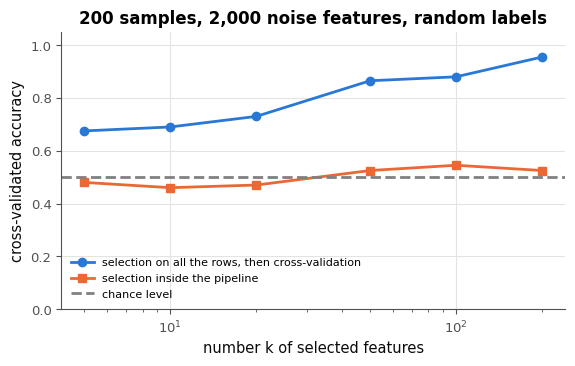

In [74]:
selected_24 = SelectKBest(f_classif, k=20).fit_transform(X_24, Y_24)          # the leak: the target of every row
leaky_24 = cross_val_score(LogisticRegression(max_iter=1000), selected_24, Y_24, cv=FOLDS_24).mean()
pipe_24 = make_pipeline(SelectKBest(f_classif, k=20), LogisticRegression(max_iter=1000))
honest_24 = cross_val_score(pipe_24, X_24, Y_24, cv=FOLDS_24).mean()
search_24 = GridSearchCV(pipe_24, {"selectkbest__k": KS_24}, cv=FOLDS_24).fit(X_24, Y_24)
inner_24 = search_24.best_score_
nested_24 = cross_val_score(GridSearchCV(pipe_24, {"selectkbest__k": KS_24}, cv=FOLDS_24), X_24, Y_24,
                            cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=1)).mean()
print_answer("15.24a", leaky_24)
print_answer("15.24b", honest_24)
print_answer("15.24c", inner_24)
print_answer("15.24d", nested_24)
if True:
    if not filled(leaky_24, honest_24):
        raise NotImplementedError("leaky_24, honest_24")
    curve_24 = []
    for k in KS_24:
        chosen_24 = SelectKBest(f_classif, k=k).fit_transform(X_24, Y_24)
        curve_24.append((cross_val_score(LogisticRegression(max_iter=1000), chosen_24, Y_24, cv=FOLDS_24).mean(),
                         cross_val_score(make_pipeline(SelectKBest(f_classif, k=k), LogisticRegression(max_iter=1000)),
                                         X_24, Y_24, cv=FOLDS_24).mean()))
    fig, ax = plt.subplots(figsize=(6.5, 3.6))
    ax.plot(KS_24, [a for a, _ in curve_24], "o-", label="selection on all the rows, then cross-validation")
    ax.plot(KS_24, [b for _, b in curve_24], "s-", label="selection inside the pipeline")
    ax.axhline(0.5, color="gray", ls="--", label="chance level")
    ax.set(xscale="log", xlabel="number k of selected features", ylabel="cross-validated accuracy", ylim=(0, 1.05),
           title="200 samples, 2,000 noise features, random labels")
    ax.legend(fontsize=8)
    plt.show()

In [75]:
wb.record("15.24a", leaky_24, decimals=3, mistakes={"relis la question : a) sélectionne les features AVANT la validation croisée, sur toutes les lignes": honest_24})
wb.record("15.24b", honest_24, decimals=3, mistakes={"relis la question : b) met SelectKBest dans le pipeline, refait dans chaque fold": leaky_24})
wb.record("15.24c", inner_24, decimals=3, mistakes={"relis la question : c) demande le best_score_ de la recherche entraînée sur X_24": nested_24})
wb.record("15.24d", nested_24, decimals=3, mistakes={"relis la question : d) demande une validation croisée qui refait toute la recherche dans chaque fold": inner_24})

WB_ANSWER {"decimals": 3, "hash": "b04b23737648751eb27af97c1841190315aa1f0132120e04eb4fa3249fae0805", "hash_coarse": "3669e68d0201a8c8e5b2d6b5e8a45a149073da8a5c79968e39a492af0b50d779", "id": "15.24a", "kind": "float", "magnitude": -1, "mistakes": {"b6e4c7c866ff3511fbf088c38fe7133b5336538adbcb423168b3af888775585b": "relis la question : a) sélectionne les features AVANT la validation croisée, sur toutes les lignes"}, "sign": 1}
📝 Ex 15.24a : réponse enregistrée (float, 3 décimale(s)).
WB_ANSWER {"decimals": 3, "hash": "d6683ccdc9cdb9fbf58bf77ed1186c6212c63af6f33eeb1ec9e4eeb23fa8e8fa", "hash_coarse": "d0459d8408009d5c541cb2d53a2fd1a8c6b3effc7b2243096b0ec3d6a6ddf304", "id": "15.24b", "kind": "float", "magnitude": -1, "mistakes": {"46fecfbe6aa215f5435a1f73d0513dac90751bc1582e001c0852ccd2372e9171": "relis la question : b) met SelectKBest dans le pipeline, refait dans chaque fold"}, "sign": 1}
📝 Ex 15.24b : réponse enregistrée (float, 3 décimale(s)).
WB_ANSWER {"decimals": 3, "hash": "5e1cfd7

💡 Sélection faite avant la validation croisée : 0,730 sur du bruit pur ; dans le pipeline : 0,470, le niveau du hasard. Les 20 features gardées sur toutes les lignes sont celles que le hasard a le mieux alignées sur les labels de toutes les lignes, celles de validation comprises : la validation croisée note un modèle qui a déjà vu ses réponses. La recherche sur $k$ a un `best_score_` de 0,545 : le meilleur de six réglages notés sur du bruit est un peu au-dessus du hasard (le maximum de scores bruités est optimiste) ; la validation croisée imbriquée, qui refait la recherche dans chaque fold, revient à 0,485. Dans un rapport : d), ou b) si $k$ est fixé d'avance. Au ch. 8 (60 exemples, 1 000 features), la sélection faite avant donnait 0,900 : avec plus d'exemples, la fuite est moindre, mais reste énorme. Une simple standardisation faite avant, qui ne regarde pas la cible, ne change presque rien (0,540 contre 0,530).

## Partie D · Décider, préparer, brancher, sauvegarder

Le seuil de décision (15.25) et les classes déséquilibrées (15.26), six familles de modèles sur les mêmes folds (15.27), le `ColumnTransformer` sur les manchots bruts (15.28), un estimateur de ta librairie dans scikit-learn (15.29), la sauvegarde d'un pipeline (15.30), puis le défi (15.31). La cellule suivante importe les derniers outils.

In [76]:
import joblib
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import VotingClassifier
from sklearn.metrics import make_scorer
from sklearn.model_selection import FixedThresholdClassifier, RepeatedStratifiedKFold, TunedThresholdClassifierCV, cross_val_predict
from sklearn.model_selection._search import BaseSearchCV
from sklearn.utils.class_weight import compute_class_weight

### Ex 15.25 — Régler le seuil de décision d'un classifieur 🔬 ★★★ ⏱️ 35 min
**Objectif :** choisir le seuil d'un classifieur d'après le coût de ses erreurs, à la main puis avec `TunedThresholdClassifierCV`.  
**Prérequis :** Ex 15.10 · ch. 3 (matrice de confusion, recall, seuil) · fiche, section « seuil de décision » · **Fil rouge :** synthétique · **Parcours :** R, C

Un problème binaire avec environ 15 % de positifs. Manquer un positif (un faux négatif) coûte **10**, une fausse alerte (un faux positif) coûte **1** ; `cost_25(y_true, y_pred)` calcule le coût total. Les 3 000 exemples sont coupés en trois : 1 470 pour entraîner (`X_FIT_25`), 630 pour valider (`X_VAL_25`), 900 pour le test, qui ne sert qu'à mesurer. `MODEL_25` est une régression logistique déjà entraînée sur la première partie. **Contrat** :
a) `default_cost_25` : le coût de `MODEL_25.predict` sur le test (le seuil 0,5) ;
b) `val_costs_25` : pour chaque seuil $t$ de `THRESHOLDS_25` (0,01 à 0,99), le coût sur la **validation** de la règle « classe 1 quand `predict_proba(X)[:, 1] >= t` » ;
c) `best_threshold_25` : le seuil de plus petit coût de validation (le premier, en cas d'égalité) ;
d) `test_cost_25` : le coût sur le test de la règle avec ce seuil ;
e) `theory_threshold_25` : le seuil qui minimise le coût **moyen** si les probabilités sont calibrées : compare l'espérance du coût des deux décisions pour un exemple de probabilité $p$ (un nombre exact) ;
f) `recalls_25` : la liste `[recall au seuil 0,5, recall au seuil de c)]` sur le test ;
`tuned_25` : `TunedThresholdClassifierCV(make_pipeline(StandardScaler(), LogisticRegression()), scoring=COST_SCORER_25, cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=0))`, entraîné sur l'entraînement et la validation réunis (`X_REST_25`, `Y_REST_25`) ; g) `tuned_threshold_25` : son `best_threshold_` ; h) `tuned_cost_25` : le coût de `tuned_25.predict` sur le test.

La vérification contrôle a) à h), puis trace le coût de validation selon le seuil.

Dans tes notes : pourquoi le meilleur seuil est-il si loin de 0,5 ? Compare c) et e) : qu'est-ce qui les rapproche, et qu'est-ce qui les sépare ? Qu'a fait `TunedThresholdClassifierCV` de plus que toi, et avec quelles données ? Que coûte un meilleur recall ?

In [77]:
X_25, Y_25 = make_classification(n_samples=3000, n_features=8, n_informative=4, weights=[0.85], class_sep=0.8,
                              flip_y=0.02, random_state=1525)      # about 15 % of positives (class 1)
X_REST_25, X_TEST_25, Y_REST_25, Y_TEST_25 = train_test_split(X_25, Y_25, test_size=0.3, random_state=1525, stratify=Y_25)
X_FIT_25, X_VAL_25, Y_FIT_25, Y_VAL_25 = train_test_split(X_REST_25, Y_REST_25, test_size=0.3, random_state=1525,
                                                          stratify=Y_REST_25)
COST_FN_25, COST_FP_25 = 10, 1        # a missed positive costs 10, a false alarm costs 1
THRESHOLDS_25 = np.round(np.arange(0.01, 1.0, 0.01), 2)


def cost_25(y_true, y_pred):
    """Total cost of the decisions y_pred: 10 per false negative, 1 per false positive."""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return int(COST_FN_25 * fn + COST_FP_25 * fp)


COST_SCORER_25 = make_scorer(lambda y_true, y_pred: -cost_25(y_true, y_pred))   # a scorer: larger is better
MODEL_25 = make_pipeline(StandardScaler(), LogisticRegression()).fit(X_FIT_25, Y_FIT_25)
print(len(Y_FIT_25), "to fit,", len(Y_VAL_25), "to validate,", len(Y_TEST_25), "to test")

1470 to fit, 630 to validate, 900 to test


15.25a: 1249
15.25b: [510.0, 478.0, 457.0, 440.0, 425.0, 421.0, 410.0, 404.0, 380.0, 361.0, 347.0, 362.0, 350.0, 358.0, 348.0, 379.0, 397.0, 391.0, 390.0, 409.0, 413.0, 442.0, 432.0, 443.0, 457.0, 471.0, 497.0, 511.0, 502.0, 527.0, 566.0, 571.0, 597.0, 604.0, 632.0, 669.0, 669.0, 695.0, 703.0, 710.0, 730.0, 750.0, 770.0, 768.0, 776.0, 776.0, 806.0, 815.0, 815.0, 835.0, 844.0, 864.0, 864.0, 864.0, 863.0, 873.0, 883.0, 893.0, 903.0, 903.0, 903.0, 923.0, 923.0, 923.0, 933.0, 933.0, 933.0, 932.0, 932.0, 952.0, 972.0, 982.0, 981.0, 981.0, 980.0, 980.0, 980.0, 980.0, 980.0, 980.0, 980.0, 980.0, 980.0, 980.0, 980.0, 980.0, 980.0, 980.0, 980.0, 980.0, 980.0, 980.0, 980.0, 980.0, 980.0, 980.0, 980.0, 980.0, 980.0]
15.25c: 0.11
15.25d: 736
15.25e: 0.09090909090909091
15.25f: [0.1206, 0.7305]
15.25g: 0.13812587017213784
15.25h: 759


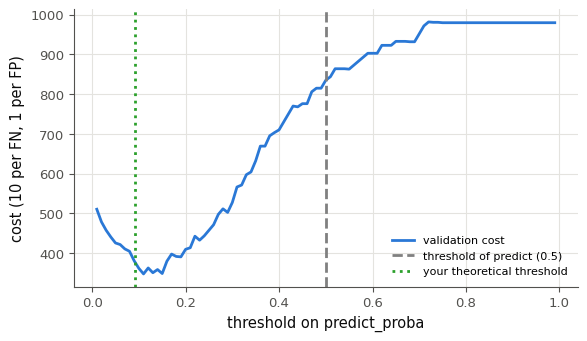

In [78]:
default_cost_25 = cost_25(Y_TEST_25, MODEL_25.predict(X_TEST_25))
val_proba_25 = MODEL_25.predict_proba(X_VAL_25)[:, 1]
val_costs_25 = [cost_25(Y_VAL_25, (val_proba_25 >= t).astype(int)) for t in THRESHOLDS_25]
best_threshold_25 = float(THRESHOLDS_25[int(np.argmin(val_costs_25))])
test_proba_25 = MODEL_25.predict_proba(X_TEST_25)[:, 1]
test_cost_25 = cost_25(Y_TEST_25, (test_proba_25 >= best_threshold_25).astype(int))
theory_threshold_25 = COST_FP_25 / (COST_FP_25 + COST_FN_25)   # predict 1 when p * 10 > (1 - p) * 1
recalls_25 = [recall_score(Y_TEST_25, MODEL_25.predict(X_TEST_25)),
              recall_score(Y_TEST_25, (test_proba_25 >= best_threshold_25).astype(int))]
tuned_25 = TunedThresholdClassifierCV(make_pipeline(StandardScaler(), LogisticRegression()), scoring=COST_SCORER_25,
                                      cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=0)).fit(X_REST_25, Y_REST_25)
tuned_threshold_25 = float(tuned_25.best_threshold_)
tuned_cost_25 = cost_25(Y_TEST_25, tuned_25.predict(X_TEST_25))
print_answer("15.25a", default_cost_25)
print_answer("15.25b", val_costs_25)
print_answer("15.25c", best_threshold_25)
print_answer("15.25d", test_cost_25)
print_answer("15.25e", theory_threshold_25)
print_answer("15.25f", recalls_25)
print_answer("15.25g", tuned_threshold_25)
print_answer("15.25h", tuned_cost_25)
if True:
    if not filled(val_costs_25):
        raise NotImplementedError("val_costs_25")
    if len(val_costs_25) != len(THRESHOLDS_25):
        print(f"❌ Ex 15.25 : val_costs_25 doit avoir un coût par seuil de THRESHOLDS_25 ({len(THRESHOLDS_25)}).")
    else:
        fig, ax = plt.subplots(figsize=(6.5, 3.6))
        ax.plot(THRESHOLDS_25, val_costs_25, label="validation cost")
        ax.axvline(0.5, color="gray", ls="--", label="threshold of predict (0.5)")
        if filled(theory_threshold_25):
            ax.axvline(float(theory_threshold_25), color="tab:green", ls=":", label="your theoretical threshold")
        ax.set(xlabel="threshold on predict_proba", ylabel="cost (10 per FN, 1 per FP)")
        ax.legend(fontsize=8)
        plt.show()

In [79]:
wb.record("15.25a", default_cost_25, fractional="un coût est un nombre entier d'unités (10 par faux négatif, 1 par faux positif)",
          mistakes={"tu as mesuré sur la validation : a) se mesure sur le test": cost_25(Y_VAL_25, MODEL_25.predict(X_VAL_25)),
                    "les poids sont inversés : un faux négatif coûte 10, un faux positif 1": int(confusion_matrix(Y_TEST_25, MODEL_25.predict(X_TEST_25)).ravel()[1] * 10 + confusion_matrix(Y_TEST_25, MODEL_25.predict(X_TEST_25)).ravel()[2])})
wb.record("15.25b", val_costs_25)
wb.record("15.25c", best_threshold_25, decimals=2, mistakes={"c'est le seuil le moins coûteux sur le TEST : on le choisit sur la validation": float(THRESHOLDS_25[int(np.argmin([cost_25(Y_TEST_25, (test_proba_25 >= t).astype(int)) for t in THRESHOLDS_25]))]),
                                                            "c'est la position du minimum dans la liste, pas le seuil lui-même": float(np.argmin(val_costs_25))})
wb.record("15.25d", test_cost_25, fractional="un coût est un nombre entier d'unités")
wb.record("15.25e", theory_threshold_25, decimals=4, mistakes={"les deux coûts sont échangés : décider « positif » ne coûte que si l'exemple est négatif (probabilité 1 − p), décider « négatif » que s'il est positif (probabilité p)": COST_FN_25 / (COST_FP_25 + COST_FN_25),
                                                              "le rapport des coûts n'est pas le seuil : écris l'espérance du coût de chaque décision, et cherche où elles s'égalent": COST_FP_25 / COST_FN_25})
wb.record("15.25f", recalls_25, decimals=4)
wb.record("15.25g", tuned_threshold_25, decimals=3)
wb.record("15.25h", tuned_cost_25, fractional="un coût est un nombre entier d'unités")

WB_ANSWER {"fractional": "un coût est un nombre entier d'unités (10 par faux négatif, 1 par faux positif)", "hash": "97c24a5586734826f176175dcd78cb3c36b151b57ceb657894991b2db1fe0b95", "id": "15.25a", "kind": "int", "magnitude": 3, "mistakes": {"1a99d9d0fd4944767231b259c7495814c286e9570343ccd908952a5084b06da0": "les poids sont inversés : un faux négatif coûte 10, un faux positif 1", "56e20a9dd8ec22a798d654cdbfb6100f99823c62014f53505e2133267bb2785c": "tu as mesuré sur la validation : a) se mesure sur le test"}, "sign": 1}
📝 Ex 15.25a : réponse enregistrée (int).
WB_ANSWER {"decimals": 0, "element_hashes": ["b01c0113c53688709dcf3f833ac9d0e85e7431a9c05a201eab3db62ef507bf99", "de35330831e5bace9b2291a6ce440390d1a83180ef417aff9e9786b0844e08ba", "e14aa9e363e7195ff245f237cd40649cc43789a16f0b26398c23fe78f5634c72", "a0ff1a15d3383aeee948fd262e2ad935a2343650ef4f6dd6c41df5aff27a0536", "6398a123839b797b45eb395916867346f249ff5d0e3f11e0b35088d64508e351", "685a7d3fdb5e29a1633437f13782de0d930513ac6e91eca

💡 Au seuil 0,5, le coût de test vaut 1 249 : le modèle ne trouve que 12 % des positifs (recall 0,121), et chaque oubli coûte 10. Sur la validation, le coût est le plus bas au seuil 0,11 (347) ; sur le test, ce seuil coûte 736, avec un recall de 0,730 et une precision de 0,224. La théorie, pour des probabilités calibrées : prédire 1 quand $10\,p > 1 \times (1 - p)$, soit $p > 1/11 \approx 0{,}0909$. Le seuil 0,11 en est proche parce qu'une régression logistique est à peu près calibrée, sans lui être égal (630 exemples de validation, et des probabilités pas tout à fait calibrées). `TunedThresholdClassifierCV` a choisi 0,138 par validation croisée sur les 2 100 exemples, en réentraînant le modèle dans chaque fold, puis l'a réentraîné sur tout : coût de test 759, proche de 736 (quelques erreurs d'écart sur 900 exemples). Variante : avec un faux négatif à 5, le seuil théorique passe à 1/6 et celui de la validation à 0,15.

### Ex 15.26 — Classes déséquilibrées : class_weight, rééchantillonnage et la bonne métrique (recall, PR-AUC) 📦 ★★★ ⏱️ 35 min
**Objectif :** comparer trois façons de traiter une classe rare, et les juger avec des mesures qui ne se laissent pas tromper.  
**Prérequis :** Ex 15.25 · ch. 3 (precision, recall, courbe precision-recall) · fiche, section « classes déséquilibrées » · **Fil rouge :** synthétique · **Parcours :** R, C

10 000 exemples, dont 2 % de positifs (la classe 1), coupés en 7 000 pour l'entraînement et 3 000 pour le test, en gardant les proportions. `report_26(modèle, X, y)` entraîne le modèle sur `(X, y)`, puis rend cinq mesures sur le test : `[accuracy, recall, precision, balanced accuracy, average precision]` (la dernière, l'aire sous la courbe precision-recall du ch. 3, se calcule sur `predict_proba`). **Contrat** (chaque réponse est la liste rendue par `report_26`) :
a) `dummy_26` : `DummyClassifier(strategy="most_frequent")`, entraîné sur l'entraînement ;
b) `plain_26` : `make_pipeline(StandardScaler(), LogisticRegression())` ;
c) `balanced_26` : le même pipeline, avec `LogisticRegression(class_weight="balanced")` ;
d) `under_26` : le pipeline de b), entraîné sur un entraînement **sous-échantillonné** : tous les positifs, plus autant de négatifs tirés sans remise avec `np.random.default_rng(1526).choice(indices des négatifs, size=nombre de positifs, replace=False)` (le test ne change pas) ;
e) `moved_26` : `FixedThresholdClassifier(le pipeline de b), threshold=0.1)`, entraîné sur tout l'entraînement ;
f) `weights_26` : la liste des poids que `class_weight="balanced"` donne aux classes 0 et 1 sur l'entraînement (`compute_class_weight` les calcule ; vérifie la formule de la fiche).

La vérification contrôle a) à f), puis affiche le tableau des cinq modèles.

Dans tes notes : que vaut l'accuracy de a), et que dit-elle ? Qu'ont en commun c), d) et e) ? Pourquoi l'average precision bouge-t-elle peu, alors que le recall et la precision changent beaucoup ? Quelle méthode choisirais-tu, et d'après quel coût ?

In [80]:
X_26, Y_26 = make_classification(n_samples=10_000, n_features=10, n_informative=4, n_redundant=2, weights=[0.98],
                              class_sep=2.0, flip_y=0.0, random_state=1526)     # 2 % of positives (class 1)
X_TRAIN_26, X_TEST_26, Y_TRAIN_26, Y_TEST_26 = train_test_split(X_26, Y_26, test_size=0.3, random_state=1526, stratify=Y_26)
print(int(Y_TRAIN_26.sum()), "positives out of", len(Y_TRAIN_26), "training examples;", int(Y_TEST_26.sum()), "out of",
      len(Y_TEST_26), "in the test")


def report_26(model, X_fit, y_fit):
    """Fit `model` on (X_fit, y_fit), then [accuracy, recall, precision, balanced accuracy, average precision] on the test
    (the average precision on predict_proba[:, 1])."""
    model.fit(X_fit, y_fit)
    predicted, scores = model.predict(X_TEST_26), model.predict_proba(X_TEST_26)[:, 1]
    return [accuracy_score(Y_TEST_26, predicted), recall_score(Y_TEST_26, predicted, zero_division=0),
            precision_score(Y_TEST_26, predicted, zero_division=0), balanced_accuracy_score(Y_TEST_26, predicted),
            average_precision_score(Y_TEST_26, scores)]

140 positives out of 7000 training examples; 60 out of 3000 in the test


In [81]:
dummy_26 = report_26(DummyClassifier(strategy="most_frequent"), X_TRAIN_26, Y_TRAIN_26)
plain_26 = report_26(make_pipeline(StandardScaler(), LogisticRegression()), X_TRAIN_26, Y_TRAIN_26)
balanced_26 = report_26(make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced")), X_TRAIN_26, Y_TRAIN_26)
positives_26 = np.flatnonzero(Y_TRAIN_26 == 1)
negatives_26 = np.random.default_rng(1526).choice(np.flatnonzero(Y_TRAIN_26 == 0), size=len(positives_26), replace=False)
kept_26 = np.concatenate([positives_26, negatives_26])
under_26 = report_26(make_pipeline(StandardScaler(), LogisticRegression()), X_TRAIN_26[kept_26], Y_TRAIN_26[kept_26])
moved_26 = report_26(FixedThresholdClassifier(make_pipeline(StandardScaler(), LogisticRegression()), threshold=0.1),
                     X_TRAIN_26, Y_TRAIN_26)
weights_26 = compute_class_weight("balanced", classes=np.array([0, 1]), y=Y_TRAIN_26).tolist()   # n / (K n_c)
for letter_26, name_26 in zip("abcde", ["dummy_26", "plain_26", "balanced_26", "under_26", "moved_26"]):
    print_answer(f"15.26{letter_26}", globals()[name_26])
print_answer("15.26f", weights_26)
if True:
    if not filled(plain_26, balanced_26):
        raise NotImplementedError("plain_26, balanced_26")
    rows_26 = {name: globals()[name + "_26"] for name in ["dummy", "plain", "balanced", "under", "moved"]
               if filled(globals()[name + "_26"])}
    print(pd.DataFrame(rows_26, index=["accuracy", "recall", "precision", "balanced acc.", "average precision"]).T.round(3))

15.26a: [0.98, 0.0, 0.0, 0.5, 0.02]
15.26b: [0.9867, 0.5167, 0.7381, 0.7565, 0.7216]
15.26c: [0.9563, 0.9833, 0.3122, 0.9696, 0.6757]
15.26d: [0.952, 0.9833, 0.2921, 0.9673, 0.6574]
15.26e: [0.978, 0.9333, 0.4746, 0.9561, 0.7216]
15.26f: [0.5102, 25.0]
          accuracy  recall  precision  balanced acc.  average precision
dummy        0.980   0.000      0.000          0.500              0.020
plain        0.987   0.517      0.738          0.756              0.722
balanced     0.956   0.983      0.312          0.970              0.676
under        0.952   0.983      0.292          0.967              0.657
moved        0.978   0.933      0.475          0.956              0.722


In [82]:
for letter_26, value_26 in zip("abcde", [dummy_26, plain_26, balanced_26, under_26, moved_26]):
    wb.record(f"15.26{letter_26}", value_26, decimals=3)
wb.record("15.26f", weights_26, decimals=3, mistakes={"les poids sont inversés : la classe rare reçoit le GRAND poids": weights_26[::-1],
                                                     "ce sont les proportions des classes : relis dans la documentation de compute_class_weight ce que vaut le poids d'une classe en mode \"balanced\"": (np.bincount(Y_TRAIN_26) / len(Y_TRAIN_26)).tolist()})

WB_ANSWER {"decimals": 3, "element_coarse": [["1287dc45990adf7740ccff27f173aad980eced070e45ffdd55ed875aa7d41632"], ["e4fd10ba5c856f96d889755cb2f4f256f778ee0562fb36b2adf73145fd5a9527"], ["fbc8e2303738ed9df337eaf1ea045ef33603811cdd7eaf279d7b699c0ac557c2"], ["4e60895f2f91f07c6cb17361384828748876c709b95470becfc61f11e3442216"], ["897a5124cc8d08d96d4af773360485681113c96ae2bc245dea8b010dcaa11581"]], "element_hashes": ["bb2a3675a35a5d0e61dc588776ae95db4d9353b5cd2d47d597d59401aead36ed", "4c792294226cb12bca9296e254b6ea598205836f330aa68e15fce460d6dad48f", "7e81ab6ce6b48974b9f5dee45e6708f4e73b75de26235bc31bcb2f5c5e428ad7", "649e3a3c15cb799a441cb3a70bc53200d060436d29a74a288c3f7e920ae54a38", "27fb4e49d08008429f3bdc80d29a2b5c03c067661dc6f59ed2d3f83c77b1fbe1"], "hash": "9ef925ce27669ddcb4e741baf79fc9007fdc0d34a872e95a922f553c463ca44b", "id": "15.26a", "kind": "array", "shape": [5]}
📝 Ex 15.26a : réponse enregistrée (array, 3 décimale(s)).
WB_ANSWER {"decimals": 3, "element_coarse": [["2b61d12ec7b72c89

💡 Le classifieur constant fait 0,980 d'accuracy et un recall nul : l'accuracy ne dit rien avec 2 % de positifs. La régression logistique fait 0,987, mais ne trouve que 52 % des positifs (precision 0,74). `class_weight="balanced"` (poids 0,510 et 25,0 : $n/(K\,n_c)$ = 7 000/(2 × 6 860) et 7 000/(2 × 140)), le sous-échantillonnage et le seuil 0,1 font tous trois monter le recall (0,98, 0,98 et 0,93) et chuter la precision (0,31, 0,29 et 0,47) : les trois déplacent la décision vers la classe rare. L'average precision bouge peu (0,722, 0,676, 0,657 et 0,722) : elle ne dépend que de l'ordre des scores, pas du seuil ; déplacer le seuil ne la change pas du tout, la repondération et le sous-échantillonnage, qui changent le modèle, la baissent un peu (le sous-échantillonnage jette 98 % des négatifs). On choisit d'après le coût de chaque sorte d'erreur, comme en 15.25.

### Ex 15.27 — La même validation croisée pour six familles de modèles scikit-learn : score moyen, écart-type et temps 📦 ★★★ ⏱️ 40 min
**Objectif :** comparer honnêtement des familles de modèles, sur les mêmes folds, en score, en dispersion et en temps.  
**Prérequis :** ch. 12 (mise à l'échelle) · ch. 13 (classifieurs) · ch. 14 (ensembles) · Ex 15.9 · fiche §15.1, §15.6 à §15.8 · **Fil rouge :** Penguins · **Parcours :** C

Prédire le **sexe** des 333 manchots d'après leurs 4 mesures, sans l'espèce : un problème plus difficile que l'espèce. Six familles de modèles, chacune avec ses réglages par défaut (`FAMILIES_27`), et les mêmes 15 folds pour toutes (`FOLDS_27`, 5 folds répétés 3 fois). **Contrat** :
`compare_27(models, X, y, cv)` : pour chaque nom et chaque modèle du dictionnaire, `cross_validate(model, X, y, cv=cv)` ; rend un `DataFrame` indexé par les noms, aux colonnes `"mean"` et `"std"` (`ddof=1`) des accuracies de validation et `"fit_ms"` (la durée moyenne de `fit`, en millisecondes), trié par `"mean"` décroissant ; la vérification en tire a) les moyennes et b) les écarts-types, dans l'ordre de `FAMILIES_27` ;
c) `raw_knn_27` : la moyenne des accuracies de validation de `KNeighborsClassifier()` **sans** mise à l'échelle, sur `FOLDS_27` ;
d) `pca_svm_27` : la même pour `make_pipeline(StandardScaler(), PCA(n_components=2), SVC())`.

La vérification appelle `compare_27` sur les six familles, contrôle le tableau (forme, ordre, moyennes et écarts-types ; les durées dépendent de la machine et ne sont pas vérifiées), puis c) et d).

Dans tes notes : les écarts entre les quatre premières familles sont-ils plus grands que leurs écarts-types ? Quelle famille se détache des autres, et pourquoi (pense à ce que mélangent les mesures quand on ne connaît pas l'espèce) ? Combien de fois plus lent est l'ensemble le plus lent que la régression logistique, pour quel gain ? Que t'apprennent c) et d) sur la préparation ?

In [83]:
X_27 = PENGUINS[MEASURES].to_numpy()          # the 4 measures of the 333 penguins
Y_27 = PENGUINS["sex"].to_numpy()             # the target: male or female
FOLDS_27 = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=1527)   # the same 15 folds for all
FAMILIES_27 = {"logistic": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
               "knn": make_pipeline(StandardScaler(), KNeighborsClassifier()),
               "svm": make_pipeline(StandardScaler(), SVC()),
               "naive_bayes": GaussianNB(),
               "forest": RandomForestClassifier(random_state=0),
               "boosting": HistGradientBoostingClassifier(random_state=0)}

In [84]:
def compare_27(models, X, y, cv):
    """For each name and model of the dict `models`, cross_validate(model, X, y, cv=cv). Return a pandas DataFrame indexed
    by the names, with the columns "mean" and "std" (ddof=1) of the validation accuracies and "fit_ms" (the mean fit time,
    in milliseconds), sorted by decreasing "mean"."""
    rows = {}
    for name, model in models.items():
        result = cross_validate(model, X, y, cv=cv)
        rows[name] = {"mean": result["test_score"].mean(), "std": result["test_score"].std(ddof=1),
                      "fit_ms": 1000 * result["fit_time"].mean()}
    return pd.DataFrame.from_dict(rows, orient="index").sort_values("mean", ascending=False)


raw_knn_27 = cross_val_score(KNeighborsClassifier(), X_27, Y_27, cv=FOLDS_27).mean()
pca_svm_27 = cross_val_score(make_pipeline(StandardScaler(), PCA(n_components=2), SVC()), X_27, Y_27, cv=FOLDS_27).mean()
if True:
    table_27 = compare_27(FAMILIES_27, X_27, Y_27, FOLDS_27)
    if returned("15.27", "compare_27", table_27):
        shape_ok_27 = (isinstance(table_27, pd.DataFrame) and list(table_27.columns) == ["mean", "std", "fit_ms"]
                       and sorted(table_27.index) == sorted(FAMILIES_27))
        verdict("15.27", shape_ok_27, "compare_27 rend une ligne par famille et les colonnes mean, std, fit_ms.",
                f"compare_27 doit rendre un DataFrame indexé par les noms de FAMILIES_27, aux colonnes mean, std, fit_ms.")
        if shape_ok_27:
            verdict("15.27", list(table_27["mean"]) == sorted(table_27["mean"], reverse=True),
                    "le tableau est trié par score moyen décroissant.", "trie le tableau par score moyen décroissant.")
            print(table_27.round({"mean": 3, "std": 3, "fit_ms": 1}))
            print_answer("15.27a", [float(table_27.loc[name, "mean"]) for name in FAMILIES_27], computed=True)
            print_answer("15.27b", [float(table_27.loc[name, "std"]) for name in FAMILIES_27], computed=True)
print_answer("15.27c", raw_knn_27)
print_answer("15.27d", pca_svm_27)

✅ Ex 15.27 : compare_27 rend une ligne par famille et les colonnes mean, std, fit_ms.
✅ Ex 15.27 : le tableau est trié par score moyen décroissant.
              mean    std  fit_ms
forest       0.909  0.041   358.1
knn          0.906  0.029     1.5
boosting     0.905  0.038  4616.9
svm          0.898  0.041     5.7
logistic     0.895  0.036   200.2
naive_bayes  0.729  0.071     1.8
15.27a: [0.8948, 0.9058, 0.8978, 0.7287, 0.9088, 0.9048]
15.27b: [0.0363, 0.0288, 0.0415, 0.0712, 0.0412, 0.0381]
15.27c: 0.7755314337403889
15.27d: 0.8326549072817728


In [85]:
wb.record("15.27a", [float(table_27.loc[name, "mean"]) for name in FAMILIES_27], decimals=5)
std0_27 = [float(np.std(cross_val_score(model, X_27, Y_27, cv=FOLDS_27))) for model in FAMILIES_27.values()]
wb.record("15.27b", [float(table_27.loc[name, "std"]) for name in FAMILIES_27], decimals=5,
          mistakes={"écarts-types avec ddof=0 : l'énoncé demande ddof=1": std0_27})
wb.record("15.27c", raw_knn_27, decimals=4, mistakes={"relis la question : c) demande le kNN SANS mise à l'échelle": float(table_27.loc["knn", "mean"])})
wb.record("15.27d", pca_svm_27, decimals=4, mistakes={"relis la question : d) ajoute PCA(n_components=2) entre le scaler et le SVC": float(table_27.loc["svm", "mean"])})

WB_ANSWER {"decimals": 5, "element_coarse": [["564e957f85f1d134602a14fbde9f36f92c8a01ed84ea056281ad26737b7984bd"], ["d24953a2200afe7f8c82a623bcf8f2c06e97e226d3ed1dc6648c64a9724a9b66"], ["d993d7e7701af2972c0cf518fb3d427b28d1c0f1e528affb35e165ce6fe9b40a"], ["b4d17d1b7de4ed74f0f817f6d57f62f12212b8f4098ae834d497aa901fdcff1e"], ["77071b7e30d69d403eca9eba506db7abff3387f4c7f829c4b24980eb834c4693"], ["e288a988719790b2998aecbe1f76a6b9ff03ba86daf158ce652906125b4dfa18"]], "element_hashes": ["eb6072a93ede0db52162eb28ebc4f99deafa13d1b9730324e71a00bd6c151be2", "3c4ec07d3612999414a769c88ec931cd0bd225e9977bff5a202c543e71bfb026", "97e1b811dfcc2d10874d7c6b7018f297014a83470a4d79bc5e394ae34ee1e497", "960f7088f0ebeb24ff9d548fdafda0f7e47d8006681a8e2385a759a67aac5bad", "b23f8af9bfd32f72b44890544f42b8f52ca01f8622eb8de426943b4125278d27", "981e98d28d724dc2c471f82facf8ec8991dc3957c145c0c28e4c50f3f29d6030"], "hash": "cd8257c5625fba1ca7da4447bef244c846dc4d944d35f624ab13797f1536497c", "id": "15.27a", "kind": "array

WB_ANSWER {"decimals": 5, "element_coarse": [["3c6b25be21c35d2c294baaac2e616da97e134f2e3131955d8b86a5b321472350"], ["6298f02e26fb861bb0c99499bec98bd6f06b0d5097d18adc2a298752cbd47e3e"], ["71916c2f4f9789597c26e8ef0866f12145f19b7cec78c5bbbd8bbdd8d1e89f07"], ["fe2f98361ffc6f783a4c7f03ed158226be4194afc31494c16cc68b071a1e0d9c"], ["16ea9f4190cd9605e7e5237b288b9896df4b69378f063270b37fa7b99935e1e5"], ["8e904f790c1b3aa31df3eb46d65f41514db65db28ab7244419129b714e6f344c"]], "element_hashes": ["827dd1ab14c46b3bd1e213ddf69ecf653020597b3f2cd3ddf749ac462c07781f", "6ca05246ed8d2e442b4119ec2cd605649b2561326236179ab49d8bc17e58c8d3", "a4dcd6b3f61b729a4dbd97f2d5065d6a0fb409d306a8149f84ad9fd388f0d016", "c3403840d93155b56e58ad0243fcb24faa4d0f37a66f7af31a6f0ffc22cbc417", "e1e189d956f35003c71e3afdf204e5c3d08b19496004ee2e8906df160eed2c2f", "d9063d7f809449655e92aeb23c2c1e9e7f9de3d9bf3505257872f409810c619e"], "hash": "7ab3e1fdcc8afd4d8962afdb35be47877282121aab966fbcb49a7f649c1d2808", "id": "15.27b", "kind": "array

💡 Classement : forêt 0,909, kNN 0,906, boosting 0,905, SVM 0,898, régression logistique 0,895, Naïve Bayes 0,729. Les cinq premiers sont à moins de 0,015 les uns des autres, avec des écarts-types de 0,03 à 0,04 : ces folds ne les départagent pas. Naïve Bayes suppose chaque mesure gaussienne et indépendante dans chaque sexe ; sans l'espèce, chaque mesure mélange trois espèces (une femelle Gentoo pèse plus qu'un mâle Adélie), et les mesures sont corrélées : il tombe à 0,729 (espèce par espèce, par une validation croisée `cv=5` dans chaque espèce, il ferait 0,90 à 0,93). La forêt et le boosting sont plusieurs dizaines de fois plus lents que la régression logistique, pour un gain non significatif. Sans mise à l'échelle, le kNN tombe à 0,776 : la masse, en grammes, écrase les trois autres mesures, en millimètres, dans la distance. Une PCA à deux composantes devant le SVM (0,833) jette de l'information utile.

### Ex 15.28 — ColumnTransformer sur Penguins brut 📦 ★★★ ⏱️ 45 min
**Objectif :** préparer des données hétérogènes, avec des valeurs manquantes et des catégories, dans un seul pipeline sans fuite.  
**Prérequis :** Ex 15.22 · ch. 12 (imputation, one-hot, fichier brut des manchots) · fiche, section « données hétérogènes » · **Fil rouge :** Penguins · **Parcours :** R, C

Le fichier brut des manchots du ch. 12 (`penguins_raw`, 344 lignes), sans ses colonnes d'identifiants, de dates et de commentaires, ni ses colonnes constantes : 6 colonnes de nombres (avec des valeurs manquantes) et 3 de texte (`Island`, `Clutch Completion`, `Sex`, avec des valeurs manquantes). La cible : l'espèce. **Contrat** :
`numeric_28` : un pipeline `SimpleImputer(strategy="median")` puis `StandardScaler()` ; `categorical_28` : un pipeline `SimpleImputer(strategy="most_frequent")` puis `OneHotEncoder(handle_unknown="ignore", sparse_output=False)` ; `prep_28` : un `ColumnTransformer` à deux branches nommées `"num"` et `"cat"`, les colonnes choisies par `make_column_selector` (les nombres pour `"num"`, le texte, `dtype_include=object`, pour `"cat"`) ;
`model_28` : `make_pipeline(prep_28, LogisticRegression(max_iter=1000))`, entraîné sur `X_RAW_28`, `Y_28` ; a) `n_columns_28` : le nombre de colonnes que produit le `ColumnTransformer` entraîné (`model_28[0]`) ; `names_28` : la liste de leurs noms (`get_feature_names_out`) ;
b) `cv_28` : la moyenne de `cross_val_score(clone(model_28), X_RAW_28, Y_28, cv=FOLDS_28)` ;
c) `new_28` : la liste des espèces que `model_28` prédit pour les deux manchots de `NEW_28`, dont les colonnes sont dans un autre ordre, avec une île jamais vue et des valeurs manquantes ;
`search_28` : une `GridSearchCV(clone(model_28), ..., cv=FOLDS_28)` sur la stratégie de l'imputeur des nombres (`["mean", "median"]`) et le `C` de la régression logistique (`[0.01, 1, 100]`), entraînée sur `X_RAW_28`, `Y_28` (les noms des hyperparamètres : `pipe.get_params().keys()`) ; d) `ties_28` : le nombre de candidats classés premiers ; e) `weak_28` : le score moyen de validation du candidat qui a la médiane et `C = 0.01`.

La vérification contrôle a) à e), et les noms de `names_28`.

Dans tes notes : d'où vient le nombre de colonnes de a) ? Que se passe-t-il pour l'île inconnue de `NEW_28` ? Pourquoi l'ordre des colonnes de `NEW_28` ne gêne-t-il pas ? Pourquoi cette validation croisée est-elle honnête, alors que l'imputation regarde des moyennes ou des médianes ?

In [86]:
RAW_28 = wb.datasets.load_penguins_raw()                       # 344 penguins, the file of the ch. 12
DROP_28 = ["studyName", "Sample Number", "Region", "Stage", "Individual ID", "Date Egg", "Comments", "Species"]
X_RAW_28 = RAW_28.drop(columns=DROP_28)                         # 6 numeric columns and 3 text columns, with NaN
Y_28 = RAW_28["Species"].str.split().str[0].to_numpy()          # Adelie, Chinstrap or Gentoo
FOLDS_28 = StratifiedKFold(n_splits=5, shuffle=True, random_state=1528)
NEW_28 = pd.DataFrame({"Sex": [np.nan, "FEMALE"], "Island": ["Anvers", "Torgersen"],    # two new penguins, the columns
                       "Flipper Length (mm)": [216.0, 186.0], "Body Mass (g)": [5300.0, 3450.0],   # in another order,
                       "Culmen Depth (mm)": [15.2, 18.1], "Culmen Length (mm)": [47.5, 38.6],      # an island never
                       "Clutch Completion": ["Yes", np.nan], "Delta 15 N (o/oo)": [np.nan, 8.9],   # seen, NaN
                       "Delta 13 C (o/oo)": [np.nan, -25.8]})
print(X_RAW_28.shape, "· missing values per column:", X_RAW_28.isna().sum().to_dict())

(344, 9) · missing values per column: {'Island': 0, 'Clutch Completion': 0, 'Culmen Length (mm)': 2, 'Culmen Depth (mm)': 2, 'Flipper Length (mm)': 2, 'Body Mass (g)': 2, 'Sex': 11, 'Delta 15 N (o/oo)': 14, 'Delta 13 C (o/oo)': 13}


In [87]:
numeric_28 = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
categorical_28 = make_pipeline(SimpleImputer(strategy="most_frequent"),
                               OneHotEncoder(handle_unknown="ignore", sparse_output=False))
prep_28 = ColumnTransformer([("num", numeric_28, make_column_selector(dtype_include="number")),
                             ("cat", categorical_28, make_column_selector(dtype_include=object))])
model_28 = make_pipeline(prep_28, LogisticRegression(max_iter=1000)).fit(X_RAW_28, Y_28)
names_28 = model_28[0].get_feature_names_out().tolist()
n_columns_28 = len(names_28)
cv_28 = cross_val_score(clone(model_28), X_RAW_28, Y_28, cv=FOLDS_28).mean()
new_28 = model_28.predict(NEW_28).tolist()                      # columns found by name: their order does not matter
search_28 = GridSearchCV(clone(model_28), {"columntransformer__num__simpleimputer__strategy": ["mean", "median"],
                                           "logisticregression__C": [0.01, 1, 100]}, cv=FOLDS_28).fit(X_RAW_28, Y_28)
results_28 = pd.DataFrame(search_28.cv_results_)
ties_28 = int((results_28["rank_test_score"] == 1).sum())
weak_28 = float(results_28.loc[(results_28["param_columntransformer__num__simpleimputer__strategy"] == "median")
                               & (results_28["param_logisticregression__C"] == 0.01), "mean_test_score"].iloc[0])
print_answer("15.28a", n_columns_28)
if True:
    if not filled(names_28):
        raise NotImplementedError("names_28")
    names_shown_28 = [str(name) for name in names_28]
    expected_28 = {"num__Culmen Length (mm)", "num__Delta 13 C (o/oo)", "cat__Island_Biscoe", "cat__Sex_MALE",
                   "cat__Clutch Completion_No"}
    verdict("15.28", expected_28 <= set(names_shown_28),
            "les noms de colonnes sont ceux du ColumnTransformer (nom de la branche, deux tirets bas, colonne).",
            "names_28 doit venir de get_feature_names_out() du ColumnTransformer entraîné, branches nommées \"num\" et \"cat\".")
print_answer("15.28b", cv_28)
if filled(new_28) and (isinstance(new_28, str) or np.ndim(new_28) != 1 or len(new_28) != 2):
    print("❌ Ex 15.28c : new_28 doit être une liste de deux espèces, une par manchot de NEW_28, dans l'ordre des lignes.")
else:
    print_answer("15.28c", ", ".join(str(species) for species in new_28) if isinstance(new_28, (list, tuple, np.ndarray, pd.Series)) else new_28)
print_answer("15.28d", ties_28)
print_answer("15.28e", weak_28)

15.28a: 13
✅ Ex 15.28 : les noms de colonnes sont ceux du ColumnTransformer (nom de la branche, deux tirets bas, colonne).
15.28b: 0.9971014492753623
15.28c: Gentoo, Adelie
15.28d: 4
15.28e: 0.9768115942028984


In [88]:
wb.record("15.28a", n_columns_28, fractional="on demande un nombre de colonnes",
          mistakes={"as-tu gardé les colonnes de texte ? Les deux branches mettent leurs colonnes côte à côte": 6,
                    "les colonnes de texte deviennent une colonne par catégorie, pas une colonne chacune": 9})
wb.record("15.28b", cv_28, decimals=4)
wb.record("15.28c", ", ".join(new_28), mistakes={"l'ordre compte : une espèce par manchot de NEW_28, dans l'ordre des lignes": ", ".join(new_28[::-1])})
wb.record("15.28d", ties_28, choices=list(range(1, 7)), fractional="on demande un nombre de candidats",
          mistakes={f"{k} candidat(s) au premier rang ? Plusieurs candidats peuvent avoir exactement la même moyenne : compte toutes les lignes où rank_test_score vaut 1": k
                    for k in range(1, 7) if k != ties_28})
mean_weak_28 = float(results_28.loc[(results_28["param_columntransformer__num__simpleimputer__strategy"] == "mean")
                                    & (results_28["param_logisticregression__C"] == 0.01), "mean_test_score"].iloc[0])
wb.record("15.28e", weak_28, decimals=4, mistakes={"c'est le candidat avec la moyenne : e) demande la médiane et C = 0,01": mean_weak_28} if abs(mean_weak_28 - weak_28) > 1e-4 else {})

WB_ANSWER {"fractional": "on demande un nombre de colonnes", "hash": "48ddae3b4f92552356c57b9b0ede5681760f4de6aeb688a16c41b94fbf64b903", "id": "15.28a", "kind": "int", "magnitude": 1, "mistakes": {"86c3a05c345b29e693cb673891465c04284db4e084834522650648997bf9370c": "les colonnes de texte deviennent une colonne par catégorie, pas une colonne chacune", "9ee602c36dda7e8226d8384129617db30f30505507098095648d8e8a53297c25": "as-tu gardé les colonnes de texte ? Les deux branches mettent leurs colonnes côte à côte"}, "sign": 1}
📝 Ex 15.28a : réponse enregistrée (int).
WB_ANSWER {"decimals": 4, "hash": "4683f4e0101d45401cfdb05e7ddd59c9141e9579606f07f848f0eb67dd3afb74", "hash_coarse": "339d7d324091791f811bca306a9925645d14942db947ee4e32de81492b972299", "id": "15.28b", "kind": "float", "magnitude": -1, "sign": 1}
📝 Ex 15.28b : réponse enregistrée (float, 4 décimale(s)).
WB_ANSWER {"hash": "e176ee311269cbd6c1967432944bf85d272c43d6b37433602d40a20346a9fed0", "id": "15.28c", "kind": "str", "mistakes": {

💡 Le `ColumnTransformer` produit 13 colonnes : les 6 nombres, puis 7 colonnes one-hot (`Island` : 3, `Clutch Completion` : 2, `Sex` : 2, une fois les valeurs manquantes remplacées). Validation croisée : 0,997. Pour `NEW_28` : Gentoo (probabilité 0,987) et Adélie (0,998) : l'île inconnue est codée par une ligne de zéros (`handle_unknown="ignore"`), les valeurs manquantes par les médianes et la catégorie la plus fréquente apprises à l'entraînement ; les colonnes se trouvent par leur nom, et l'ordre de `NEW_28` ne compte pas. La validation croisée est honnête parce que médianes, moyennes, écarts-types et catégories sont réappris dans chaque fold (le pipeline est cloné). La recherche : 4 candidats sur 6 font 0,997 (la moyenne ou la médiane, `C` = 1 ou 100), et `best_params_` prend le premier ; avec `C = 0.01` et la médiane, 0,977 : une régularisation trop forte coûte deux points, l'imputation presque rien.

### Ex 15.29 — Quand scikit-learn refuse un estimateur mylearn 🐛 ★★★ ⏱️ 35 min
**Objectif :** comprendre ce que scikit-learn attend d'un estimateur, et réparer un adaptateur qui ne le respecte pas.  
**Prérequis :** ch. 13 (ton `KNeighborsClassifier`, 13.14) · Ex 15.17 · 0A (héritage) · fiche, section « brancher ton propre estimateur » · **Fil rouge :** Penguins · **Parcours :** C

Ta librairie `mylearn` n'hérite de rien de scikit-learn : ses classes suivent les conventions, mais n'ont ni `get_params` ni `set_params`. Les données : les 333 manchots **dans l'ordre du fichier** (triés par espèce), décrits par les deux mesures du bec, en millimètres tous les deux (pas besoin de mise à l'échelle). **Contrat** :
a) `error_29` : le **nom** de l'exception (une chaîne, comme `"ValueError"`) que lève `cross_val_score(mylearn.neighbors.KNeighborsClassifier(), X_29, Y_29, cv=5)` ; essaie-le dans une cellule à toi, et lis le message ;
ensuite, un collègue a écrit l'adaptateur `MylearnKNN_29`, qui enveloppe ton `KNeighborsClassifier` du ch. 13 pour le donner à scikit-learn. Il a **trois** bugs : trouve-les et corrige-les, sans changer son nom de classe ni ce qu'il calcule ; son hyperparamètre doit s'appeler `n_neighbors`, comme dans scikit-learn.

La vérification contrôle a), puis trois points, dans l'ordre où ils se masquent : 1) `clone` et `get_params` marchent ; 2) scikit-learn reconnaît l'adaptateur comme un classifieur, et `cross_val_score(..., cv=5)` donne les scores de folds stratifiés (comparés à `by_hand_29`, qui entraîne ton `KNeighborsClassifier` à la main dans chaque fold) ; 3) une recherche sur `n_neighbors` donne bien des scores différents, les mêmes qu'à la main. Le point 1 doit passer pour que les deux autres soient vérifiés ; quand les trois passent, elle relève b) la moyenne de `cross_val_score(MylearnKNN_29(), X_29, Y_29, cv=5)` et c) le `n_neighbors` choisi par la recherche. Elle attend (⏳) que ton `KNeighborsClassifier` soit écrit (13.14).

Dans tes notes : pour chaque bug, le symptôme, et la règle de la fiche qu'il viole. Lesquels font une erreur, lesquels se taisent ? Pourquoi le bug du point 2 donne-t-il des scores si mauvais sur ces données ?

In [89]:
X_29 = PENGUINS[["bill_length_mm", "bill_depth_mm"]].to_numpy()   # two measures in millimetres: no scaling needed
Y_29 = PENGUINS["species"].to_numpy()                                # sorted by species, as in the file
KS_29 = [1, 5, 25, 75]


def by_hand_29(k, n_splits=5):
    """The oracle: StratifiedKFold(n_splits) without shuffling, YOUR mylearn KNeighborsClassifier fitted by hand in each
    fold; returns the n_splits accuracies."""
    scores = []
    for train, val in StratifiedKFold(n_splits=n_splits).split(X_29, Y_29):
        knn = mylearn.neighbors.KNeighborsClassifier(n_neighbors=k)
        knn.fit(X_29[train], Y_29[train])
        scores.append(float(np.mean(np.asarray(knn.predict(X_29[val])) == Y_29[val])))
    return scores

In [90]:
error_29 = "TypeError"     # clone() needs get_params, which mylearn does not provide


class MylearnKNN_29(ClassifierMixin, BaseEstimator):   # fix 2: the mixin first, or is_classifier is False
    """scikit-learn adapter around mylearn.neighbors.KNeighborsClassifier (the k-nearest neighbours of ch. 13)."""

    def __init__(self, n_neighbors=5):                  # fix 1: the argument has the name of the attribute
        self.n_neighbors = n_neighbors                  # fix 3: __init__ only stores; the model is built in fit

    def fit(self, X, y):
        self.model_ = mylearn.neighbors.KNeighborsClassifier(n_neighbors=self.n_neighbors)
        self.model_.fit(X, y)
        self.classes_ = self.model_.classes_
        return self

    def predict(self, X):
        return self.model_.predict(X)
print_answer("15.29a", error_29)
if True:
    mylearn.neighbors.KNeighborsClassifier(n_neighbors=1).fit(X_29[:10], Y_29[:10]).predict(X_29[:2])   # ⏳ until 13.14 is written
    POINTS_29 = ["clone et get_params marchent : le constructeur range son argument sous son nom",
                 "scikit-learn reconnaît l'adaptateur comme un classifieur (folds stratifiés)",
                 "set_params change vraiment le modèle : une recherche sur n_neighbors donne des scores différents"]
    try:
        clone(MylearnKNN_29())                           # what cross_val_score does first, with the default arguments
        params_29 = clone(MylearnKNN_29(n_neighbors=7)).get_params()
        point1_29 = params_29 == {"n_neighbors": 7}
        why1_29 = f"get_params rend {params_29} au lieu de {{'n_neighbors': 7}}"
    except Exception as exc:
        point1_29, why1_29 = False, f"{type(exc).__name__} : {str(exc)[:200]}"
    verdict("15.29", point1_29, f"point 1 : {POINTS_29[0]}.", f"point 1 : {why1_29}.")
    if not point1_29:
        print("⏳ Ex 15.29 : points 2 et 3 : corrige d'abord le point 1 (scikit-learn ne peut même pas copier l'objet).")
    else:
        mine_29 = cross_val_score(MylearnKNN_29(n_neighbors=5), X_29, Y_29, cv=5)
        classifier_29 = is_classifier(MylearnKNN_29())
        why2_29 = (f"is_classifier(MylearnKNN_29()) vaut False : relis l'ordre d'héritage (fiche, « brancher ton propre estimateur »)"
                   if not classifier_29 else "vérifie que l'adaptateur calcule la même chose que ton KNeighborsClassifier")
        verdict("15.29", classifier_29 and np.allclose(mine_29, by_hand_29(5)),
                f"point 2 : {POINTS_29[1]}.",
                f"point 2 : avec cv=5, tes scores sont {np.round(mine_29, 3).tolist()} au lieu de "
                f"{np.round(by_hand_29(5), 3).tolist()} (folds stratifiés) ; {why2_29}.")
        search_29 = GridSearchCV(MylearnKNN_29(), {"n_neighbors": KS_29}, cv=StratifiedKFold(n_splits=5)).fit(X_29, Y_29)
        found_29 = search_29.cv_results_["mean_test_score"]
        expected_29 = [np.mean(by_hand_29(k)) for k in KS_29]
        stored_29 = sorted(vars(MylearnKNN_29(n_neighbors=3)))
        if not np.allclose(found_29, expected_29):
            why3_29 = (f"la recherche donne {np.round(found_29, 3).tolist()} pour n_neighbors = {KS_29}, au lieu de "
                       f"{np.round(expected_29, 3).tolist()} : le modèle utilise-t-il vraiment self.n_neighbors au moment de fit ?")
        else:
            why3_29 = (f"__init__ range {stored_29} : il ne doit rien faire d'autre que ranger son argument n_neighbors "
                       f"(le modèle se construit dans fit).")
        verdict("15.29", np.allclose(found_29, expected_29) and stored_29 == ["n_neighbors"], f"point 3 : {POINTS_29[2]}.",
                f"point 3 : {why3_29}")
        print_answer("15.29b", float(np.mean(mine_29)), computed=True)
        print_answer("15.29c", search_29.best_params_["n_neighbors"])

15.29a: TypeError
✅ Ex 15.29 : point 1 : clone et get_params marchent : le constructeur range son argument sous son nom.
✅ Ex 15.29 : point 2 : scikit-learn reconnaît l'adaptateur comme un classifieur (folds stratifiés).


✅ Ex 15.29 : point 3 : set_params change vraiment le modèle : une recherche sur n_neighbors donne des scores différents.
15.29b: 0.9639077340569878
15.29c: 5


In [91]:
wb.record("15.29a", error_29, mistakes={"le message vient de clone : quelle exception lève-t-il quand un objet n'a pas get_params ?": "AttributeError",
                                        "relis le type de l'exception, au début de la dernière ligne du message": "ValueError"})
wb.record("15.29b", float(np.mean(mine_29)), decimals=4,
          mistakes={"ce sont des folds non stratifiés : avec cv=5, un classifieur reconnu reçoit des folds stratifiés": float(np.mean(cross_val_score(MylearnKNN_29(), X_29, Y_29, cv=KFold(5))))})
wb.record("15.29c", search_29.best_params_["n_neighbors"], choices=KS_29, fractional="on demande une valeur de n_neighbors",
          mistakes={f"n_neighbors = {k} : est-ce le meilleur de la recherche ?": k for k in KS_29 if k != search_29.best_params_["n_neighbors"]})

WB_ANSWER {"hash": "261bf9cc454bb1c7b3b3a56dc5cdd8b361a53bf8fc4cd3cd0146d4a2466c51c9", "id": "15.29a", "kind": "str", "mistakes": {"003ce3a72eac0ad1a45aa7bc7d7defe9aedfc5d3cf5a727dba296d7c7018980f": "le message vient de clone : quelle exception lève-t-il quand un objet n'a pas get_params ?", "5eb088b0f5d8c4beee60204e036de835047d7bae85ac0f7a39f7a6ee67a0ab4f": "relis le type de l'exception, au début de la dernière ligne du message"}}
📝 Ex 15.29a : réponse enregistrée (str).
WB_ANSWER {"decimals": 4, "hash": "fa0b3f524b22110151324c23857ac1fc8e1b9ffbb99ca9a12cbce20fca5650ff", "hash_coarse": "af820f135ce456118f70fedf13d9df33536b6124f5169fb5349972438afa423a", "id": "15.29b", "kind": "float", "magnitude": -1, "mistakes": {"0a0ebc2d874c358ee01033cddce2fa543adc41f74c28c2a8bbd79667f1601666": "ce sont des folds non stratifiés : avec cv=5, un classifieur reconnu reçoit des folds stratifiés"}, "sign": 1}
📝 Ex 15.29b : réponse enregistrée (float, 4 décimale(s)).
WB_ANSWER {"choices": ["1", "5", "25"

💡 `cross_val_score` lève `TypeError` : `clone` ne trouve pas `get_params`. Les trois bugs : le constructeur range `k` sous un autre nom, si bien que `get_params`, qui lit la signature, cherche un attribut `k` : `AttributeError`, et `clone` ne peut rien copier (point 1) ; l'héritage dans le mauvais ordre `(BaseEstimator, ClassifierMixin)` : `is_classifier` rend `False` sans aucun message, et `cv=5` donne des folds ni stratifiés ni mélangés sur des manchots triés par espèce : le dernier fold, entièrement Chinstrap, tombe à 0,03 (point 2) ; le modèle construit dans `__init__` : `set_params(n_neighbors=25)` change l'attribut, pas le modèle déjà construit, et la recherche donne quatre fois le même score (point 3). Réparé : 0,964 en validation croisée stratifiée, et la recherche choisit `n_neighbors = 5`. Deux des trois bugs se taisent : on vérifie un adaptateur contre un calcul fait à la main, ou avec `sklearn.utils.estimator_checks.check_estimator`.

### Ex 15.30 — Sauvegarder, recharger et versionner un pipeline 🛠️ ★★ ⏱️ 20 min
**Objectif :** sauvegarder un pipeline entraîné avec ses métadonnées, le recharger, et être prévenu d'un changement de version.  
**Prérequis :** Ex 15.28 · fiche, section « sauvegarder un modèle et ses versions » · **Fil rouge :** Penguins · **Parcours :** R, C

`MODEL_30` est un pipeline entraîné comme celui de 15.28 (le prétraitement et la régression logistique). Écris deux fonctions, dont le contrat est dans leurs docstrings :
- `save_30(model, folder, cv_score)` écrit dans le dossier `folder` (un `pathlib.Path`) le pipeline **entier** (`model.joblib`, avec `joblib.dump`) et ses métadonnées (`model.json`) : les versions de Python, NumPy, scikit-learn et joblib, le score de validation croisée, la liste des colonnes d'entrée (`model.feature_names_in_`) et la date ;
- `load_30(folder)` relit les deux fichiers ; si la version de scikit-learn écrite dans `model.json` diffère de celle installée, elle affiche une ligne qui commence par `⚠️` et donne les deux versions ; elle rend le pipeline.

La vérification travaille dans un dossier temporaire (rien n'est écrit dans ton dépôt) : elle sauvegarde `MODEL_30`, contrôle les deux fichiers, recharge le pipeline et compare ses prédictions, puis écrit une fausse version dans `model.json` et vérifie l'avertissement. Cet exercice se corrige avec `05_solutions.md`.

Dans tes notes : pourquoi sauvegarder le pipeline entier plutôt que la seule régression logistique ? Que ferais-tu si l'avertissement apparaissait en production ? Pourquoi ne faut-il jamais charger un fichier `joblib` reçu d'un inconnu ? Que mettrais-tu dans le dépôt git, et que laisserais-tu dehors ?

In [92]:
import datetime

MODEL_30 = make_pipeline(ColumnTransformer([("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()),
                                             make_column_selector(dtype_include="number")),
                                            ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"),
                                                                  OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
                                             make_column_selector(dtype_include=object))]),
                         LogisticRegression(max_iter=1000)).fit(X_RAW_28, Y_28)    # a fitted pipeline, as in 15.28
CV_SCORE_30 = 0.99   # its cross-validated accuracy, as you would have measured it (rounded)

In [93]:
def save_30(model, folder, cv_score):
    """Write two files in `folder` (a pathlib.Path): model.joblib (joblib.dump of the WHOLE pipeline) and model.json, a dict
    with the keys "python", "numpy", "scikit-learn", "joblib" (the versions), "cv_accuracy" (cv_score), "features" (the
    list model.feature_names_in_) and "saved_on" (datetime.date.today().isoformat()). Return that dict."""
    joblib.dump(model, folder / "model.joblib")
    meta = {"python": platform.python_version(), "numpy": np.__version__, "scikit-learn": sklearn.__version__,
            "joblib": joblib.__version__, "cv_accuracy": cv_score, "features": list(model.feature_names_in_),
            "saved_on": datetime.date.today().isoformat()}
    (folder / "model.json").write_text(json.dumps(meta, indent=2), encoding="utf-8")
    return meta


def load_30(folder):
    """Read model.json and model.joblib in `folder`. If the "scikit-learn" version written in model.json differs from the
    installed one (sklearn.__version__), print a line that starts with "⚠️" and gives both versions. Return the model."""
    meta = json.loads((folder / "model.json").read_text(encoding="utf-8"))
    if meta["scikit-learn"] != sklearn.__version__:
        print(f"⚠️ model saved with scikit-learn {meta['scikit-learn']}, loaded with {sklearn.__version__}: "
              "check its predictions before using it")
    return joblib.load(folder / "model.joblib")
import io
from pathlib import Path

if True:
    with tempfile.TemporaryDirectory() as tmp_30:
        folder_30 = Path(tmp_30)
        meta_30 = save_30(MODEL_30, folder_30, CV_SCORE_30)
        if returned("15.30", "save_30", meta_30):
            files_ok_30 = (folder_30 / "model.joblib").exists() and (folder_30 / "model.json").exists()
            verdict("15.30", files_ok_30, "save_30 écrit model.joblib et model.json.",
                    "save_30 doit écrire model.joblib et model.json dans le dossier reçu.")
            if files_ok_30:
                written_30 = json.loads((folder_30 / "model.json").read_text(encoding="utf-8"))
                keys_30 = ["python", "numpy", "scikit-learn", "joblib", "cv_accuracy", "features", "saved_on"]
                verdict("15.30", sorted(written_30) == sorted(keys_30) and written_30["scikit-learn"] == sklearn.__version__
                        and written_30["features"] == list(MODEL_30.feature_names_in_),
                        "model.json contient les versions, le score, les colonnes et la date.",
                        f"model.json doit contenir exactement les clés {keys_30}, avec les versions installées et les "
                        "colonnes d'entrée du pipeline.")
                again_30 = load_30(folder_30)
                if returned("15.30", "load_30", again_30):
                    verdict("15.30", isinstance(again_30, Pipeline) and np.array_equal(again_30.predict(X_RAW_28), MODEL_30.predict(X_RAW_28)),
                            "le pipeline rechargé prédit exactement comme l'original.",
                            "load_30 doit rendre le pipeline entier, qui prédit comme l'original.")
                    old_30 = dict(written_30, **{"scikit-learn": "0.19.2"})
                    (folder_30 / "model.json").write_text(json.dumps(old_30), encoding="utf-8")
                    shown_30 = io.StringIO()
                    with contextlib.redirect_stdout(shown_30):
                        load_30(folder_30)
                    said_30 = shown_30.getvalue()
                    verdict("15.30", "⚠️" in said_30 and "0.19.2" in said_30 and sklearn.__version__ in said_30,
                            "une version différente est signalée au chargement.",
                            "load_30 doit afficher une ligne ⚠️ avec les deux versions quand celle du fichier diffère.")

✅ Ex 15.30 : save_30 écrit model.joblib et model.json.
✅ Ex 15.30 : model.json contient les versions, le score, les colonnes et la date.
✅ Ex 15.30 : le pipeline rechargé prédit exactement comme l'original.
✅ Ex 15.30 : une version différente est signalée au chargement.


💡 Le pipeline entier pèse quelques kilo-octets (5,6 ko ; 2,5 ko avec `joblib.dump(..., compress=3)`) ; `model.json` garde les versions, le score et les colonnes. Sauvegarder la seule régression logistique perdrait les médianes, les moyennes, les écarts-types et les catégories apprises : les prédictions seraient fausses. En production, l'avertissement dit de revalider : recharger avec les versions d'origine (`requirements.txt`), comparer les prédictions sur un jeu de contrôle, ou réentraîner. Un fichier `joblib` ou `pickle` peut exécuter du code à son chargement : jamais d'un inconnu. Dans git : le code, `requirements.txt` et `model.json` ; le fichier `.joblib`, s'il est gros, va plutôt dans un stockage d'artefacts.

### Ex 15.31 — Défi : prédire le sexe des manchots depuis le fichier brut 🏆 ★★★★ ⏱️ 100 min
**Objectif :** construire une seule recherche sur un pipeline qui prend le fichier brut et donne des probabilités fiables, évaluée par validation croisée imbriquée.  
**Prérequis :** Ex 15.28 · Ex 15.24 (validation croisée imbriquée) · Ex 15.10 (probabilités) · ch. 12 (🏆 12.33, fuites du fichier brut) · **Fil rouge :** Penguins · **Parcours :** C

Au 🏆 12.33, le modèle était imposé et tu écrivais la préparation. Ici, tout est à toi, mais dans **une seule** pièce : `build_31()` rend une recherche d'hyperparamètres **neuve** (`GridSearchCV`, `RandomizedSearchCV` ou une recherche par successive halving) dont l'estimateur est un `Pipeline` qui contient un `ColumnTransformer`. Elle reçoit le fichier brut `X_31` (12 colonnes : texte, nombres, valeurs manquantes ; les colonnes qui trahissaient le sexe par la saisie, comme le numéro dans le nid, sont retirées et les lignes mélangées) et prédit `"MALE"` ou `"FEMALE"`. Chaque score est une **validation croisée imbriquée** : dans chaque fold extérieur, ta recherche entière est réentraînée sur les autres folds, puis notée sur celui-ci.

**Objectif**, sur le score caché : une accuracy d'au moins **0,92** **et** une log loss (moyenne de $-\ln \hat p(\text{vrai sexe})$, ch. 6) d'au plus **0,21** : des probabilités fiables, pas seulement des classes justes. Palier 🌟 : log loss au plus 0,195. Pour te situer : un `ColumnTransformer` simple (médiane et `StandardScaler` pour les nombres, one-hot pour le texte) suivi d'une régression logistique, dans une `GridSearchCV` qui règle `C` parmi 0,1, 1 et 10 avec `scoring="neg_log_loss"`, fait 0,918 et 0,220 sur le score caché.

Règles : la cellule affiche à chaque exécution le **score public** (5 folds × 2) ; règle ta méthode avec lui et avec ta propre validation croisée dans une cellule à toi. Le **score caché** (5 folds × 6, d'autres graines) n'est calculé qu'une fois par session, quand tu écris `REVEAL_31 = True` ; relancer la cellule redonne le même résultat, celui de ta méthode telle qu'elle était la première fois (redémarre le noyau pour une nouvelle tentative). La vérification refuse une recherche déjà entraînée, autre chose qu'une recherche sur un pipeline avec un `ColumnTransformer`, ou le même objet rendu deux fois, et réentraîne ta méthode sur des sexes mélangés au hasard (mélangés aussi dans `Y_31`, `DATA_31` et `RAW_31`, le temps de ce contrôle) : elle ne doit rien y apprendre ; le reste est une règle d'honneur : ne lis ni le score caché ni ses folds pour régler ta méthode. Compte une à deux minutes pour la vérification. Ce défi se corrige avec `05_solutions.md`.

Dans tes notes : les méthodes essayées et leurs scores publics ; ce qui a le plus aidé la log loss ; le temps de ta recherche.

In [94]:
RAW_31 = wb.datasets.load_penguins_raw()
DATA_31 = RAW_31.drop(columns=["Sample Number", "Individual ID", "Comments", "Date Egg"])   # leaks of the collection (ch. 12)
DATA_31 = DATA_31[DATA_31["Sex"].isin(["MALE", "FEMALE"])].sample(frac=1, random_state=1531)
ROWS_31 = DATA_31.index                       # the rows of RAW_31, in the order of X_31 (used by the check)
DATA_31 = DATA_31.reset_index(drop=True)
X_31 = DATA_31.drop(columns="Sex")            # 333 penguins, 12 raw columns (text, numbers, NaN), rows shuffled
Y_31 = DATA_31["Sex"].to_numpy()              # "MALE" or "FEMALE"
PUBLIC_31 = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=31)
print(X_31.shape, "· columns:", list(X_31.columns))

(333, 12) · columns: ['studyName', 'Species', 'Region', 'Island', 'Stage', 'Clutch Completion', 'Culmen Length (mm)', 'Culmen Depth (mm)', 'Flipper Length (mm)', 'Body Mass (g)', 'Delta 15 N (o/oo)', 'Delta 13 C (o/oo)']


In [95]:
NUMERIC_31 = ["Culmen Length (mm)", "Culmen Depth (mm)", "Flipper Length (mm)", "Body Mass (g)", "Delta 15 N (o/oo)",
              "Delta 13 C (o/oo)"]


class WithinSpecies_31(TransformerMixin, BaseEstimator):
    """z-scores of the numeric columns WITHIN each species (means and standard deviations learned by fit, species by
    species); a missing value becomes 0, the mean of its species."""

    def __init__(self, species="Species", columns=None):
        self.species = species
        self.columns = columns

    def fit(self, X, y=None):
        self.columns_ = list(self.columns) if self.columns is not None else [c for c in X.columns if c != self.species]
        groups = X.groupby(self.species)[self.columns_]
        self.means_, self.stds_ = groups.mean(), groups.std(ddof=0)
        return self

    def transform(self, X):
        means = self.means_.reindex(X[self.species]).to_numpy()
        stds = self.stds_.reindex(X[self.species]).to_numpy()
        return np.nan_to_num((X[self.columns_].to_numpy(dtype=float) - means) / stds)   # NaN (or a new species) -> 0

    def get_feature_names_out(self, input_features=None):
        return np.array([f"z_{column}" for column in self.columns_], dtype=object)


def build_31():
    """Return a NEW, unfitted hyperparameter search (GridSearchCV, RandomizedSearchCV or a Halving search) whose estimator is
    a Pipeline that contains a ColumnTransformer. It receives the raw DataFrame X_31 (its 12 columns, NaN included) and
    predicts "MALE" or "FEMALE"; its predict_proba is scored by the log loss."""
    prep = ColumnTransformer([("within", WithinSpecies_31(), ["Species"] + NUMERIC_31),
                              ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["Species", "Island"])])
    vote = VotingClassifier([("lr", LogisticRegression(max_iter=2000)), ("svc", SVC(probability=True, random_state=0))],
                            voting="soft")
    return GridSearchCV(Pipeline([("prep", prep), ("vote", vote)]), {"vote__lr__C": [0.3, 1, 3], "vote__svc__C": [0.3, 1, 3]},
                        scoring="neg_log_loss", cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=0))

REVEAL_31 = True
from sklearn.exceptions import NotFittedError
from sklearn.utils.validation import check_is_fitted


def rules_31(search):
    """None when `search` follows the rules of the challenge, otherwise the reason (in French)."""
    if isinstance(search, type):
        return "build_31 doit rendre un objet (une instance), pas une classe"
    if not isinstance(search, BaseSearchCV):
        return f"build_31 rend un {type(search).__name__} : il faut une recherche d'hyperparamètres (GridSearchCV, RandomizedSearchCV…)"
    if not isinstance(search.estimator, Pipeline):
        return f"l'estimateur de la recherche est un {type(search.estimator).__name__} : il faut un Pipeline"
    if not any(isinstance(part, ColumnTransformer) for part in [*search.estimator.get_params(deep=True).values()]):
        return "le Pipeline ne contient pas de ColumnTransformer (ni directement, ni dans une de ses étapes)"
    try:
        check_is_fitted(search)
        return "build_31 rend une recherche déjà entraînée : elle doit être neuve"
    except NotFittedError:
        return None


def control_31():
    """Train build_31 on shuffled sexes, with Y_31, DATA_31 and RAW_31 shuffled the same way during the run (a method that
    reads them gets nothing true from them). Return the out-of-fold agreement with the shuffled sexes, then with the true
    ones: an honest method stays near 0.5 for both."""
    true_y = globals()["Y_31"]
    shuffled = np.random.default_rng(1531).permutation(true_y)
    saved = {name: globals()[name] for name in ("Y_31", "DATA_31", "RAW_31")}
    data, raw = saved["DATA_31"].copy(), saved["RAW_31"].copy()
    data["Sex"] = shuffled
    raw.loc[ROWS_31, "Sex"] = shuffled
    globals().update(Y_31=shuffled, DATA_31=data, RAW_31=raw)
    try:
        guessed = cross_val_predict(build_31(), X_31, shuffled, cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=31))
    finally:
        globals().update(saved)
    return float(np.mean(guessed == shuffled)), float(np.mean(guessed == true_y))


def score_31(cv, y=Y_31):
    """Mean accuracy and mean log loss of a NEW search built by build_31, cross-validated on cv (the search is redone in
    every outer fold: a nested cross-validation)."""
    result = cross_validate(build_31(), X_31, y, cv=cv, scoring=["accuracy", "neg_log_loss"], error_score="raise")
    return float(result["test_accuracy"].mean()), float(-result["test_neg_log_loss"].mean())


if True:
    first_31, second_31 = build_31(), build_31()
    if returned("15.31", "build_31", first_31):
        broken_31 = rules_31(first_31) or ("build_31 rend deux fois le même objet : il doit en construire un neuf à chaque appel"
                                           if first_31 is second_31 else None)
        if broken_31:
            print(f"❌ Ex 15.31 : {broken_31}.")
        else:
            start_31 = time.perf_counter()
            public_31 = score_31(PUBLIC_31)
            print(f"public score (nested cross-validation, 5 folds x 2): accuracy {public_31[0]:.4f}, log loss "
                  f"{public_31[1]:.4f} ({time.perf_counter() - start_31:.0f} s)")
            if globals().get("REVEALED_31") is None and globals().get("REVEAL_31") is True:
                hidden_31 = score_31(RepeatedStratifiedKFold(n_splits=5, n_repeats=6, random_state=1531))
                REVEALED_31 = (hidden_31, control_31())          # once per session: kept if the cell runs again
            if globals().get("REVEALED_31") is not None:
                (accuracy_31, loss_31), (fake_31, real_31) = REVEALED_31
                print(f"hidden score (5 folds x 6, other seeds): accuracy {accuracy_31:.4f}, log loss {loss_31:.4f} "
                      f"(the method as it was the first time it was revealed in this session)")
                if fake_31 > 0.65 or abs(real_31 - 0.5) > 0.2:
                    print(f"⚠️ Ex 15.31 : le défi n'est pas validé : entraînée sur des sexes mélangés au hasard, ta méthode "
                          f"prédit encore ces sexes mélangés à {fr(fake_31)} et les vrais à {fr(real_31)} (une méthode honnête "
                          "reste vers 0,5 pour les deux) : lit-elle la cible ailleurs que dans le y reçu par fit, par exemple "
                          "dans Y_31, DATA_31 ou RAW_31 ?")
                else:
                    verdict("15.31", accuracy_31 >= 0.92 and loss_31 <= 0.21,
                            f"défi réussi : accuracy {fr(accuracy_31, 4)} et log loss {fr(loss_31, 4)} sur le score caché."
                            + (" 🌟 Palier atteint : log loss au plus 0,195." if loss_31 <= 0.195 else ""),
                            f"accuracy {fr(accuracy_31, 4)} (objectif ≥ 0,92) et log loss {fr(loss_31, 4)} (objectif ≤ "
                            "0,21) sur le score caché ; règle ta méthode sur le score public et ta propre validation "
                            "croisée, jamais sur le score caché (redémarre le noyau pour une nouvelle tentative).")
            elif globals().get("REVEAL_31") is not True:
                print("ℹ️ Ex 15.31 : quand ta méthode est prête, écris REVEAL_31 = True dans une cellule, puis relance celle-ci "
                      "pour le score caché (une seule fois par session).")

public score (nested cross-validation, 5 folds x 2): accuracy 0.9292, log loss 0.1874 (120 s)


hidden score (5 folds x 6, other seeds): accuracy 0.9314, log loss 0.1922 (the method as it was the first time it was revealed in this session)
✅ Ex 15.31 : défi réussi : accuracy 0,9314 et log loss 0,1922 sur le score caché. 🌟 Palier atteint : log loss au plus 0,195.


💡 Le corrigé passe le défi et le palier : accuracy 0,931 et log loss 0,192 sur le score caché (public : 0,929 et 0,187), en une à deux minutes selon la machine. Deux idées : des z-scores calculés **dans chaque espèce** (un transformateur écrit pour l'occasion : un mâle Adélie est lourd pour un Adélie, pas pour un manchot quelconque), qui rendent les mesures comparables d'une espèce à l'autre ; et un vote souple d'une régression logistique et d'un SVC à probabilités, réglés par une recherche notée à la log loss. Repères sur le score caché : la baseline de l'énoncé 0,918 et 0,220 ; un SVC à probabilités sur la même préparation simple (`C` réglé parmi 0,3, 1 et 3, à la log loss), 0,927 et 0,215 ; la régression logistique sur les z-scores par espèce, 0,923 et 0,205 ; un HistGradientBoosting (`learning_rate` réglé parmi 0,03 et 0,1), 0,912 et 0,244. Entraînée sur des sexes mélangés au hasard, la méthode prédit ces sexes mélangés à 0,44 et les vrais à 0,58, près du hasard pour les deux : elle n'apprend rien d'autre que les mesures.

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu dire ce que renvoient `fit`, `predict`, `decision_function`, `predict_proba` et `transform`, et sous quelle forme ?
2. Sais-tu construire un pipeline qui se règle par une recherche en grille ou au hasard sans fuite, et estimer le coût de cette recherche ?
3. Sais-tu moderniser un appel déprécié en lisant la documentation de ta version, et sauvegarder un modèle avec ses versions ?

**Pour aller plus loin** : les articles de Pedregosa et coll. (2011), de Buitinck et coll. (2013) et de Bergstra et Bengio (2012), la page « Common pitfalls » de la documentation, cités dans la fiche. La suite : le checkpoint de la partie III (ML classique), puis les réseaux de neurones (ch. 16).